# **Aprendizaje geométrico no supervisado mediante la función de Christoffel–Darboux**
## **Cuaderno computacional de la tesis: de la definición matemática a ModelNet**

**Autores:** Isaac Yael Cantú Fernández y Mariana Samperio · **Asesor:** Lino Gustavo Garza Gaona · Universidad de Monterrey, 2026

Este cuaderno reconstruye la investigación completa: primero construye la función de Christoffel–Darboux (CD) desde cero con NumPy, después genera los datos sintéticos con `point-field`, implementa cada modelo de comparación, desarrolla las versiones sucesivas del método propuesto, ejecuta todos los benchmarks y termina con tablas y conclusiones generadas a partir de lo que se ejecutó aquí mismo.

**Cómo leerlo.** Cada sección sigue la misma secuencia: (1) explicación de lo que se va a hacer, (2) formulación matemática, (3) implementación en Python, (4) resultados, figuras e interpretación. Las celdas que dicen ✔ son **verificaciones**: comprueban una igualdad matemática, una dimensión o que la implementación desde cero coincide con la de la biblioteca usada en los scripts de la tesis. Si alguna falla, la ejecución se detiene con ✘.

**Cómo ejecutarlo.** *Kernel → Restart & Run All*. En modo `"rapido"` (por defecto) todo corre en pocos minutos con una semilla de evaluación; en modo `"completo"` usa las cinco semillas de la tesis y más objetos. ModelNet10/40 sólo se evalúan si se indica la carpeta local de cada dataset.

**Bloques del cuaderno**

| # | Bloque | Capítulo de la tesis |
|---|---|---|
| 0 | Configuración, reproducibilidad y utilidades | — |
| 1 | Fundamentos matemáticos de Christoffel–Darboux, desde cero | 2.5 y 4.3 |
| 2 | Datos sintéticos 2D y 3D con `point-field` | 3.3 |
| 3 | Modelos de comparación: reducción de dimensión y agrupamiento | 2.3 y 3.4 |
| 4 | Evolución del método CD para agrupamiento, ablación y sensibilidad | 4.4 y 5.2 |
| 5 | Benchmarks completos: agrupamiento 2D, embeddings y escenas 3D | 5.2 y 5.3 |
| 6 | Descriptores de objetos: del descriptor promediado a CD_U con métrica | 4.5 y 5.4 |
| 7 | ModelNet10 y ModelNet40 | 5.5 |
| 8 | Escalabilidad y costo computacional | 5.7 y 6.3 |
| 9 | Resultados globales y conclusiones | 5.7 y 6 |

# **0. Configuración, reproducibilidad y utilidades**

## **0.1 Configuración centralizada**

Todos los parámetros que cambian el resultado de un experimento viven en el diccionario `CONFIG`. Ninguna celda posterior usa números mágicos para semillas, tamaños o rutas: los toma de aquí. Esto permite (a) saber exactamente con qué se generó cada tabla y (b) cambiar de modo rápido a completo en un solo lugar.

| Clave | Significado |
|---|---|
| `MODO` | `"rapido"`: una semilla de evaluación y menos objetos; `"completo"`: protocolo de la tesis |
| `SEMILLAS_DESARROLLO` | semillas 0–2: **sólo** para elegir hiperparámetros y umbrales |
| `SEMILLAS_EVALUACION` | semillas 100–104: **sólo** para reportar resultados |
| `N_POR_GRUPO` | puntos por grupo en los escenarios 2D (150, como en la tesis) |
| `K_VECINOS` | tamaño de vecindad común a todos los métodos basados en grafos (10) |
| `MODELNET10_ROOT`, `MODELNET40_ROOT` | carpeta local con `<clase>/{train,test}/*.off`; `None` = no evaluar |
| `REUSAR_CACHE` | si es `True`, un benchmark ya calculado con la **misma** configuración se lee de disco |

In [66]:
import os, sys, time, json, math, pickle, hashlib, tracemalloc, warnings, platform
from pathlib import Path
from itertools import combinations_with_replacement
from math import comb, factorial

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

MODO = os.environ.get("TESIS_MODO", "completo")          # "rapido" | "completo"
RAPIDO = MODO == "completo"

CONFIG = {
    "MODO": MODO,
    "SEMILLA_GLOBAL": 20261025,
    "SEMILLAS_DESARROLLO": [0, 1, 2],
    "SEMILLAS_EVALUACION": [100] if RAPIDO else [100, 101, 102, 103, 104],
    "N_POR_GRUPO": 150,
    "K_VECINOS": 10,
    "VARIANTES_2D": ["base", "ruido", "oclusion", "densidad_variable"],
    # objetos sintéticos: referencias / consultas por clase, puntos por objeto, realizaciones por consulta
    "OBJ_REF_POR_CLASE": 8 if RAPIDO else 20,
    "OBJ_CONS_POR_CLASE": 4 if RAPIDO else 10,
    "OBJ_PUNTOS": 512,
    "OBJ_REALIZACIONES": 1 if RAPIDO else 3,
    "BOOTSTRAP": 1000 if RAPIDO else 3000,
    # ModelNet: carpetas locales (variables de entorno o editar aquí)
    "MODELNET10_ROOT": os.environ.get("/home/icantu24/Downloads/ModelNet10/ModelNet10"),
    "MODELNET40_ROOT": os.environ.get("/home/icantu24/Downloads/ModelNet40"),
    "MN10_REF_POR_CLASE": 20 if RAPIDO else 40,      # completo = 400 referencias, como en la tesis
    "MN10_CONS_POR_CLASE": 10 if RAPIDO else 20,     # completo = 200 consultas de prueba
    "MN40_REF_POR_CLASE": 10 if RAPIDO else 25,
    "MN40_CONS_POR_CLASE": 5 if RAPIDO else 10,
    "MN_PUNTOS": 512,
    "GUARDAR_FIGURAS": True,
    "REUSAR_CACHE": os.environ.get("TESIS_CACHE") == "1",
}

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in (RAIZ / "src", RAIZ / "benchmarks"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
FIG = RAIZ / "notebooks" / "figuras_tesis"
CACHE = RAIZ / "notebooks" / "cache_tesis"
for carpeta in (FIG, CACHE):
    carpeta.mkdir(parents=True, exist_ok=True)

import sklearn, scipy
import pointfield
print(f"Modo: {MODO} | Python {platform.python_version()} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | Matplotlib {matplotlib.__version__}")
print("Repositorio:", RAIZ)
pd.DataFrame({"valor": {k: str(v) for k, v in CONFIG.items()}})

Modo: completo | Python 3.14.3 | NumPy 2.5.5 | SciPy 1.18.1 | scikit-learn 1.9.1 | Matplotlib 3.11.2
Repositorio: /home/icantu24/Documents/PEF-CD/point-field


,valor
MODO,completo
SEMILLA_GLOBAL,20261025
SEMILLAS_DESARROLLO,"[0, 1, 2]"
SEMILLAS_EVALUACION,[100]
N_POR_GRUPO,150
K_VECINOS,10
VARIANTES_2D,"['base', 'ruido', 'oclusion', 'densidad_variab..."
OBJ_REF_POR_CLASE,8
OBJ_CONS_POR_CLASE,4
OBJ_PUNTOS,512


## **0.2 Utilidades de verificación, registro, medición y figuras**

* `verifica(condición, mensaje)`: imprime ✔ y continúa, o detiene el cuaderno con ✘. Se usa para igualdades matemáticas, dimensiones de matrices y comparaciones contra la biblioteca.
* `medir(funcion, ...)`: ejecuta una función y devuelve el resultado, el **tiempo de pared** (s) y el **pico de memoria** asignada durante la llamada (MB), medido con `tracemalloc` (incluye los arreglos de NumPy).
* `registrar(...)`: agrega una fila al registro global `REG`. **Todas las tablas finales se construyen a partir de `REG`**, de modo que cada número tiene una ejecución identificable (experimento, dataset, variante, semilla, método, hiperparámetros).
* `guardar(fig, nombre, seccion)`: guarda la figura numerada en `notebooks/figuras_tesis/` y anota a qué sección de la tesis pertenece.
* `en_cache(nombre, funcion)`: si `REUSAR_CACHE` es `True` y existe un resultado con la **misma** configuración, lo lee; si no, lo calcula y lo guarda. Así se puede volver a ejecutar un benchmark aislado sin repetir todo.

In [67]:
VERIF, FIGS, REG = [], [], []

def verifica(cond, msg):
    ok = bool(cond)
    VERIF.append((ok, msg))
    print(("✔ " if ok else "✘ ") + msg)
    assert ok, msg

def medir(fn, *args, **kwargs):
    tracemalloc.start()
    t0 = time.perf_counter()
    res = fn(*args, **kwargs)
    dt = time.perf_counter() - t0
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return res, dt, pico / 2**20

def registrar(**fila):
    fila.setdefault("modo", MODO)
    REG.append(fila)

def guardar(fig, nombre, seccion):
    n = len(FIGS) + 1
    archivo = FIG / f"{n:02d}_{nombre}.png"
    if CONFIG["GUARDAR_FIGURAS"]:
        fig.savefig(archivo, bbox_inches="tight", dpi=200)
    FIGS.append((archivo.name, seccion))
    print(f"[figura {n:02d}] {archivo.name}  →  {seccion}")

def _firma(nombre, extra=None):
    ignorar = {"REUSAR_CACHE", "GUARDAR_FIGURAS", "MODELNET10_ROOT", "MODELNET40_ROOT"}   # no cambian el resultado
    clave = json.dumps({"n": nombre, "c": {k: str(v) for k, v in CONFIG.items() if k not in ignorar}, "e": str(extra)}, sort_keys=True)
    return hashlib.sha1(clave.encode()).hexdigest()[:12]

def en_cache(nombre, fn, extra=None):
    archivo = CACHE / f"{nombre}_{_firma(nombre, extra)}.pkl"
    if CONFIG["REUSAR_CACHE"] and archivo.exists():
        print(f"(leído de caché: {archivo.name})")
        return pickle.loads(archivo.read_bytes())
    res = fn()
    archivo.write_bytes(pickle.dumps(res))
    return res

def tabla(df, decimales=3, titulo=None):
    if titulo:
        display(Markdown(f"**{titulo}**"))
    display(df.round(decimales) if hasattr(df, "round") else df)

def formato(df, patron):
    "Aplica un formato de texto a cada celda (p. ej. '{:.1e}')."
    f = lambda v: patron.format(v) if isinstance(v, (int, float, np.floating)) and np.isfinite(v) else v
    return df.map(f) if hasattr(df, "map") else df.applymap(f)

# Paleta y estilo común para todas las figuras
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 10, "legend.frameon": False})
AZUL, NARANJA, GRIS, ROJO, VERDE, MORADO = "#363795", "#E08E0B", "#8A8A9A", "#C0392B", "#2E8B57", "#8E44AD"
print("Utilidades listas.")

Utilidades listas.


---
# **1. Fundamentos matemáticos de la función de Christoffel–Darboux, desde cero**

En esta parte **no** se usa la clase `ChristoffelDarboux` de la biblioteca: cada objeto (base, matriz de características, matriz de momentos, kernel, función de Christoffel) se construye explícitamente con NumPy. Al final (§1.9) se comprueba que la implementación desde cero coincide numéricamente con la que usan los scripts de la tesis, para que los benchmarks posteriores sean trazables.

## **1.1 La ecuación usada en la investigación**

Sea una nube $X=\{x_1,\dots,x_N\}\subset\mathbb R^d$, vista como la medida empírica $\mu_N=\frac1N\sum_i\delta_{x_i}$ (o con pesos $w_i$). Para un grado $n$:

$$
v_n(x)=\big(x^{\alpha}\big)_{|\alpha|\le n}\in\mathbb R^{s},\qquad s=\binom{d+n}{n},
\qquad
M_n=\sum_{i=1}^N w_i\,v_n(x_i)\,v_n(x_i)^{\top}\in\mathbb R^{s\times s},
$$

$$
\boxed{\;q_n(z)=K_n(z,z)=v_n(z)^{\top}\,(M_n+\varepsilon I)^{-1}\,v_n(z),\qquad \Lambda_n(z)=\frac{1}{q_n(z)},\qquad \varepsilon=c\,\frac{\operatorname{tr}M_n}{s}\;}
$$

* $K_n(x,y)=v_n(x)^\top(M_n+\varepsilon I)^{-1}v_n(y)$ es el **núcleo de Christoffel–Darboux** (núcleo reproductor del espacio de polinomios de grado $\le n$ con el producto interno de $\mu_N$).
* $\Lambda_n$ es la **función de Christoffel**: grande donde hay datos, pequeña lejos de ellos. $q_n=1/\Lambda_n$ es el polinomio que crece fuera del soporte.
* $\varepsilon$ es una regularización proporcional a la traza (§1.8). Con $c=0$ y $M_n$ invertible se recupera la definición clásica.

Las secciones siguientes construyen cada pieza en este orden: base → matriz de características → matriz de momentos → polinomios ortonormales y núcleo → identidad de Christoffel–Darboux → función de Christoffel → regularización → interpretación.

## **1.2 Base de monomios multivariados**

**Definición.** Un multi-índice $\alpha=(\alpha_1,\dots,\alpha_d)\in\mathbb N^d$ define el monomio $x^\alpha=x_1^{\alpha_1}\cdots x_d^{\alpha_d}$ de grado total $|\alpha|=\sum_j\alpha_j$. La base de grado $n$ contiene todos los monomios con $|\alpha|\le n$.

**Intuición.** Con $n=1$ sólo se ven medias y covarianzas (elipses); con $n=2$ aparecen cónicas (círculos, hipérbolas); grados mayores permiten curvas de nivel más complejas.

**Número de términos.** Elegir un monomio de grado $\le n$ en $d$ variables equivale a repartir $n$ "unidades" entre $d+1$ cajas (la última es "no usada"): $s(d,n)=\binom{d+n}{n}$.

**Representación en código.** Un monomio se guarda como una tupla de índices de columna con repetición: `()` es la constante, `(0,)` es $x$, `(0,1)` es $xy$, `(1,1)` es $y^2$. Así el valor del monomio en un punto es el producto de las coordenadas indicadas. El orden (primero grado 0, luego 1, …) es el mismo que usa la biblioteca.

In [68]:
def exponentes(d, n):
    "Monomios de grado total <= n en d variables, como tuplas de índices (con repetición)."
    terms = []
    for k in range(n + 1):
        terms.extend(combinations_with_replacement(range(d), k))
    return terms

def alfa(term, d):
    "Multi-índice alpha de una tupla de índices: (0, 0, 1) -> (2, 1, 0)."
    return tuple(int(c) for c in np.bincount(np.asarray(term, dtype=int), minlength=d)) if term else (0,) * d

def nombre_monomio(term, d, letras="xyzw"):
    if not term:
        return "1"
    a = alfa(term, d)
    return "·".join(f"{letras[j]}{'' if e == 1 else chr(0x2070) if e == 0 else ''.join('⁰¹²³⁴⁵⁶⁷⁸⁹'[int(c)] for c in str(e))}"
                    for j, e in enumerate(a) if e > 0)

def tamano_base(d, n):
    return comb(d + n, n)

t22 = exponentes(2, 2)
print("d = 2, n = 2 ->", [nombre_monomio(t, 2) for t in t22])
print("multi-índices:", [alfa(t, 2) for t in t22])
verifica(len(t22) == tamano_base(2, 2) == 6, "s(2,2) = C(4,2) = 6")
for d, n in [(3, 2), (3, 4), (2, 6), (12, 4)]:
    verifica(len(exponentes(d, n)) == tamano_base(d, n), f"s({d},{n}) = C({d}+{n},{n}) = {tamano_base(d, n)}")

tab_s = pd.DataFrame({f"n={n}": [tamano_base(d, n) for d in (1, 2, 3, 4, 6, 12)] for n in range(1, 7)},
                     index=[f"d={d}" for d in (1, 2, 3, 4, 6, 12)])
tabla(tab_s, 0, "Número de términos s(d, n) = C(d+n, n)")

d = 2, n = 2 -> ['1', 'x', 'y', 'x²', 'x·y', 'y²']
multi-índices: [(0, 0), (1, 0), (0, 1), (2, 0), (1, 1), (0, 2)]
✔ s(2,2) = C(4,2) = 6
✔ s(3,2) = C(3+2,2) = 10
✔ s(3,4) = C(3+4,4) = 35
✔ s(2,6) = C(2+6,6) = 28
✔ s(12,4) = C(12+4,4) = 1820


**Número de términos s(d, n) = C(d+n, n)**

,n=1,n=2,n=3,n=4,n=5,n=6
d=1,2,3,4,5,6,7
d=2,3,6,10,15,21,28
d=3,4,10,20,35,56,84
d=4,5,15,35,70,126,210
d=6,7,28,84,210,462,924
d=12,13,91,455,1820,6188,18564


**Interpretación.** El número de parámetros crece como $n^d/d!$: en 2D y 3D con grado ≤ 4 es manejable (≤ 35 términos), pero con $d=12$ y $n=4$ ya son 1 820. Por eso en este trabajo se usan grados bajos y la dimensión de los objetos (2 o 3).

## **1.3 Matriz de características (diseño) $V$**

**Definición.** $V\in\mathbb R^{N\times s}$ con $V_{ij}=x_i^{\alpha_j}$ (fila = punto, columna = monomio). Opcionalmente cada columna se multiplica por un peso $w_j$ (base ponderada, §1.12).

**Implementación.** Se inicia con unos y, para cada monomio, se multiplica por las coordenadas indicadas en su tupla. Es una operación vectorizada sobre los $N$ puntos.

In [69]:
def matriz_caracteristicas(X, terms, pesos=None):
    "V[i, j] = pesos[j] * prod_{k in terms[j]} X[i, k]   ->   forma (N, s)."
    X = np.asarray(X, dtype=float)
    V = np.ones((X.shape[0], len(terms)))
    for j, t in enumerate(terms):
        for k in t:
            V[:, j] *= X[:, k]
    if pesos is not None:
        V *= pesos
    return V

X_ej = np.array([[0.0, 0.0], [1.0, 0.5], [-1.0, 2.0]])
V_ej = matriz_caracteristicas(X_ej, t22)
display(pd.DataFrame(V_ej, columns=[nombre_monomio(t, 2) for t in t22], index=[f"x{i+1}" for i in range(3)]))
verifica(V_ej.shape == (3, 6), "V tiene forma (N, s) = (3, 6)")
verifica(np.isclose(V_ej[2, 4], (-1.0) * 2.0), "columna x·y del tercer punto = (-1)(2) = -2")

from pointfield.learning.christoffel import monomial_basis as _lib_basis, monomial_exponents as _lib_exp
verifica(exponentes(3, 4) == _lib_exp(3, 4), "mismo orden de monomios que la biblioteca")
Xr = np.random.default_rng(0).normal(size=(50, 3))
verifica(np.array_equal(matriz_caracteristicas(Xr, exponentes(3, 3)), _lib_basis(Xr, _lib_exp(3, 3))),
         "V construida desde cero = V de la biblioteca (bit a bit)")

,1,x,y,x²,x·y,y²
x1,1.0,0.0,0.0,0.0,0.0,0.00
x2,1.0,1.0,0.5,1.0,0.5,0.25
x3,1.0,-1.0,2.0,1.0,-2.0,4.00


✔ V tiene forma (N, s) = (3, 6)
✔ columna x·y del tercer punto = (-1)(2) = -2
✔ mismo orden de monomios que la biblioteca
✔ V construida desde cero = V de la biblioteca (bit a bit)


## **1.4 Matriz de momentos (matriz de Gram)**

**Definición.**
$$M_n=\frac1N V^\top V=\frac1N\sum_i v_n(x_i)v_n(x_i)^\top,\qquad (M_n)_{jk}=\frac1N\sum_i x_i^{\alpha_j+\alpha_k}.$$
Con pesos $w_i\ge0$, $\sum w_i=1$: $M_n=V^\top\operatorname{diag}(w)V$.

**Intuición.** Cada entrada es un **momento** empírico de orden $|\alpha_j|+|\alpha_k|\le 2n$ (por ejemplo $(M)_{x,x}=\overline{x^2}$). Para un polinomio $p(x)=a^\top v_n(x)$:
$$a^\top M_n a=\frac1N\sum_i p(x_i)^2 \;\ge 0,$$
es decir, $M_n$ es la matriz de Gram de la base con el producto interno $\langle p,q\rangle_{\mu_N}=\frac1N\sum_ip(x_i)q(x_i)$. Es simétrica y semidefinida positiva, y es **singular** si algún polinomio no nulo se anula en todos los datos.

**Dimensiones.** $V:(N\times s)$, $M_n:(s\times s)$. El costo de formarla es $O(Ns^2)$.

In [70]:
def matriz_momentos(V, w=None):
    "M = V^T diag(w) V con w normalizado (por defecto w_i = 1/N)  ->  (s, s)."
    if w is None:
        return V.T @ V / len(V)
    w = np.asarray(w, dtype=float)
    return (V * (w / w.sum())[:, None]).T @ V

rng = np.random.default_rng(CONFIG["SEMILLA_GLOBAL"])
X10 = rng.normal(size=(10, 2))
V10 = matriz_caracteristicas(X10, t22)
M10 = matriz_momentos(V10)
nombres = [nombre_monomio(t, 2) for t in t22]
tabla(pd.DataFrame(M10, index=nombres, columns=nombres), 3, "M_2 para 10 puntos gaussianos en 2D")
verifica(M10.shape == (6, 6) and np.allclose(M10, M10.T), "M es (s × s) y simétrica")
verifica(np.linalg.eigvalsh(M10).min() > -1e-12, "M es semidefinida positiva")
verifica(np.isclose(M10[1, 1], np.mean(X10[:, 0] ** 2)), "M[x, x] = promedio de x²  (momento de orden 2)")
verifica(np.isclose(M10[3, 5], np.mean(X10[:, 0] ** 2 * X10[:, 1] ** 2)), "M[x², y²] = promedio de x²y²  (orden 4)")
a = rng.normal(size=6)
verifica(np.isclose(a @ M10 @ a, np.mean((V10 @ a) ** 2)), "aᵀMa = promedio de p(x_i)² para p = aᵀv")
verifica(np.linalg.matrix_rank(matriz_momentos(V_ej)) == 3, "con N = 3 < s = 6 puntos, rango(M) ≤ N: M es singular")

**M_2 para 10 puntos gaussianos en 2D**

,1,x,y,x²,x·y,y²
1,1.000,-0.044,0.728,0.965,0.061,1.297
x,-0.044,0.965,0.061,-0.103,0.357,-0.306
y,0.728,0.061,1.297,0.357,-0.306,3.060
x²,0.965,-0.103,0.357,1.733,0.246,0.516
x·y,0.061,0.357,-0.306,0.246,0.516,-1.215
y²,1.297,-0.306,3.060,0.516,-1.215,8.266


✔ M es (s × s) y simétrica
✔ M es semidefinida positiva
✔ M[x, x] = promedio de x²  (momento de orden 2)
✔ M[x², y²] = promedio de x²y²  (orden 4)
✔ aᵀMa = promedio de p(x_i)² para p = aᵀv
✔ con N = 3 < s = 6 puntos, rango(M) ≤ N: M es singular


## **1.5 Polinomios ortonormales y núcleo reproductor**

**Definición.** Si $M_n=LL^\top$ (Cholesky, $L$ triangular inferior con diagonal positiva), los polinomios
$$p(x)=L^{-1}v_n(x)\in\mathbb R^s$$
son **ortonormales** respecto a $\mu_N$: $\frac1N\sum_i p(x_i)p(x_i)^\top=L^{-1}M_nL^{-\top}=I$. Como $L^{-1}$ también es triangular, $p_k$ tiene grado igual al del $k$-ésimo monomio (Gram–Schmidt en orden de grado).

**Núcleo de Christoffel–Darboux.**
$$K_n(x,y)=\sum_{k=1}^{s}p_k(x)p_k(y)=v_n(x)^\top M_n^{-1}v_n(y).$$

**Propiedad reproductora.** Para todo polinomio $f$ de grado $\le n$:
$$\frac1N\sum_i K_n(z,x_i)\,f(x_i)=f(z).$$
Es decir, $K_n$ "evalúa" polinomios mediante un promedio sobre los datos. De aquí viene el nombre de núcleo reproductor.

In [71]:
from scipy.linalg import solve_triangular

X = rng.normal(size=(200, 2)) * [1.5, 0.6]
terms = exponentes(2, 3)
V = matriz_caracteristicas(X, terms)
M = matriz_momentos(V)
L = np.linalg.cholesky(M)
P = solve_triangular(L, V.T, lower=True)                  # (s, N): fila k = p_k evaluado en los datos
verifica(np.allclose(P @ P.T / len(X), np.eye(len(terms)), atol=1e-10), "polinomios p = L⁻¹v ortonormales respecto a μ_N")

Z = rng.normal(size=(5, 2))
VZ = matriz_caracteristicas(Z, terms)
PZ = solve_triangular(L, VZ.T, lower=True)
K_suma = PZ.T @ P                                         # Σ_k p_k(z) p_k(x_i)
K_inv = VZ @ np.linalg.solve(M, V.T)                       # v(z)ᵀ M⁻¹ v(x_i)
verifica(np.allclose(K_suma, K_inv), "K(z, x) = Σ p_k(z)p_k(x) = v(z)ᵀM⁻¹v(x)")
coef = rng.normal(size=len(terms)); f = lambda Y: matriz_caracteristicas(Y, terms) @ coef
verifica(np.allclose(K_suma @ f(X) / len(X), f(Z)), "propiedad reproductora: (1/N) Σ K(z, x_i) f(x_i) = f(z)")

✔ polinomios p = L⁻¹v ortonormales respecto a μ_N
✔ K(z, x) = Σ p_k(z)p_k(x) = v(z)ᵀM⁻¹v(x)
✔ propiedad reproductora: (1/N) Σ K(z, x_i) f(x_i) = f(z)


## **1.6 La identidad de Christoffel–Darboux (caso univariado)**

En una variable, los polinomios ortonormales $p_0,p_1,\dots$ satisfacen una **recurrencia de tres términos**
$$x\,p_k(x)=a_{k+1}p_{k+1}(x)+b_k\,p_k(x)+a_k\,p_{k-1}(x),\qquad a_k=\langle x\,p_k,p_{k-1}\rangle,\; b_k=\langle x\,p_k,p_k\rangle,$$
y de ella se deduce la **identidad de Christoffel–Darboux**, que da nombre al núcleo:
$$K_n(x,y)=\sum_{k=0}^n p_k(x)p_k(y)=a_{n+1}\,\frac{p_{n+1}(x)p_n(y)-p_n(x)p_{n+1}(y)}{x-y},\qquad a_{n+1}=\frac{\kappa_n}{\kappa_{n+1}},$$
con $\kappa_k$ el coeficiente principal de $p_k$. Su forma confluente ($y\to x$) es
$$K_n(x,x)=a_{n+1}\big(p_{n+1}'(x)p_n(x)-p_n'(x)p_{n+1}(x)\big).$$

Así, una suma de $n+1$ términos se reduce a una expresión con sólo dos polinomios. En varias variables no existe una fórmula tan compacta, y por eso en la tesis se trabaja con la forma matricial $v^\top M^{-1}v$ (§1.5).

**Verificación numérica.** Con 50 puntos en $[-1,1]$ (medida empírica) se construyen $p_0,\dots,p_{n+1}$ por Cholesky y se comprueban la recurrencia y ambas formas de la identidad.

✔ recurrencia de tres términos para k = 3 (también fuera de los datos)
✔ a_{n+1} = κ_n / κ_{n+1}
✔ identidad de Christoffel–Darboux: Σ p_k(x)p_k(y) = a(p_{n+1}(x)p_n(y) − p_n(x)p_{n+1}(y))/(x − y)
✔ forma confluente: K_n(x,x) = a(p'_{n+1}p_n − p'_n p_{n+1})
✔ y coincide con v_n(x)ᵀ M_n⁻¹ v_n(x)


[figura 01] 01_identidad_cd_1d.png  →  2.5.2 Kernel CD e identidad de Christoffel–Darboux


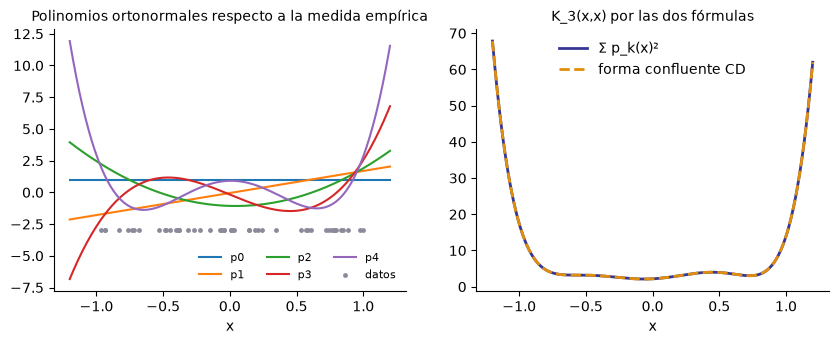

In [72]:
x1 = np.sort(rng.uniform(-1, 1, 50))[:, None]
n = 3
t1 = exponentes(1, n + 1)                                   # 1, x, ..., x^{n+1}
V1 = matriz_caracteristicas(x1, t1)
L1inv = np.linalg.inv(np.linalg.cholesky(matriz_momentos(V1)))   # (n+2) × (n+2), triangular inferior
C = L1inv                                                   # fila k = coeficientes de p_k en 1, x, x², ...
p = lambda z: C @ matriz_caracteristicas(np.atleast_2d(z).reshape(-1, 1), t1).T     # (n+2, m)
dp = lambda z: C[:, 1:] @ (np.arange(1, n + 2)[:, None] * np.atleast_1d(z)[None, :] ** np.arange(0, n + 1)[:, None])
kappa = np.diag(C)
a_n1 = kappa[n] / kappa[n + 1]

# recurrencia: coeficientes a_k, b_k como productos internos empíricos
Pd = p(x1[:, 0])
a_k = lambda k: np.mean(x1[:, 0] * Pd[k] * Pd[k - 1])
b_k = lambda k: np.mean(x1[:, 0] * Pd[k] ** 2)
zz = np.array([-1.7, -0.3, 0.45, 2.2])
Pz = p(zz)
verifica(np.allclose(zz * Pz[n], a_k(n + 1) * Pz[n + 1] + b_k(n) * Pz[n] + a_k(n) * Pz[n - 1]),
         f"recurrencia de tres términos para k = {n} (también fuera de los datos)")
verifica(np.isclose(a_k(n + 1), a_n1), "a_{n+1} = κ_n / κ_{n+1}")

xs, ys = np.array([0.3, -0.8, 1.4]), np.array([-0.5, 0.9, 0.2])
Kx = (p(xs)[: n + 1] * p(ys)[: n + 1]).sum(0)
CDf = a_n1 * (p(xs)[n + 1] * p(ys)[n] - p(xs)[n] * p(ys)[n + 1]) / (xs - ys)
verifica(np.allclose(Kx, CDf), "identidad de Christoffel–Darboux: Σ p_k(x)p_k(y) = a(p_{n+1}(x)p_n(y) − p_n(x)p_{n+1}(y))/(x − y)")
Kxx = (p(xs)[: n + 1] ** 2).sum(0)
conf = a_n1 * (dp(xs)[n + 1] * p(xs)[n] - dp(xs)[n] * p(xs)[n + 1])
verifica(np.allclose(Kxx, conf), "forma confluente: K_n(x,x) = a(p'_{n+1}p_n − p'_n p_{n+1})")
Mn = matriz_momentos(matriz_caracteristicas(x1, exponentes(1, n)))
vx = matriz_caracteristicas(xs[:, None], exponentes(1, n))
verifica(np.allclose(np.einsum("ij,jk,ik->i", vx, np.linalg.inv(Mn), vx), Kxx), "y coincide con v_n(x)ᵀ M_n⁻¹ v_n(x)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
zg = np.linspace(-1.2, 1.2, 300)
for k in range(n + 2):
    ax[0].plot(zg, p(zg)[k], label=f"p{k}")
ax[0].scatter(x1[:, 0], np.zeros(len(x1)) - 3, s=6, c=GRIS, label="datos")
ax[0].set_title("Polinomios ortonormales respecto a la medida empírica"); ax[0].set_xlabel("x"); ax[0].legend(ncol=3, fontsize=8)
ax[1].plot(zg, (p(zg)[: n + 1] ** 2).sum(0), color=AZUL, lw=2, label="Σ p_k(x)²")
ax[1].plot(zg, a_n1 * (dp(zg)[n + 1] * p(zg)[n] - dp(zg)[n] * p(zg)[n + 1]), "--", color=NARANJA, lw=2, label="forma confluente CD")
ax[1].set_title(f"K_{n}(x,x) por las dos fórmulas"); ax[1].set_xlabel("x"); ax[1].legend()
guardar(fig, "identidad_cd_1d", "2.5.2 Kernel CD e identidad de Christoffel–Darboux")
plt.show()

> **Para la tesis → 2.5.2 Kernel de Christoffel–Darboux y matriz de momentos**
>
> *Figura:* `identidad_cd_1d` — polinomios ortonormales de la medida empírica y K_n(x,x) por suma directa y por la identidad confluente.
>
> *Texto modelo:* En una variable, los polinomios ortonormales satisfacen una recurrencia de tres términos, de la que se deduce la identidad de Christoffel–Darboux: la suma de n + 1 productos p_k(x)p_k(y) se escribe con sólo p_n y p_{n+1}. En varias variables no existe una forma tan compacta, por lo que se usa la expresión matricial K_n(x,y) = v_n(x)ᵀM_n⁻¹v_n(y), equivalente a la suma sobre una base ortonormal.

## **1.7 Función de Christoffel y su formulación variacional**

**Definición.** $\Lambda_n(z)=1/K_n(z,z)$. Con $A=M_n+\varepsilon I$:
$$\Lambda_n(z)=\min_{a\in\mathbb R^s}\;\{a^\top A\,a\;:\;a^\top v_n(z)=1\},\qquad a^*=\frac{A^{-1}v_n(z)}{v_n(z)^\top A^{-1}v_n(z)}.$$

**Desarrollo.** Con un multiplicador de Lagrange, $2Aa=\lambda v$ ⇒ $a\propto A^{-1}v$; imponer $a^\top v=1$ da $a^*$ y el valor mínimo $1/(v^\top A^{-1}v)$.

**Intuición.** $\Lambda_n(z)$ es la **menor energía promedio** sobre los datos de un polinomio que vale 1 en $z$. Si $z$ está rodeado de datos, cualquier polinomio así es grande en muchos datos (energía alta, $\Lambda$ grande). Si $z$ está lejos, basta un polinomio que valga 1 en $z$ y casi 0 en los datos (energía baja, $\Lambda$ pequeña).

**Ejemplo a mano.** $X=\{-1,0,1\}$, $n=2$: $v=(1,x,x^2)$,
$$M=\begin{pmatrix}1&0&2/3\\0&2/3&0\\2/3&0&2/3\end{pmatrix},\qquad q(z)=3-\tfrac92 z^2+\tfrac92 z^4.$$

**M para X = {−1, 0, 1}, n = 2**

,1,x,x²
1,1.0000,0.0000,0.6667
x,0.0000,0.6667,0.0000
x²,0.6667,0.0000,0.6667


✔ q(z) = 3 − 4.5z² + 4.5z⁴
✔ a* cumple a*ᵀv = 1 y a*ᵀAa* = Λ(z)
✔ ningún otro polinomio con p(z) = 1 tiene menor energía (2000 pruebas)
[figura 02] 02_christoffel_1d_variacional.png  →  2.5.1 Definición y 2.5.3 Formulación variacional


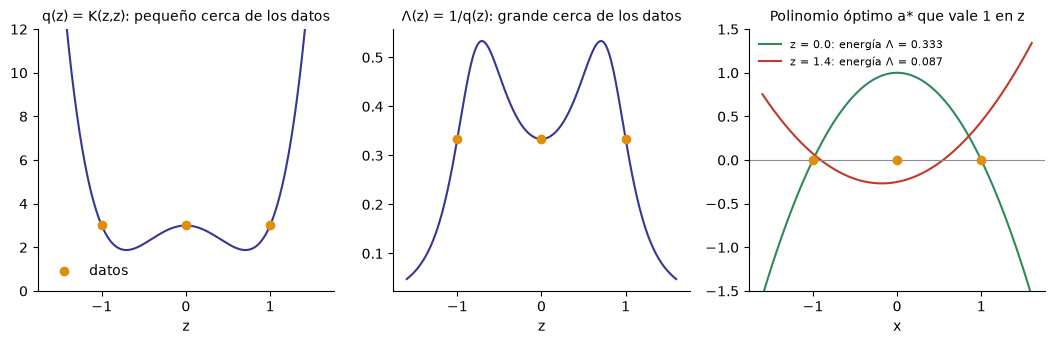

In [73]:
def normalizar(X):
    "Centra en la media y divide por el radio cuadrático medio. Devuelve (Y, centro, radio)."
    X = np.asarray(X, dtype=float)
    c = X.mean(0); Y = X - c
    r = float(np.sqrt((Y ** 2).sum(1).mean()))
    return Y / r, c, r

def ajustar_cd(X, n, reg=1e-8, base="monomial", w=None):
    "Modelo CD de una nube: base, M, ε = reg·tr(M)/s y factor de Cholesky de A = M + εI."
    X = np.asarray(X, dtype=float)
    d = X.shape[1]
    terms = exponentes(d, n)
    pesos = pesos_multinomiales(terms) if base == "weighted" else None
    M = matriz_momentos(matriz_caracteristicas(X, terms, pesos), w)
    s = len(M)
    eps = reg * np.trace(M) / s
    L = np.linalg.cholesky(M + eps * np.eye(s))
    return {"n": n, "d": d, "terms": terms, "pesos": pesos, "M": M, "eps": eps, "L": L, "s": s, "base": base}

def blanquear(mod, Z):
    "W = L⁻¹ v(Z)ᵀ  (s × m), por sustitución triangular: nunca se forma A⁻¹."
    return solve_triangular(mod["L"], matriz_caracteristicas(Z, mod["terms"], mod["pesos"]).T, lower=True)

def q_cd(mod, Z):
    W = blanquear(mod, Z)
    return np.einsum("ij,ij->j", W, W)          # ‖L⁻¹v(z)‖²  =  v(z)ᵀ A⁻¹ v(z)

def kernel_cd(mod, Z, Y=None):
    Wz = blanquear(mod, Z)
    return Wz.T @ (Wz if Y is None else blanquear(mod, Y))

def lambda_cd(mod, Z):
    return 1.0 / q_cd(mod, Z)

def pesos_multinomiales(terms):
    "√(k!/α!) por monomio (base ponderada, §1.12)."
    w = np.empty(len(terms))
    for j, t in enumerate(terms):
        cuentas = np.bincount(np.asarray(t, dtype=int)) if t else np.zeros(0, int)
        w[j] = np.sqrt(factorial(len(t)) / np.prod([factorial(int(c)) for c in cuentas]))
    return w

# --- ejemplo a mano ---
X1 = np.array([[-1.0], [0.0], [1.0]])
m1 = ajustar_cd(X1, 2, reg=0.0)
tabla(pd.DataFrame(m1["M"], index=["1", "x", "x²"], columns=["1", "x", "x²"]), 4, "M para X = {−1, 0, 1}, n = 2")
zg = np.linspace(-1.6, 1.6, 400)[:, None]
verifica(np.allclose(q_cd(m1, zg), 3 - 4.5 * zg[:, 0] ** 2 + 4.5 * zg[:, 0] ** 4), "q(z) = 3 − 4.5z² + 4.5z⁴")

# --- formulación variacional en 2D ---
X = rng.normal(size=(300, 2))
mv = ajustar_cd(X, 2, reg=1e-6)
A = mv["M"] + mv["eps"] * np.eye(mv["s"])
z0 = np.array([[0.8, -1.5]])
v0 = matriz_caracteristicas(z0, mv["terms"])[0]
a_opt = np.linalg.solve(A, v0); a_opt /= v0 @ a_opt
verifica(np.isclose(a_opt @ v0, 1) and np.isclose(a_opt @ A @ a_opt, lambda_cd(mv, z0)[0]), "a* cumple a*ᵀv = 1 y a*ᵀAa* = Λ(z)")
Pnull = np.eye(len(v0)) - np.outer(v0, v0) / (v0 @ v0)
otros = np.array([a_opt + Pnull @ rng.normal(size=len(v0)) for _ in range(2000)])
verifica(np.einsum("ij,jk,ik->i", otros, A, otros).min() >= a_opt @ A @ a_opt - 1e-12,
         "ningún otro polinomio con p(z) = 1 tiene menor energía (2000 pruebas)")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(zg, q_cd(m1, zg), color=AZUL); ax[0].scatter(X1[:, 0], q_cd(m1, X1), c=NARANJA, zorder=3, label="datos")
ax[0].set_ylim(0, 12); ax[0].set_title("q(z) = K(z,z): pequeño cerca de los datos"); ax[0].set_xlabel("z"); ax[0].legend()
ax[1].plot(zg, lambda_cd(m1, zg), color=AZUL); ax[1].scatter(X1[:, 0], lambda_cd(m1, X1), c=NARANJA, zorder=3)
ax[1].set_title("Λ(z) = 1/q(z): grande cerca de los datos"); ax[1].set_xlabel("z")
for zc, col in ((0.0, VERDE), (1.4, ROJO)):
    vz = matriz_caracteristicas(np.array([[zc]]), m1["terms"])[0]
    ao = np.linalg.solve(m1["M"], vz); ao /= vz @ ao
    ax[2].plot(zg, matriz_caracteristicas(zg, m1["terms"]) @ ao, color=col, label=f"z = {zc}: energía Λ = {1 / (vz @ np.linalg.solve(m1['M'], vz)):.3f}")
ax[2].scatter(X1[:, 0], np.zeros(3), c=NARANJA, zorder=3); ax[2].axhline(0, color=GRIS, lw=.8)
ax[2].set_ylim(-1.5, 1.5); ax[2].set_title("Polinomio óptimo a* que vale 1 en z"); ax[2].set_xlabel("x"); ax[2].legend(fontsize=8)
guardar(fig, "christoffel_1d_variacional", "2.5.1 Definición y 2.5.3 Formulación variacional")
plt.show()

**Interpretación de la figura.** A la izquierda, $q$ vale exactamente 3 (= $s$) en cada dato y crece como $z^4$ fuera de $[-1,1]$. Al centro, $\Lambda=1/q$ es máxima en los datos. A la derecha, el polinomio óptimo para $z=0$ (dentro de los datos) debe valer 1 en un dato y por eso tiene energía alta ($\Lambda=1/3$); para $z=1.4$ (fuera) puede valer 1 en $z$ y ser pequeño en los tres datos, con energía mucho menor.

> **Para la tesis → 2.5.1 Definición (corrige el sentido de Λ) y 2.5.3 Formulación variacional**
>
> *Figura:* `christoffel_1d_variacional`.
>
> *Texto modelo:* Λ_n(z) es la menor energía promedio sobre los datos de un polinomio de grado n que vale 1 en z. Para X = {−1, 0, 1} y n = 2, q(z) = 3 − 4.5z² + 4.5z⁴ vale 3 en cada dato y crece como z⁴ fuera del intervalo; por tanto Λ es máxima sobre los datos y tiende a cero lejos de ellos.

## **1.8 Propiedades que se usan como comprobación**

1. **Identidad de traza.** Con $\varepsilon=0$: $\frac1N\sum_i q_n(x_i)=\operatorname{tr}(M_n^{-1}M_n)=s$. Con $\varepsilon>0$: $\frac1N\sum_i q_n(x_i)=\sum_j \eta_j/(\eta_j+\varepsilon)\le s$ (grados de libertad efectivos; $\eta_j$ valores propios de $M_n$).
2. **Grado 1 = Mahalanobis.** $q_1(x)=1+(x-\mu)^\top\Sigma^{-1}(x-\mu)$, con $\Sigma$ la covarianza con divisor $N$.
3. **Invariancia afín (sin regularización).** El espacio de polinomios de grado $\le n$ no cambia bajo $x\mapsto Bx+b$ invertible; por eso $q_n$ calculado sobre los datos transformados, evaluado en el punto transformado, es igual al original.

In [74]:
X = rng.normal(size=(400, 2)) @ np.array([[2.0, 0.3], [0.0, 0.5]]) + [3.0, -1.0]
m0 = ajustar_cd(X, 3, reg=0.0)
verifica(np.isclose(q_cd(m0, X).mean(), m0["s"]), f"identidad de traza: promedio de q en los datos = s = {m0['s']}")
mr = ajustar_cd(X, 3, reg=1e-3)
eta = np.linalg.eigvalsh(mr["M"])
verifica(np.isclose(q_cd(mr, X).mean(), np.sum(eta / (eta + mr["eps"]))), "con ε > 0: promedio de q = Σ η/(η + ε)  (grados de libertad efectivos)")

m_1 = ajustar_cd(X, 1, reg=0.0)
mu, S = X.mean(0), np.cov(X.T, bias=True)
maha = np.einsum("ij,jk,ik->i", X - mu, np.linalg.inv(S), X - mu)
verifica(np.allclose(q_cd(m_1, X), 1 + maha), "grado 1: q(x) = 1 + distancia de Mahalanobis²")

B, b = np.array([[0.4, 1.3], [-2.0, 0.7]]), np.array([5.0, 2.0])
Zq = rng.normal(size=(20, 2)) * 3
mA = ajustar_cd(X @ B.T + b, 3, reg=0.0)
verifica(np.allclose(q_cd(mA, Zq @ B.T + b), q_cd(m0, Zq), rtol=1e-6), "invariancia afín: q calculado sobre BX + b en Bz + b = q(z)")

✔ identidad de traza: promedio de q en los datos = s = 10
✔ con ε > 0: promedio de q = Σ η/(η + ε)  (grados de libertad efectivos)
✔ grado 1: q(x) = 1 + distancia de Mahalanobis²
✔ invariancia afín: q calculado sobre BX + b en Bz + b = q(z)


## **1.9 Regularización y condicionamiento numérico**

**Problema 1: singularidad.** Si los datos satisfacen una ecuación polinomial $f(x)=0$ con $\deg f\le n$, el vector de coeficientes de $f$ está en el núcleo de $M_n$ ($a^\top M a=\overline{f^2}=0$). Ejemplo: la circunferencia unitaria con $n=2$ ($x^2+y^2-1=0$, rango 5 de 6).

**Problema 2: condicionamiento.** Aunque $M_n$ sea invertible, su número de condición $\kappa(M_n)=\eta_{\max}/\eta_{\min}$ crece muy rápido con $n$ (los monomios de grado alto son casi colineales). En doble precisión se pierden $\log_{10}\kappa$ dígitos de 16.

**Solución adoptada.**
* Normalizar la nube (centro y radio cuadrático medio = 1) antes de construir la base.
* Regularizar: $A=M_n+\varepsilon I$, con $\varepsilon=c\,\operatorname{tr}(M_n)/s$ ($c$ relativo, independiente de la escala de los datos).
* Factorizar $A=LL^\top$ (Cholesky) y calcular $q(z)=\|L^{-1}v(z)\|^2$ con sustitución triangular.

**Por qué no la pseudoinversa.** `pinv` descarta justamente las direcciones casi nulas de $M_n$, que son las ecuaciones que describen el soporte; el resultado trata puntos fuera del soporte como típicos.

[figura 03] 03_condicionamiento_regularizacion.png  →  2.5.4 Singularidad y regularización


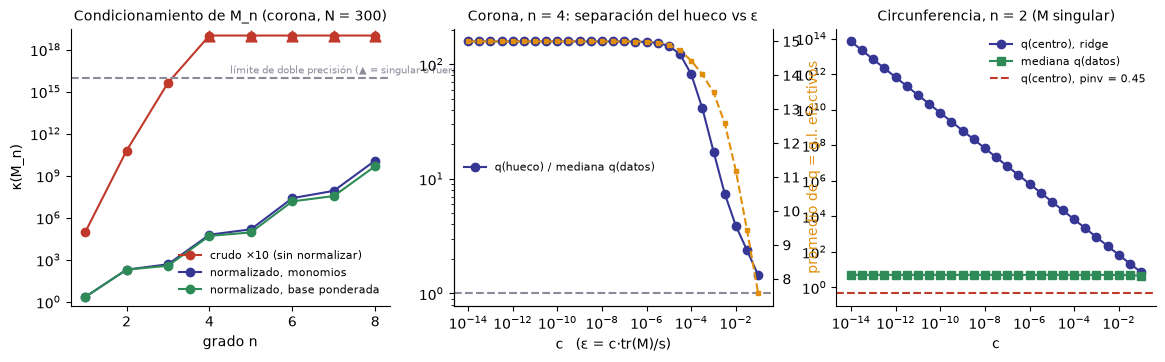

✔ circunferencia, n = 2: rango(M) = 5 de 6
✔ pinv: el centro obtiene q MENOR que los datos (incorrecto)
✔ ridge (c = 0.01): el centro queda fuera del soporte (q > 50)


**κ(M_n) por grado**

caso,crudo ×10 (sin normalizar),"normalizado, base ponderada","normalizado, monomios"
grado,,,
1,9.0e+04,2.2e+00,2.2e+00
2,6.1e+10,2.0e+02,2.0e+02
3,4.3e+15,3.7e+02,4.8e+02
4,inf,5.1e+04,6.2e+04
5,inf,9.0e+04,1.5e+05
6,inf,1.5e+07,2.5e+07
7,inf,3.5e+07,8.3e+07
8,inf,4.8e+09,1.2e+10


In [75]:
from pointfield.geometry.shapes2d import Annulus, Circle
anillo = Annulus(0.75, 1.0).sample(300, seed=0)
anillo_n, _, _ = normalizar(anillo)
grados = range(1, 9)
filas = []
for n in grados:
    for nombre, Xb, base in (("crudo ×10 (sin normalizar)", anillo * 10 + 30, "monomial"),
                             ("normalizado, monomios", anillo_n, "monomial"),
                             ("normalizado, base ponderada", anillo_n, "weighted")):
        terms = exponentes(2, n)
        Mb = matriz_momentos(matriz_caracteristicas(Xb, terms, pesos_multinomiales(terms) if base == "weighted" else None))
        e = np.linalg.eigvalsh(Mb)
        k_ = e.max() / e.min() if e.min() > 0 else np.inf      # min ≤ 0: numéricamente singular
        filas.append({"grado": n, "caso": nombre, "kappa": k_, "s": len(terms)})
kap = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for (nombre, g), col in zip(kap.groupby("caso", sort=False), (ROJO, AZUL, VERDE)):
    kk = np.minimum(g.kappa, 1e19)
    ax[0].semilogy(g.grado, kk, "o-", color=col, label=nombre)
    fuera = g.kappa >= 1e19
    ax[0].scatter(g.grado[fuera], kk[fuera], marker="^", s=60, color=col, zorder=3)
ax[0].set_ylim(0.5, 3e19)
ax[0].axhline(1e16, ls="--", color=GRIS); ax[0].text(4.5, 2e16, "límite de doble precisión (▲ = singular o fuera de escala)", fontsize=7, color=GRIS)
ax[0].set_xlabel("grado n"); ax[0].set_ylabel("κ(M_n)"); ax[0].set_title("Condicionamiento de M_n (corona, N = 300)"); ax[0].legend(fontsize=8)

# Sensibilidad a la regularización: corona n = 4 y circunferencia n = 2
regs = np.logspace(-14, -1, 27)
hueco = np.zeros((1, 2))
razon, dof = [], []
for c in regs:
    m = ajustar_cd(anillo_n, 4, reg=c)
    qd = q_cd(m, anillo_n)
    razon.append(q_cd(m, hueco)[0] / np.median(qd)); dof.append(qd.mean())
ax[1].loglog(regs, razon, "o-", color=AZUL, label="q(hueco) / mediana q(datos)")
ax[1].axhline(1, color=GRIS, ls="--"); ax[1].set_xlabel("c   (ε = c·tr(M)/s)"); ax[1].set_title("Corona, n = 4: separación del hueco vs ε")
ax2 = ax[1].twinx(); ax2.semilogx(regs, dof, "s--", color=NARANJA, ms=3); ax2.set_ylabel("promedio de q = g.l. efectivos", color=NARANJA)
ax2.spines["right"].set_visible(True); ax[1].legend(fontsize=8, loc="center left")

circ = Circle(1.0).sample(400, seed=0)
qc = []
for c in regs:
    m = ajustar_cd(circ, 2, reg=c, base="weighted")
    qc.append((q_cd(m, hueco)[0], np.median(q_cd(m, circ))))
qc = np.array(qc)
mc0 = matriz_momentos(matriz_caracteristicas(circ, exponentes(2, 2), pesos_multinomiales(exponentes(2, 2))))
v_o = matriz_caracteristicas(hueco, exponentes(2, 2), pesos_multinomiales(exponentes(2, 2)))
q_pinv = (v_o @ np.linalg.pinv(mc0) @ v_o.T)[0, 0]
ax[2].loglog(regs, qc[:, 0], "o-", color=AZUL, label="q(centro), ridge")
ax[2].loglog(regs, qc[:, 1], "s-", color=VERDE, label="mediana q(datos)")
ax[2].axhline(q_pinv, color=ROJO, ls="--", label=f"q(centro), pinv = {q_pinv:.2f}")
ax[2].set_xlabel("c"); ax[2].set_title("Circunferencia, n = 2 (M singular)"); ax[2].legend(fontsize=8)
guardar(fig, "condicionamiento_regularizacion", "2.5.4 Singularidad y regularización")
plt.show()

verifica(np.linalg.matrix_rank(mc0, tol=1e-10) == 5, "circunferencia, n = 2: rango(M) = 5 de 6")
verifica(q_pinv < np.median(q_cd(ajustar_cd(circ, 2, 0.01, "weighted"), circ)), "pinv: el centro obtiene q MENOR que los datos (incorrecto)")
verifica(q_cd(ajustar_cd(circ, 2, 0.01, "weighted"), hueco)[0] > 50, "ridge (c = 0.01): el centro queda fuera del soporte (q > 50)")
tabla(formato(kap.pivot(index="grado", columns="caso", values="kappa"), "{:.1e}"), titulo="κ(M_n) por grado")

**Interpretación.**
* *Izquierda:* sin normalizar, $\kappa$ alcanza $10^{15}$ en grado 3 y desde grado 4 la matriz es numéricamente singular (triángulos). Normalizar gana muchos órdenes de magnitud; la base ponderada mejora ligeramente más.
* *Centro:* con la corona y $n=4$, la separación del hueco es estable para $c$ entre $10^{-12}$ y $\sim10^{-4}$ y se pierde cuando $\varepsilon$ domina ($c\to10^{-1}$): una regularización excesiva vuelve a $q$ casi constante. Los grados de libertad efectivos (promedio de $q$) bajan de $s=15$ conforme crece $c$.
* *Derecha:* en la circunferencia, cualquier $c>0$ deja el centro claramente por encima de los datos, mientras que `pinv` lo pone por debajo.

En la tesis se usa $c=10^{-8}$ para los diagnósticos de soporte 2D, $c=10^{-6}$ en el agrupamiento y $c=0.01$ en el descriptor de objetos (donde $M$ es singular por construcción: los objetos son superficies).

## **1.10 Implementación estable final y comprobación contra la biblioteca**

Las funciones `ajustar_cd`, `q_cd`, `kernel_cd` y `lambda_cd` de §1.7 son la implementación completa. Aquí se comprueba que dan lo mismo que la clase `ChristoffelDarboux` que usan los scripts de `benchmarks/` (con ambas bases, con pesos, en 2D y 3D), y que Cholesky coincide con la inversa explícita.

In [76]:
from pointfield.learning import ChristoffelDarboux
for d, n, base, reg in [(2, 4, "monomial", 1e-8), (3, 2, "weighted", 0.01), (3, 3, "monomial", 1e-6)]:
    Xt = rng.normal(size=(300, d)); Zt = rng.normal(size=(40, d)) * 2
    w = rng.uniform(0.2, 1.0, 300)
    for ww in (None, w):
        mio = ajustar_cd(Xt, n, reg, base, ww)
        lib = ChristoffelDarboux(n, reg, basis=base).fit(Xt, ww)
        verifica(np.allclose(q_cd(mio, Zt), lib.score(Zt), rtol=1e-9) and np.allclose(kernel_cd(mio, Zt), lib.kernel(Zt), rtol=1e-8, atol=1e-10),
                 f"d={d}, n={n}, base={base}, pesos={'sí' if ww is not None else 'no'}: q y K desde cero = biblioteca")
mio = ajustar_cd(Xt, 3, 1e-6)
Vt = matriz_caracteristicas(Zt, mio["terms"])
ref = np.einsum("ij,jk,ik->i", Vt, np.linalg.inv(mio["M"] + mio["eps"] * np.eye(mio["s"])), Vt)
verifica(np.max(np.abs(q_cd(mio, Zt) - ref) / ref) < 1e-8, "Cholesky = inversa explícita (error relativo < 1e-8)")

✔ d=2, n=4, base=monomial, pesos=no: q y K desde cero = biblioteca
✔ d=2, n=4, base=monomial, pesos=sí: q y K desde cero = biblioteca
✔ d=3, n=2, base=weighted, pesos=no: q y K desde cero = biblioteca
✔ d=3, n=2, base=weighted, pesos=sí: q y K desde cero = biblioteca
✔ d=3, n=3, base=monomial, pesos=no: q y K desde cero = biblioteca
✔ d=3, n=3, base=monomial, pesos=sí: q y K desde cero = biblioteca
✔ Cholesky = inversa explícita (error relativo < 1e-8)


## **1.11 Interpretación geométrica: conjuntos de nivel y soporte**

**Idea.** El conjunto $S_\gamma=\{z:\;q_n(z)\le\gamma\}$ con $\gamma$ = percentil 97 de $q_n$ sobre los datos es una estimación polinomial del **soporte** de la nube. Se dibuja $\log_{10}q_n$ como mapa de calor y la curva $q_n=\gamma$ en naranja.

**Qué evalúa.** Si un polinomio de grado $n$ sobre **toda** la nube (sin etiquetas) captura huecos, concavidades y componentes separadas. Se usa $n=4$ en los seis escenarios 2D de la tesis (definidos en §2).

[figura 04] 04_campos_q_escenarios.png  →  5.1 Estimación de soporte (escenarios)


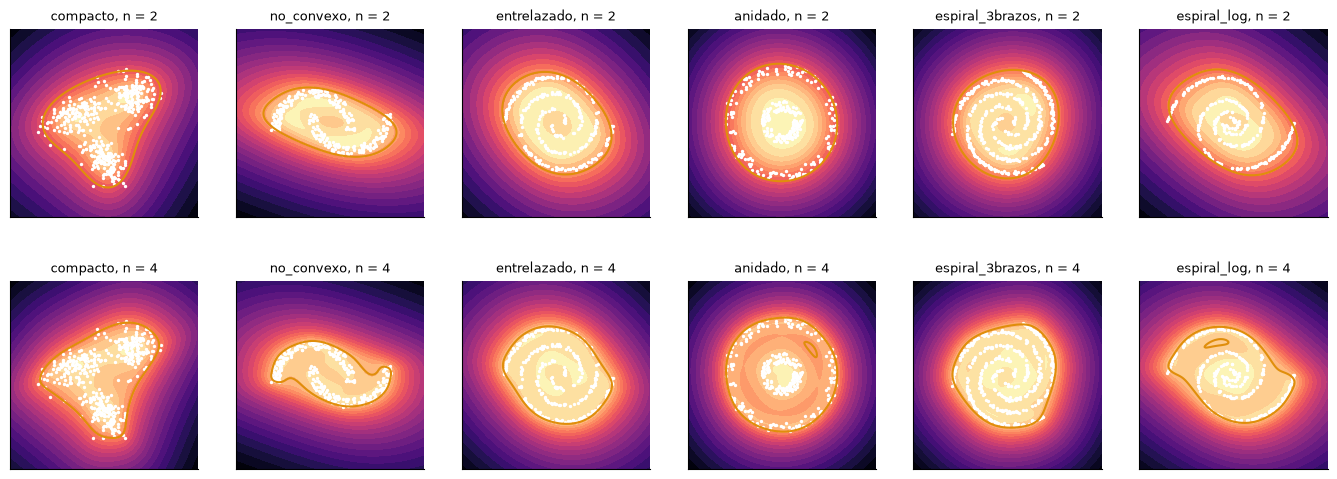

In [77]:
from pointfield.datasets import make as _make_escenario
CASOS_2D = ["compacto", "no_convexo", "entrelazado", "anidado", "espiral_3brazos", "espiral_log"]

def malla(lim=2.4, res=220):
    g = np.linspace(-lim, lim, res); GX, GY = np.meshgrid(g, g)
    return GX, GY, np.column_stack([GX.ravel(), GY.ravel()])

def dibujar_campo(ax, mod, X, y=None, lim=2.4, percentil=97, titulo=""):
    GX, GY, G = malla(lim)
    Q = q_cd(mod, G).reshape(GX.shape)
    nivel = np.percentile(q_cd(mod, X), percentil)
    ax.contourf(GX, GY, np.log10(Q), levels=24, cmap="magma_r")
    ax.contour(GX, GY, Q, levels=[nivel], colors=[NARANJA], linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], s=2, c="white" if y is None else y, cmap="cool" if y is not None else None)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(titulo, fontsize=9)

fig, ax = plt.subplots(2, 6, figsize=(17, 6))
for j, caso in enumerate(CASOS_2D):
    Xc_, _, _ = normalizar(_make_escenario(caso, 150, seed=100).X)
    for i, n in enumerate((2, 4)):
        dibujar_campo(ax[i, j], ajustar_cd(Xc_, n, 1e-8), Xc_, titulo=f"{caso}, n = {n}")
guardar(fig, "campos_q_escenarios", "5.1 Estimación de soporte (escenarios)")
plt.show()

**Interpretación.** Con $n=2$ el soporte es una cónica (elipse o región entre cónicas): sólo separa el anillo interior en `anidado`. Con $n=4$ la curva de nivel ya sigue las concavidades de las lunas y empieza a marcar el hueco entre los anillos, pero **un único polinomio no separa los brazos de las espirales**: el soporte de los brazos entrelazados es una región conectada a escala del grado. Esta observación motiva que el agrupamiento con CD sea **local** (§4).

**Detección de atípicos en un toro 3D (150 puntos uniformes en la caja, sin etiquetas para ajustar)**

,s,AUC (q como puntaje de atípico)
grado,,
1,4,0.595
2,10,0.622
4,35,0.664
6,84,0.808


[figura 05] 05_toro_campo_atipicos.png  →  2.6 Aplicaciones (soporte y anomalías en 3D)


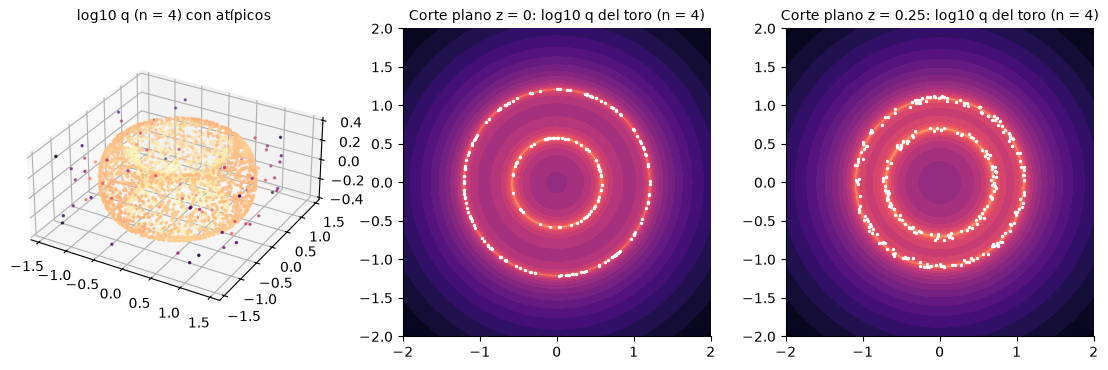

✔ grado 4 detecta atípicos mejor que grado 1 (Mahalanobis)


In [78]:
from pointfield.geometry.shapes3d import Torus
toro, _, _ = normalizar(Torus(1.0, 0.35).sample(3000, seed=0))
r3 = np.random.default_rng(1)
atipicos = r3.uniform(toro.min(0) * 1.2, toro.max(0) * 1.2, size=(150, 3))
Xo = np.vstack([toro, atipicos]); yo = np.r_[np.zeros(len(toro)), np.ones(len(atipicos))]
from sklearn.metrics import roc_auc_score
filas = []
for n in (1, 2, 4, 6):
    m = ajustar_cd(Xo, n, 1e-8)
    filas.append({"grado": n, "s": m["s"], "AUC (q como puntaje de atípico)": roc_auc_score(yo, q_cd(m, Xo))})
auc = pd.DataFrame(filas).set_index("grado")
tabla(auc, 3, "Detección de atípicos en un toro 3D (150 puntos uniformes en la caja, sin etiquetas para ajustar)")

m4 = ajustar_cd(toro, 4, 1e-8)
fig = plt.figure(figsize=(14, 4))
a1 = fig.add_subplot(1, 3, 1, projection="3d")
sc = a1.scatter(*Xo.T, c=np.log10(q_cd(ajustar_cd(Xo, 4, 1e-8), Xo)), s=2, cmap="magma_r")
a1.set_title("log10 q (n = 4) con atípicos"); a1.set_box_aspect((1, 1, 0.45))
g = np.linspace(-2, 2, 200); GX, GY = np.meshgrid(g, g)
for k, (zc, nombre) in enumerate(((0.0, "plano z = 0"), (0.25, "plano z = 0.25"))):
    a = fig.add_subplot(1, 3, k + 2)
    Q = q_cd(m4, np.column_stack([GX.ravel(), GY.ravel(), np.full(GX.size, zc)])).reshape(GX.shape)
    a.contourf(GX, GY, np.log10(Q), levels=24, cmap="magma_r")
    cerca = np.abs(toro[:, 2] - zc) < 0.03
    a.scatter(toro[cerca, 0], toro[cerca, 1], s=2, c="white")
    a.set_aspect("equal"); a.set_title(f"Corte {nombre}: log10 q del toro (n = 4)")
guardar(fig, "toro_campo_atipicos", "2.6 Aplicaciones (soporte y anomalías en 3D)")
plt.show()
verifica(auc.loc[4].iloc[1] > auc.loc[1].iloc[1], "grado 4 detecta atípicos mejor que grado 1 (Mahalanobis)")

**Interpretación.** El corte $z=0$ muestra que $q_4$ es bajo sobre la superficie del toro y alto en el agujero central y fuera del toro: el polinomio "ve" la forma. Como puntaje de atípico, el AUC crece con el grado (tabla de arriba): con grado 1 (Mahalanobis) sólo se mide la distancia al centro, y los atípicos dentro de la caja pero lejos de la superficie sólo se detectan con un soporte no elipsoidal.

## **1.12 Representación de distribuciones**

**Resultado teórico (Lasserre, Pauwels y Putinar, 2022).** Cuando $N\to\infty$ y luego $n\to\infty$, $s_n\Lambda_n(x)$ converge (en el interior del soporte) al cociente entre la densidad de los datos y la densidad de la medida de equilibrio del soporte. En consecuencia, $\Lambda_n$ refleja **el soporte y, dentro de él, la variación de densidad**, pero no es una densidad: depende de la forma del soporte y del grado.

**Experimento.** Mezcla 1D de dos gaussianas; se comparan $\Lambda_n$ (escalada a máximo 1) con el histograma para $n=2,4,8$.

[figura 06] 06_lambda_distribucion_1d.png  →  2.5.5 Interpretación geométrica


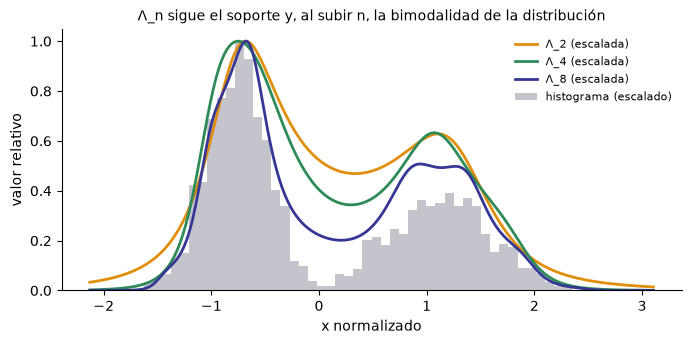

In [79]:
x_mix = np.r_[rng.normal(-1.0, 0.3, 1200), rng.normal(1.0, 0.5, 800)][:, None]
x_mix_n, c_mix, r_mix = normalizar(x_mix)
zg = np.linspace(x_mix_n.min() - 0.5, x_mix_n.max() + 0.5, 400)[:, None]
fig, ax = plt.subplots(figsize=(8, 3.4))
h, b = np.histogram(x_mix_n[:, 0], bins=50, density=True)
ax.bar((b[:-1] + b[1:]) / 2, h / h.max(), width=b[1] - b[0], color=GRIS, alpha=.5, label="histograma (escalado)")
for n, col in ((2, NARANJA), (4, VERDE), (8, AZUL)):
    lam = lambda_cd(ajustar_cd(x_mix_n, n, 1e-10), zg)
    ax.plot(zg, lam / lam.max(), color=col, lw=2, label=f"Λ_{n} (escalada)")
ax.set_xlabel("x normalizado"); ax.set_ylabel("valor relativo"); ax.legend(fontsize=8)
ax.set_title("Λ_n sigue el soporte y, al subir n, la bimodalidad de la distribución")
guardar(fig, "lambda_distribucion_1d", "2.5.5 Interpretación geométrica")
plt.show()

**Interpretación.** Desde $n=2$ ya hay dos máximos ($q_2$ es un polinomio de grado 4), pero el valle entre las modas sólo se profundiza al subir el grado, acercándose al del histograma. Las alturas relativas no coinciden con el histograma: $\Lambda_n$ mezcla densidad y geometría del soporte, como predice la teoría.

## **1.13 Base ponderada e invariancia a rotaciones**

**Definición.** Cada monomio $x^\alpha$ de grado $k=|\alpha|$ se multiplica por $w_\alpha=\sqrt{k!/\alpha!}$, con $\alpha!=\prod_j\alpha_j!$.

**Desarrollo.** Por el teorema multinomial, $(x^\top y)^k=\sum_{|\alpha|=k}\frac{k!}{\alpha!}x^\alpha y^\alpha=\langle\phi_k(x),\phi_k(y)\rangle$ con $\phi_k=(w_\alpha x^\alpha)_{|\alpha|=k}$. Como $(Rx)^\top(Ry)=x^\top y$ para $R$ ortogonal, existe $U(R)$ ortogonal con $\phi(Rx)=U(R)\phi(x)$, así que $M\mapsto UMU^\top$: **los valores propios de $M$ y $q$ (aun con $\varepsilon I$) no cambian** al rotar o reflejar la nube centrada. Con monomios sin peso, $\varepsilon I$ rompe esa propiedad y el espectro cambia.

In [80]:
from pointfield.core.pose import random_rotation
x, y = rng.normal(size=(2, 3))
for k in (1, 2, 3, 4):
    t = [e for e in exponentes(3, k) if len(e) == k]
    w = pesos_multinomiales(t)
    verifica(np.isclose(matriz_caracteristicas(x[None], t, w)[0] @ matriz_caracteristicas(y[None], t, w)[0], (x @ y) ** k),
             f"bloque de grado {k}: ⟨φ_k(x), φ_k(y)⟩ = (xᵀy)^{k}")

Xe = rng.normal(size=(400, 3)) * [2.0, 1.0, 0.4]
R = random_rotation(3, seed=5); R[:, 0] *= -1        # rotación + reflexión
Zq = rng.normal(size=(30, 3))
res = []
for base in ("weighted", "monomial"):
    a, b = ajustar_cd(Xe, 2, 0.01, base), ajustar_cd(Xe @ R.T, 2, 0.01, base)
    res.append({"base": base,
                "cambio máx. del espectro": np.max(np.abs(np.linalg.eigvalsh(a["M"]) - np.linalg.eigvalsh(b["M"]))),
                "cambio relativo máx. de q (ε > 0)": np.max(np.abs(q_cd(a, Zq) - q_cd(b, Zq @ R.T)) / q_cd(a, Zq))})
inv = pd.DataFrame(res).set_index("base")
tabla(formato(inv, "{:.1e}"), titulo="Efecto de una rotación con reflexión (n = 2, c = 0.01)")
verifica(inv.loc["weighted"].max() < 1e-10 and inv.loc["monomial"].max() > 1e-4, "sólo la base ponderada es invariante a O(3) con regularización")

✔ bloque de grado 1: ⟨φ_k(x), φ_k(y)⟩ = (xᵀy)^1
✔ bloque de grado 2: ⟨φ_k(x), φ_k(y)⟩ = (xᵀy)^2
✔ bloque de grado 3: ⟨φ_k(x), φ_k(y)⟩ = (xᵀy)^3
✔ bloque de grado 4: ⟨φ_k(x), φ_k(y)⟩ = (xᵀy)^4


**Efecto de una rotación con reflexión (n = 2, c = 0.01)**

,cambio máx. del espectro,cambio relativo máx. de q (ε > 0)
base,,
weighted,5.7e-14,4.2e-14
monomial,1.6e+01,7.8e-02


✔ sólo la base ponderada es invariante a O(3) con regularización


> **Para la tesis → 4.3 Cálculo estable (base ponderada) y 4.5 Descriptor invariante**
>
> *Texto modelo:* Cada monomio x^α de grado k se escala por √(k!/α!). Por el teorema multinomial, el producto interno de dos bloques de grado k es (xᵀy)^k, de modo que una rotación o reflexión de la nube centrada sólo rota la base: el espectro de M y la función q no cambian, incluso con la regularización εI. Con monomios sin escalar el espectro cambia hasta en 10⁻⁴–10⁻¹.

## **1.14 De la función de Christoffel a embeddings y agrupamiento**

La función de Christoffel produce, para una nube, (a) un **campo escalar** $q_n(z)$ y (b) un **núcleo** $K_n(x,y)$ entre puntos. Hay dos maneras naturales de usarlos para representar y agrupar:

1. **Núcleo global.** Usar $K_n$ (o su versión normalizada $\tilde K(x,y)=K(x,y)/\sqrt{q(x)q(y)}\in[-1,1]$) como matriz de similitud y hacer *kernel PCA*. Es un embedding de dimensión $\le s$ (el rango de $K$).
2. **Modelos locales.** Ajustar un modelo CD por vecindad y usarlo para definir un grafo de afinidad, que después se embebe espectralmente (mejora 1, §4.2).

Aquí se prueba la opción 1 en las dos lunas para mostrar por qué la tesis optó por la opción 2.

[figura 07] 07_embedding_global_vs_local.png  →  4.4 Agrupamiento basado en CD (motivación)


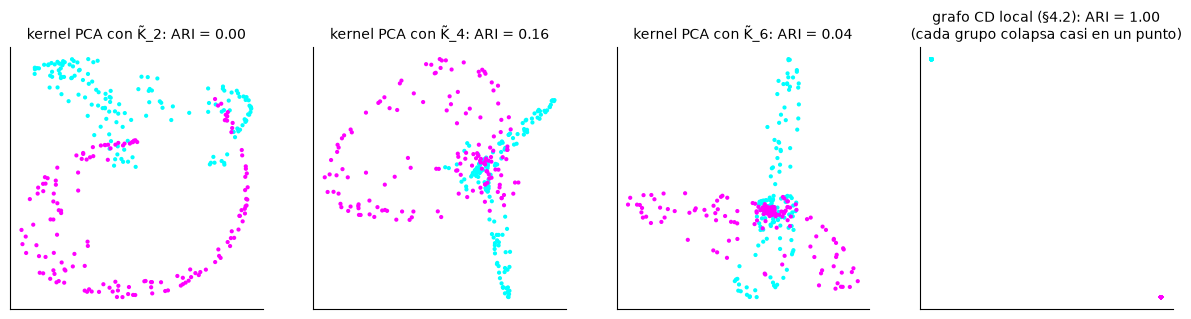

**Embedding con el núcleo CD global (dos lunas, semilla 100)**

,rango de K,ARI (K-Means sobre el embedding)
grado,,
2,6,0.000
4,15,0.158
6,28,0.038


In [81]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
ds_l = _make_escenario("no_convexo", 150, seed=100)
Xl, _, _ = normalizar(ds_l.X)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
filas = []
for j, n in enumerate((2, 4, 6)):
    mod = ajustar_cd(Xl, n, 1e-8)
    K = kernel_cd(mod, Xl); qv = np.diag(K)
    Kt = K / np.sqrt(np.outer(qv, qv))
    H = np.eye(len(Xl)) - 1 / len(Xl)
    w_, U_ = np.linalg.eigh(H @ Kt @ H)
    E = U_[:, ::-1][:, :2] * np.sqrt(np.maximum(w_[::-1][:2], 0))
    ari = adjusted_rand_score(ds_l.y, KMeans(2, n_init=10, random_state=0).fit_predict(E))
    filas.append({"grado": n, "rango de K": int(np.linalg.matrix_rank(K)), "ARI (K-Means sobre el embedding)": ari})
    ax[j].scatter(E[:, 0], E[:, 1], c=ds_l.y, cmap="cool", s=4); ax[j].set_title(f"kernel PCA con K̃_{n}: ARI = {ari:.2f}")
from pointfield.learning import CDLocalSpectral
modelo_loc = CDLocalSpectral(2, n_neighbors=CONFIG["K_VECINOS"], degree=1)
ari_loc = adjusted_rand_score(ds_l.y, modelo_loc.fit_predict(Xl))
E_loc = modelo_loc.embedding_            # embedding espectral (2 vectores, filas normalizadas) usado por K-Means
ax[3].scatter(E_loc[:, 0], E_loc[:, 1], c=ds_l.y, cmap="cool", s=4); ax[3].set_title(f"grafo CD local (§4.2): ARI = {ari_loc:.2f}\n(cada grupo colapsa casi en un punto)")
for a in ax: a.set_xticks([]); a.set_yticks([])
guardar(fig, "embedding_global_vs_local", "4.4 Agrupamiento basado en CD (motivación)")
plt.show()
tabla(pd.DataFrame(filas).set_index("grado"), 3, "Embedding con el núcleo CD global (dos lunas, semilla 100)")

**Interpretación.** El núcleo global de grado $n$ tiene rango a lo sumo $s$ y codifica la nube como un todo: sus primeras componentes describen la forma global, no la separación entre las lunas, y K-Means sobre ellas no recupera los grupos. El grafo construido con modelos CD **locales** sí separa las lunas. Esta es la razón por la que la versión final del agrupamiento usa CD localmente (§4).

---
# **2. Datos sintéticos 2D y 3D con `point-field`**

Todos los conjuntos se generan con la biblioteca `point-field` (geometrías primitivas + poses + perturbaciones), de modo que cada uno se reconstruye exactamente a partir de `(nombre, n, semilla)`. Las etiquetas reales se guardan **sólo para evaluar**; ningún método las ve.

## **2.1 Escenarios 2D de agrupamiento**

| Escenario | Definición geométrica (`pointfield.datasets`) | Grupos | Qué propiedad evalúa |
|---|---|---|---|
| `compacto` | 3 gaussianas anisotrópicas casi en contacto: σ = (0.55, 0.30) rot. 0.5 en (0, 0); σ = (0.35, 0.35) en (1.9, 0.6); σ = (0.45, 0.25) rot. −0.9 en (0.9, −1.5) | 3 | grupos convexos que se tocan: caso favorable a K-Means |
| `no_convexo` | 2 medias lunas (`Crescent`, radio 1, grosor 0.25, arco π), la segunda girada π y trasladada (1.0, 0.45) | 2 | concavidad: separar sin suponer convexidad |
| `entrelazado` | 2 brazos de espiral arquimediana r = 0.5 + 0.5θ, 1.5 vueltas, grosor 0.08, fases 0 y π | 2 | estructura enrollada: vecindad local vs. distancia global |
| `anidado` | 2 coronas concéntricas (`Annulus`) radios 0.30–0.55 y 1.25–1.50 | 2 | grupos anidados, no linealmente separables |
| `espiral_3brazos` *(reservado)* | 3 brazos arquimedianos, 1.2 vueltas, grosor 0.06 | 3 | generalización a un caso no visto en desarrollo |
| `espiral_log` *(reservado)* | 2 espirales logarítmicas r = 0.4·e^{0.22θ}, 2 vueltas, grosor 0.05 | 2 | otra ley de devanado no vista en desarrollo |

Cada grupo tiene `N_POR_GRUPO` = 150 puntos. Toda nube se **normaliza** (centro en la media, radio cuadrático medio 1) antes de aplicar cualquier método, igual que en `benchmarks/common.py`.

✔ compacto: X de forma (450, 2), finita y normalizada (radio RMS = 1)
✔ no_convexo: X de forma (300, 2), finita y normalizada (radio RMS = 1)
✔ entrelazado: X de forma (300, 2), finita y normalizada (radio RMS = 1)
✔ anidado: X de forma (300, 2), finita y normalizada (radio RMS = 1)
✔ espiral_3brazos: X de forma (450, 2), finita y normalizada (radio RMS = 1)
✔ espiral_log: X de forma (300, 2), finita y normalizada (radio RMS = 1)
[figura 08] 08_escenarios_2d_distribucion.png  →  3.3 Datos (escenarios 2D)


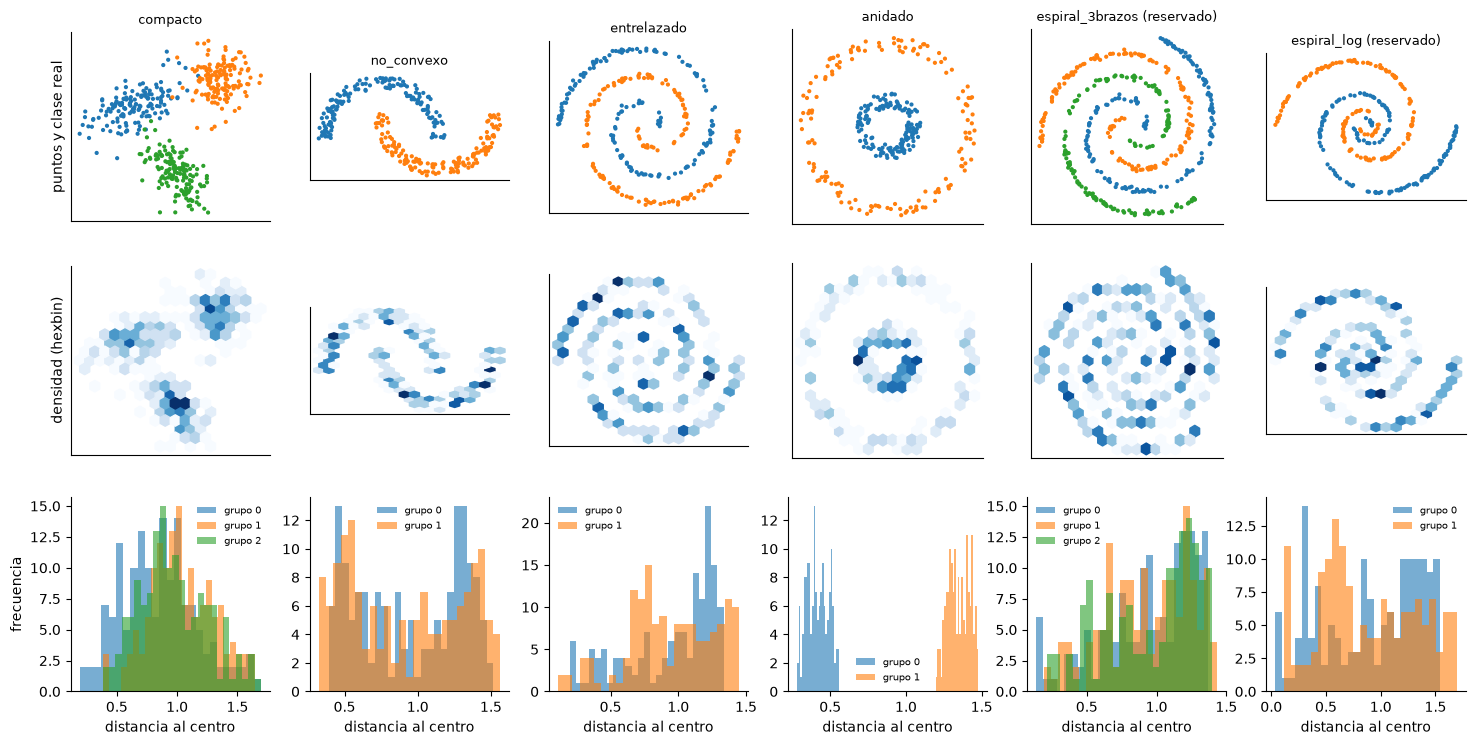

**Resumen de los escenarios 2D (semilla 100)**

,N,grupos,puntos por grupo,descripción
escenario,,,,
compacto,450,3,150/150/150,3 grupos gaussianos anisotrópicos casi en cont...
no_convexo,300,2,150/150,2 medias lunas entrelazadas (Crescent)
entrelazado,300,2,150/150,2 brazos de espiral arquimediana
anidado,300,2,150/150,"2 anillos concéntricos (Annulus), desconectados"
espiral_3brazos,450,3,150/150/150,3 brazos de espiral (no usado en desarrollo)
espiral_log,300,2,150/150,2 espirales logarítmicas (no usado en desarrollo)


In [82]:
from pointfield.datasets import make as crear_escenario, DESCRIPTIONS
from pointfield.perturbations import PERTURBATIONS
from pointfield.core.dataset import PointDataset

def cargar_2d(caso, variante="base", semilla=100, n=None):
    "Escenario 2D normalizado; las perturbaciones usan la semilla + 1000 (como en los scripts de la tesis)."
    ds = crear_escenario(caso, n_per_group=n or CONFIG["N_POR_GRUPO"], seed=semilla)
    if variante != "base":
        ds = PERTURBATIONS[variante](ds, semilla + 1000)
    return ds.normalized()

RESERVADOS = ["espiral_3brazos", "espiral_log"]
fig, ax = plt.subplots(3, 6, figsize=(18, 8.6))
resumen = []
for j, caso in enumerate(CASOS_2D):
    ds = cargar_2d(caso)
    X, y = ds.X, ds.y
    verifica(X.shape == (len(y), 2) and np.isfinite(X).all() and abs(np.sqrt((X ** 2).sum(1).mean()) - 1) < 1e-9,
             f"{caso}: X de forma ({len(y)}, 2), finita y normalizada (radio RMS = 1)")
    ax[0, j].scatter(X[:, 0], X[:, 1], c=y, cmap="tab10", s=4, vmin=0, vmax=9)
    ax[0, j].set_title(caso + (" (reservado)" if caso in RESERVADOS else ""), fontsize=9)
    ax[1, j].hexbin(X[:, 0], X[:, 1], gridsize=18, cmap="Blues", mincnt=1)
    r = np.linalg.norm(X, axis=1)
    for g in np.unique(y):
        ax[2, j].hist(r[y == g], bins=25, alpha=.6, label=f"grupo {g}")
    ax[2, j].set_xlabel("distancia al centro"); ax[2, j].legend(fontsize=7)
    for a in ax[:2, j]:
        a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    resumen.append({"escenario": caso, "N": len(y), "grupos": len(np.unique(y)),
                    "puntos por grupo": "/".join(str(int(c)) for c in np.bincount(y)), "descripción": DESCRIPTIONS[caso]})
ax[0, 0].set_ylabel("puntos y clase real"); ax[1, 0].set_ylabel("densidad (hexbin)"); ax[2, 0].set_ylabel("frecuencia")
guardar(fig, "escenarios_2d_distribucion", "3.3 Datos (escenarios 2D)")
plt.show()
tabla(pd.DataFrame(resumen).set_index("escenario"), titulo="Resumen de los escenarios 2D (semilla 100)")

**Cómo leer la figura.** Fila 1: puntos con su clase real (sólo para evaluar). Fila 2: densidad espacial; todos los escenarios tienen densidad aproximadamente uniforme a lo largo de cada estructura salvo las gaussianas. Fila 3: distribución de la distancia al centro por grupo. En `anidado` los grupos no se traslapan radialmente (un modelo que use el radio los separa); en las espirales los histogramas radiales se traslapan por completo: **ninguna función sólo del radio puede separarlas**, hace falta acoplar ángulo y radio (motivación de la fase angular, §4.3).

## **2.2 Perturbaciones**

Las tres perturbaciones de la tesis (`pointfield.perturbations`) imitan defectos de captura reales:

| Variante | Definición | Parámetro |
|---|---|---|
| `ruido` | se suma ruido gaussiano isotrópico de desviación σ·(radio RMS) | σ = 0.06 |
| `oclusion` | se elimina la fracción de puntos más lejana a lo largo de una dirección aleatoria (un sensor que no ve un lado) | 25 % |
| `densidad_variable` | probabilidad de conservar cada punto que baja linealmente de 1 a 0.15 a lo largo de una dirección | mínimo 0.15 |

[figura 09] 09_perturbaciones_2d.png  →  3.3 Datos (perturbaciones)


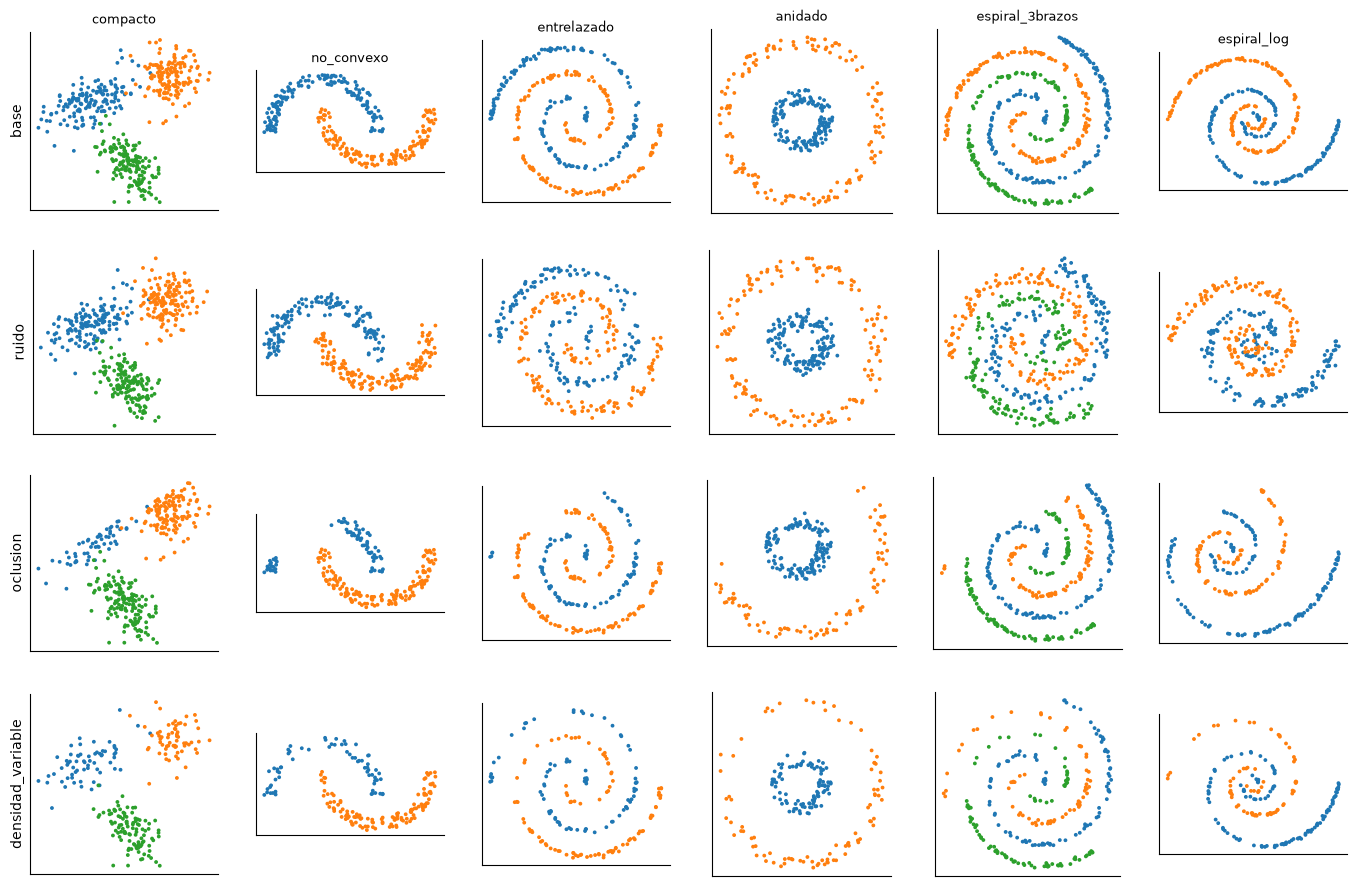

**Número de puntos tras cada perturbación (semilla 100)**

,compacto,no_convexo,entrelazado,anidado,espiral_3brazos,espiral_log
base,450,300,300,300,450,300
ruido,450,300,300,300,450,300
oclusion,337,225,225,225,337,225
densidad_variable,231,187,178,182,250,189


In [83]:
VARIANTES = CONFIG["VARIANTES_2D"]
fig, ax = plt.subplots(len(VARIANTES), 6, figsize=(17, 11))
conteo = {}
for j, caso in enumerate(CASOS_2D):
    for i, var in enumerate(VARIANTES):
        ds = cargar_2d(caso, var)
        conteo.setdefault(var, {})[caso] = ds.n_points
        ax[i, j].scatter(ds.X[:, 0], ds.X[:, 1], c=ds.y, cmap="tab10", s=3, vmin=0, vmax=9)
        ax[i, j].set_aspect("equal"); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        if i == 0: ax[i, j].set_title(caso, fontsize=9)
        if j == 0: ax[i, j].set_ylabel(var)
guardar(fig, "perturbaciones_2d", "3.3 Datos (perturbaciones)")
plt.show()
tabla(pd.DataFrame(conteo).T, 0, "Número de puntos tras cada perturbación (semilla 100)")

## **2.3 Transformaciones geométricas**

Una rotación, un cambio de escala o una traslación no cambian la forma; tras la normalización (centro y escala) la nube sólo difiere por una rotación. Un **estiramiento anisotrópico** sí cambia la geometría y no lo elimina la normalización. Estas transformaciones se usan en §5.4 para comprobar qué métodos son invariantes.

[figura 10] 10_transformaciones_2d.png  →  3.3 Datos (transformaciones)


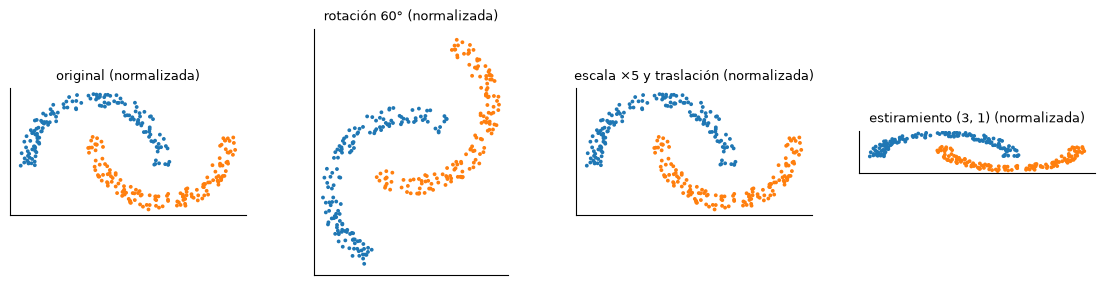

In [84]:
from pointfield.core.pose import random_rotation, rotation_matrix_2d
ds = cargar_2d("no_convexo")
TRANSFORMACIONES_2D = {
    "original": lambda X: X,
    "rotación 60°": lambda X: X @ rotation_matrix_2d(np.pi / 3).T,
    "escala ×5 y traslación": lambda X: 5 * X + [10.0, -4.0],
    "estiramiento (3, 1)": lambda X: X * [3.0, 1.0],
}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, (nombre, T) in zip(ax, TRANSFORMACIONES_2D.items()):
    Xt, _, _ = normalizar(T(ds.X))
    a.scatter(Xt[:, 0], Xt[:, 1], c=ds.y, cmap="tab10", s=3, vmin=0, vmax=9)
    a.set_aspect("equal"); a.set_title(f"{nombre} (normalizada)", fontsize=9); a.set_xticks([]); a.set_yticks([])
guardar(fig, "transformaciones_2d", "3.3 Datos (transformaciones)")
plt.show()

## **2.4 Escenarios enrollados en 3D (para embeddings)**

Para evaluar reducción de dimensión se necesita una verdad de referencia de baja dimensión. Cada escenario 2D se **enrolla** en un rollo suizo 3D (`pointfield.transforms.embed_roll`): la coordenada 2D original es la representación intrínseca correcta y se usa sólo para medir *trustworthiness* y *continuity*.

[figura 11] 11_escenarios_enrollados.png  →  3.3 Datos (embeddings)


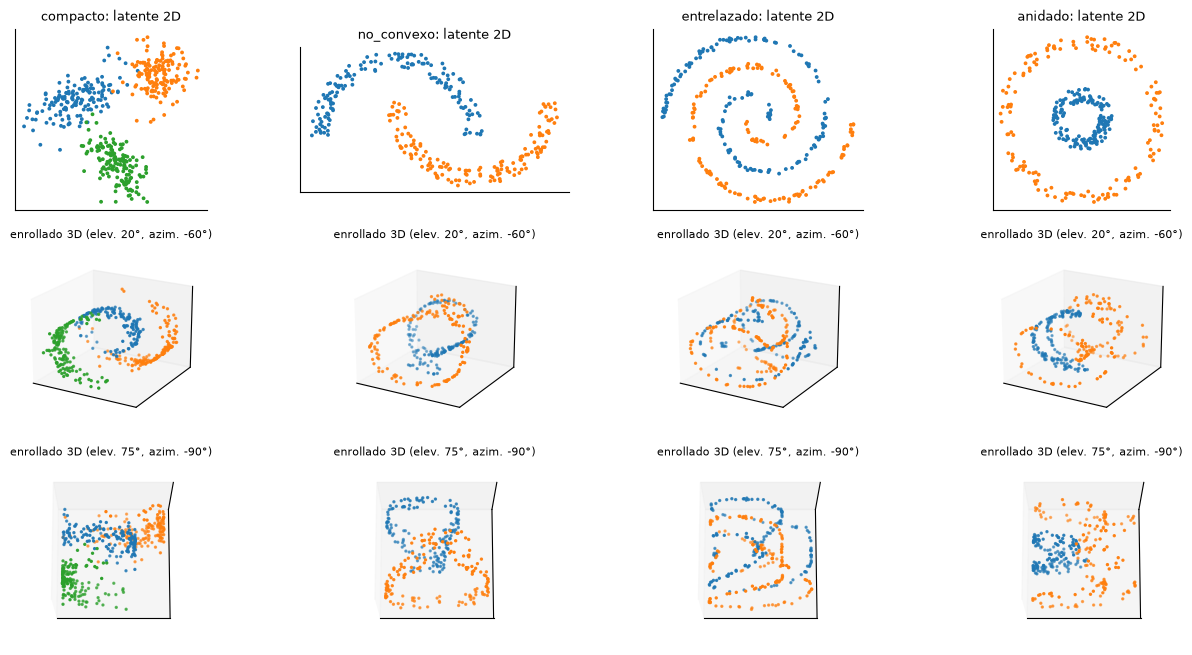

In [85]:
from pointfield.transforms import embed_roll
CASOS_EMB = ["compacto", "no_convexo", "entrelazado", "anidado"]

def enrollado(caso, semilla):
    "Devuelve (X3 normalizado (N,3), Z latente 2D (N,2), y)."
    ds = crear_escenario(caso, n_per_group=CONFIG["N_POR_GRUPO"], seed=semilla)
    X3, _, _ = normalizar(embed_roll(ds.latent))
    return X3, ds.latent, ds.y

fig = plt.figure(figsize=(16, 8))
for j, caso in enumerate(CASOS_EMB):
    X3, Z, y = enrollado(caso, 100)
    a = fig.add_subplot(3, 4, j + 1); a.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=3, vmin=0, vmax=9)
    a.set_title(f"{caso}: latente 2D", fontsize=9); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    for k, (el, az) in enumerate(((20, -60), (75, -90))):
        a = fig.add_subplot(3, 4, 4 * (k + 1) + j + 1, projection="3d")
        a.scatter(*X3.T, c=y, cmap="tab10", s=2, vmin=0, vmax=9); a.view_init(el, az)
        a.set_title(f"enrollado 3D (elev. {el}°, azim. {az}°)", fontsize=8); a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
guardar(fig, "escenarios_enrollados", "3.3 Datos (embeddings)")
plt.show()

## **2.5 Primitivas 3D**

Superficies de `pointfield.geometry.shapes3d`, muestreadas **uniformemente en área** (cada triángulo o parche recibe puntos en proporción a su área).

| Primitiva | Parámetros por defecto | Particularidad geométrica |
|---|---|---|
| `Sphere` | radio 1 | superficie algebraica de grado 2: M₂ singular |
| `Cube` | lado 1 | caras planas, aristas y vértices |
| `Pyramid` | base 1, altura 1 | base cuadrada + 4 triángulos; sin simetría central |
| `Torus` | R = 1, r = 0.35 | agujero: género 1 |
| `Cylinder` | radio 0.5, altura 1.5, con tapas | eje de simetría |
| `Cone` | radio 0.6, altura 1.4, con base | vértice singular |
| `Ellipsoid` | semiejes 1, 0.7, 0.4 | anisotropía sin aristas |
| `Helix` | radio 1, paso 1, 2 vueltas | curva (dimensión intrínseca 1) |

[figura 12] 12_primitivas_3d_vistas.png  →  3.3 Datos (primitivas 3D)


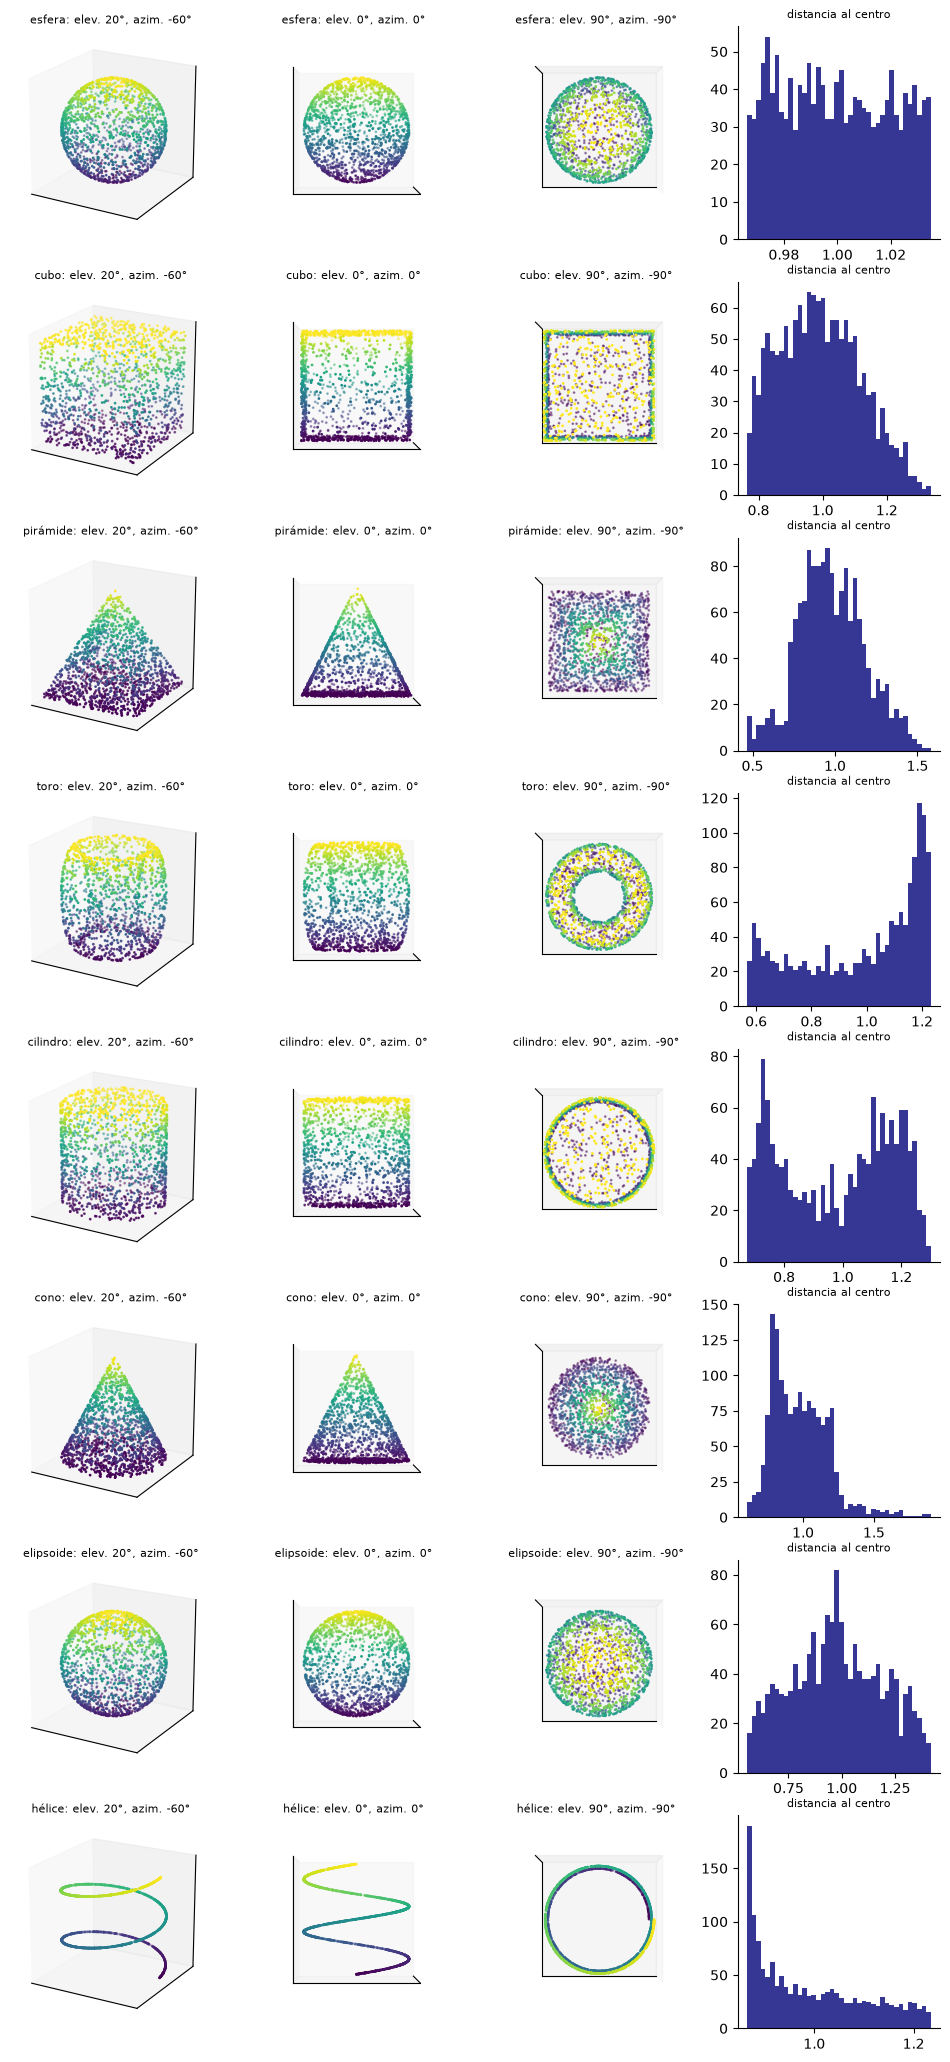

**Primitivas 3D normalizadas (1 500 puntos)**

,dim. intrínseca,radio mín.,radio máx.
primitiva,,,
esfera,2,0.966,1.035
cubo,2,0.764,1.337
pirámide,2,0.467,1.581
toro,2,0.567,1.232
cilindro,2,0.673,1.300
cono,2,0.604,1.902
elipsoide,2,0.556,1.418
hélice,1,0.864,1.235


In [86]:
from pointfield.geometry.shapes3d import Sphere, Cube, Pyramid, Torus, Cylinder, Cone, Ellipsoid, Helix
PRIMITIVAS = {"esfera": Sphere(1.0), "cubo": Cube(1.0), "pirámide": Pyramid(1.0, 1.0), "toro": Torus(1.0, 0.35),
              "cilindro": Cylinder(0.5, 1.5), "cono": Cone(0.6, 1.4), "elipsoide": Ellipsoid(1.0, 0.7, 0.4),
              "hélice": Helix(1.0, 1.0, 2.0)}
VISTAS = ((20, -60), (0, 0), (90, -90))
fig = plt.figure(figsize=(12, 26))
filas = []
for i, (nombre, g) in enumerate(PRIMITIVAS.items()):
    Xp, _, _ = normalizar(g.sample(1500, seed=0))
    filas.append({"primitiva": nombre, "dim. intrínseca": g.intrinsic_dimension, "radio mín.": np.linalg.norm(Xp, axis=1).min(),
                  "radio máx.": np.linalg.norm(Xp, axis=1).max()})
    for k, (el, az) in enumerate(VISTAS):
        a = fig.add_subplot(len(PRIMITIVAS), 4, 4 * i + k + 1, projection="3d")
        a.scatter(*Xp.T, c=Xp[:, 2], cmap="viridis", s=1); a.view_init(el, az); a.set_box_aspect((1, 1, 1))
        a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
        a.set_title(f"{nombre}: elev. {el}°, azim. {az}°", fontsize=8)
    a = fig.add_subplot(len(PRIMITIVAS), 4, 4 * i + 4)
    a.hist(np.linalg.norm(Xp, axis=1), bins=40, color=AZUL); a.set_title("distancia al centro", fontsize=8)
guardar(fig, "primitivas_3d_vistas", "3.3 Datos (primitivas 3D)")
plt.show()
tabla(pd.DataFrame(filas).set_index("primitiva"), 3, "Primitivas 3D normalizadas (1 500 puntos)")

**Interpretación.** Las tres vistas (perspectiva, frontal y superior) permiten distinguir formas que en una sola proyección se confunden (cilindro y cubo de frente). El histograma de distancias al centro ya es un descriptor de forma: la esfera tiene un único radio; el cubo, un rango entre la cara y el vértice; el toro, dos picos. Es exactamente la información radial que conserva el descriptor promediado del medio término (§6.1) y que no basta para distinguir formas con el mismo perfil radial.

## **2.6 Escenas 3D con varios objetos (agrupamiento en 3D)**

Para evaluar el agrupamiento de puntos en 3D se componen escenas con `SceneItem` y `Pose` (traslación y rotación de cada objeto):

| Escena | Composición | Qué evalúa |
|---|---|---|
| `esfera_cubo_piramide` | esfera r = 0.6 en (0, 0, 0); cubo lado 1 en (1.55, 0, 0); pirámide en (0.75, 1.45, 0) | objetos distintos y cercanos |
| `esferas_anidadas` | esferas concéntricas de radio 0.5 y 1.2 | anidamiento en 3D (análogo de `anidado`) |
| `toro_y_esfera` | toro R = 1, r = 0.25 y esfera r = 0.35 en su agujero | objeto dentro del hueco de otro |

400 puntos por objeto; se normaliza igual que en 2D.

✔ esfera_cubo_piramide: 1200 puntos en 3D, 3 objetos
✔ esferas_anidadas: 800 puntos en 3D, 2 objetos
✔ toro_y_esfera: 800 puntos en 3D, 2 objetos
[figura 13] 13_escenas_3d.png  →  3.3 Datos (escenas 3D)


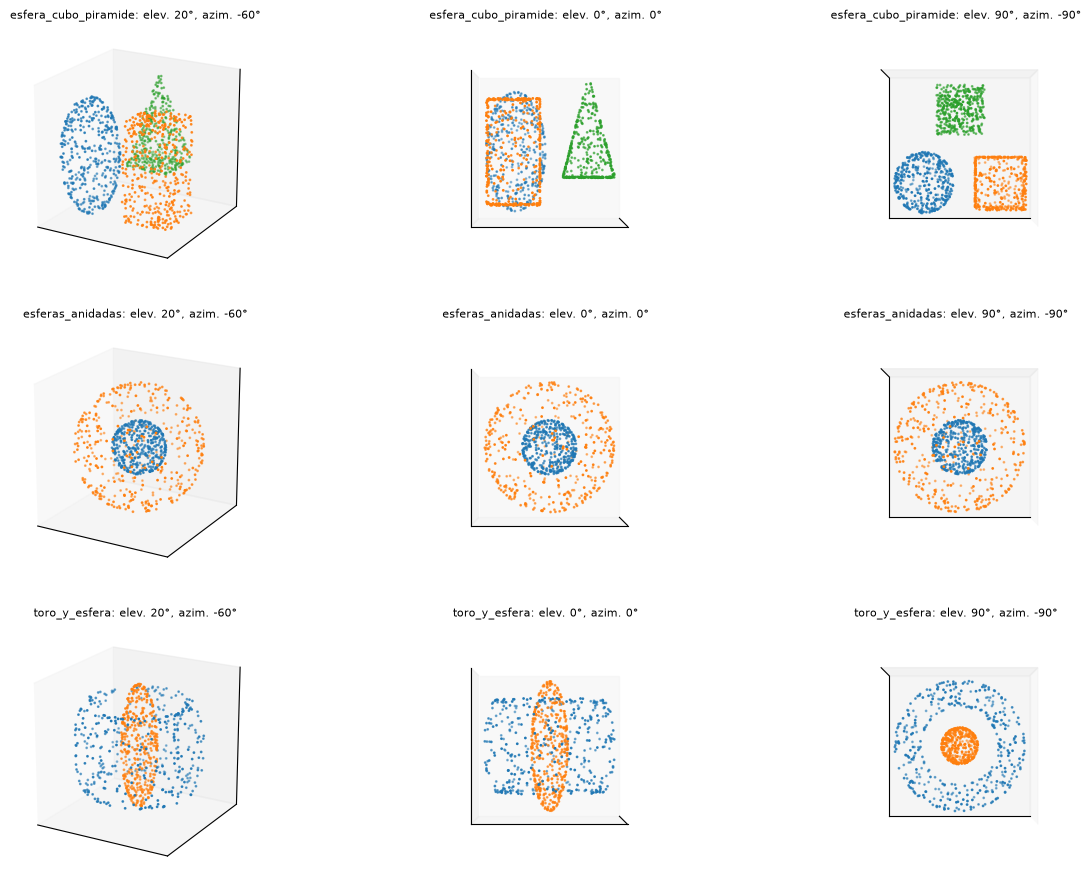

In [87]:
from pointfield.core.dataset import SceneItem, compose
from pointfield.core.pose import Pose
I3 = np.eye(3)
ESCENAS_3D = {
    "esfera_cubo_piramide": [SceneItem(Sphere(0.6), 400, Pose(np.array([0.0, 0.0, 0.0]), I3)),
                             SceneItem(Cube(1.0), 400, Pose(np.array([1.55, 0.0, 0.0]), I3)),
                             SceneItem(Pyramid(1.0, 1.0), 400, Pose(np.array([0.75, 1.45, 0.0]), I3))],
    "esferas_anidadas": [SceneItem(Sphere(0.5), 400, Pose(np.zeros(3), I3)), SceneItem(Sphere(1.2), 400, Pose(np.zeros(3), I3))],
    "toro_y_esfera": [SceneItem(Torus(1.0, 0.25), 400, Pose(np.zeros(3), I3)), SceneItem(Sphere(0.35), 400, Pose(np.zeros(3), I3))],
}

def cargar_3d(escena, variante="base", semilla=100):
    ds = compose(ESCENAS_3D[escena], name=escena, seed=semilla)
    if variante != "base":
        ds = PERTURBATIONS[variante](ds, semilla + 1000)
    return ds.normalized()

fig = plt.figure(figsize=(15, 11))
for i, esc in enumerate(ESCENAS_3D):
    ds = cargar_3d(esc)
    verifica(ds.X.shape[1] == 3 and len(np.unique(ds.y)) == len(ESCENAS_3D[esc]), f"{esc}: {ds.n_points} puntos en 3D, {ds.n_groups} objetos")
    for k, (el, az) in enumerate(VISTAS):
        a = fig.add_subplot(3, 3, 3 * i + k + 1, projection="3d")
        a.scatter(*ds.X.T, c=ds.y, cmap="tab10", s=1, vmin=0, vmax=9); a.view_init(el, az); a.set_box_aspect((1, 1, 1))
        a.set_title(f"{esc}: elev. {el}°, azim. {az}°", fontsize=8); a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
guardar(fig, "escenas_3d", "3.3 Datos (escenas 3D)")
plt.show()

## **2.7 Familias de objetos para descripción de formas**

Para la tarea de **describir objetos completos** (un vector por objeto, §6) se usan familias con variación dentro de cada clase (`pointfield.objects`). Cada objeto recibe una **similitud aleatoria**: rotación o reflexión, escala uniforme en [0.5, 2] y traslación en [−5, 5]^d.

| Familias 3D | Variación intraclase | Familias 2D | Variación intraclase |
|---|---|---|---|
| esfera | — | elipse | eje menor 0.35–0.8 |
| elipsoide | semiejes 1, 0.5–0.8, 0.25–0.45 | rectángulo | lado corto 0.35–0.8 |
| cubo | — | triángulo | tercer vértice aleatorio |
| cilindro | radio 0.3–0.6, altura 1.2–2.0 | hexágono | — |
| cono | radio 0.4–0.8, altura 1.0–1.8 | estrella | radio interior 0.35–0.55 |
| toro | radio menor 0.2–0.45 | corona | radio interior 0.4–0.7 |
| pirámide | altura 0.6–1.4 | | |

[figura 14] 14_familias_3d.png  →  3.3 Datos (objetos sintéticos 3D)


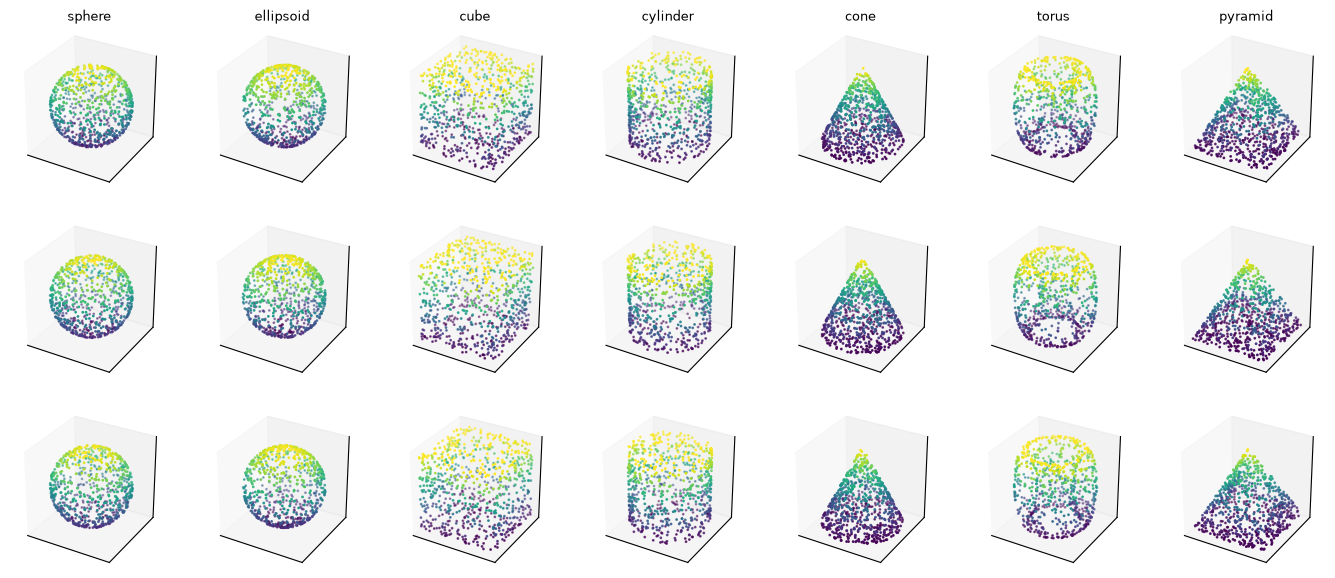

[figura 15] 15_familias_2d.png  →  3.3 Datos (objetos sintéticos 2D)


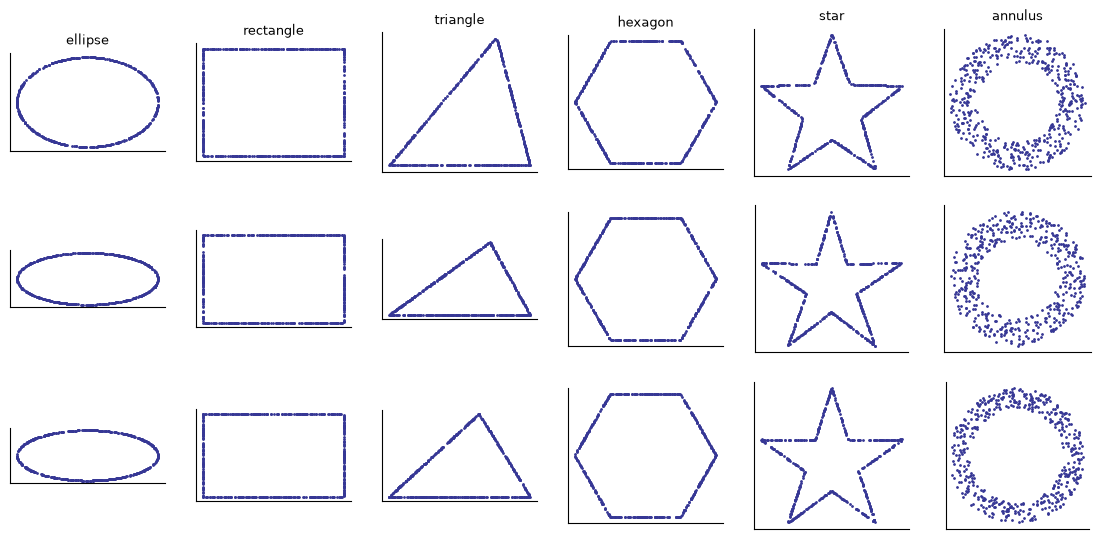

In [88]:
from pointfield.objects import make_object_dataset, random_similarity, FAMILIES_2D, FAMILIES_3D
nubes3, y3, fam3 = make_object_dataset(3, 3, 800, seed=0, transform=False)
fig = plt.figure(figsize=(17, 7))
for j, f in enumerate(fam3):
    for k in range(3):
        Xo = nubes3[j * 3 + k]
        a = fig.add_subplot(3, len(fam3), k * len(fam3) + j + 1, projection="3d")
        a.scatter(*Xo.T, s=1, c=Xo[:, 2], cmap="viridis"); a.set_box_aspect((1, 1, 1))
        a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
        if k == 0: a.set_title(f, fontsize=9)
guardar(fig, "familias_3d", "3.3 Datos (objetos sintéticos 3D)")
plt.show()

nubes2, y2, fam2 = make_object_dataset(2, 3, 500, seed=0, transform=False)
fig, ax = plt.subplots(3, len(fam2), figsize=(14, 6.5))
for j, f in enumerate(fam2):
    for k in range(3):
        Xo = nubes2[j * 3 + k]
        ax[k, j].scatter(Xo[:, 0], Xo[:, 1], s=1, c=AZUL); ax[k, j].set_aspect("equal"); ax[k, j].set_xticks([]); ax[k, j].set_yticks([])
        if k == 0: ax[k, j].set_title(f, fontsize=9)
guardar(fig, "familias_2d", "3.3 Datos (objetos sintéticos 2D)")
plt.show()

**Interpretación.** Cada columna es una clase y cada fila un objeto distinto de esa clase: la variación intraclase obliga a que el descriptor reconozca la **familia de forma**, no un objeto concreto. Las figuras se muestran sin la similitud aleatoria para que se aprecie la forma; en los experimentos sí se aplica.

---
# **3. Modelos de comparación**

Los métodos de referencia resuelven **dos problemas distintos**, y se evalúan por separado:

| Problema | Entrada → salida | Métodos | Métricas apropiadas |
|---|---|---|---|
| **Reducción de dimensión (embedding)** | $X\in\mathbb R^{N\times D}$ → $E\in\mathbb R^{N\times 2}$ | PCA, Kernel PCA, Isomap, Laplacian Eigenmaps, UMAP, embedding CD local | trustworthiness, continuity, exactitud k-NN de las clases en $E$, tiempo |
| **Agrupamiento (clustering)** | $X$ → etiquetas $\hat y\in\{1..k\}^N$ | K-Means, DBSCAN, OPTICS, Spectral Clustering, CD global, CD local (M1), CD + fase (M2) | ARI, NMI, homogeneidad, completitud, silueta, tiempo, memoria |
| **Pipeline** | $X$ → $E$ → $\hat y$ | UMAP + K-Means | las de agrupamiento |

Una métrica de agrupamiento no se aplica a un embedding ni al revés. Primero se definen e implementan las métricas (§3.1); después cada modelo tiene su sección con definición, ecuaciones, supuestos, hiperparámetros, implementación explícita (cuando es razonable), comprobación contra `scikit-learn`, aplicación y comparación con CD.

**Datos de demostración** (los benchmarks completos están en §5): para embeddings, el escenario `no_convexo` enrollado en 3D (semilla 100); para agrupamiento, los escenarios `compacto` y `no_convexo` en 2D (semilla 100).

## **3.1 Métricas de evaluación, implementadas desde cero**

**Agrupamiento (externas: comparan $\hat y$ con la clase real $y$).** Sea la tabla de contingencia $n_{ij}=|\{t: y_t=i,\hat y_t=j\}|$, $a_i=\sum_j n_{ij}$, $b_j=\sum_i n_{ij}$.

* **ARI** (Hubert y Arabie, 1985): $\displaystyle \mathrm{ARI}=\frac{\sum_{ij}\binom{n_{ij}}2-E}{\tfrac12\big[\sum_i\binom{a_i}2+\sum_j\binom{b_j}2\big]-E},\; E=\frac{\sum_i\binom{a_i}2\sum_j\binom{b_j}2}{\binom N2}$. Vale 1 si las particiones coinciden y ≈ 0 para una asignación al azar.
* **NMI**: $I(y;\hat y)/\tfrac12(H(y)+H(\hat y))$.
* **Homogeneidad** $=1-H(y\mid\hat y)/H(y)$: cada grupo contiene una sola clase. **Completitud** $=1-H(\hat y\mid y)/H(\hat y)$: cada clase cae en un solo grupo.

**Agrupamiento (interna: no usa $y$).**
* **Silueta**: $s_t=(b_t-a_t)/\max(a_t,b_t)$, con $a_t$ la distancia media a su propio grupo y $b_t$ la menor distancia media a otro grupo. **Advertencia:** premia grupos compactos y convexos; para lunas o espirales la partición *correcta* tiene silueta baja. Se reporta, pero no se usa para declarar ganadores.

**Embeddings** (Venna y Kaski, 2001). Con $r(t,u)$ el rango de $u$ entre los vecinos de $t$ en el espacio original y $U_k(t)$ los puntos que están entre los $k$ vecinos de $t$ en el embedding pero no en el original:
$$T(k)=1-\frac{2}{Nk(2N-3k-1)}\sum_t\sum_{u\in U_k(t)}\big(r(t,u)-k\big).$$
$T$ penaliza **intrusos** (vecinos falsos en el embedding); la **continuidad** $C(k)$ es la misma fórmula con los papeles intercambiados (penaliza vecinos perdidos). Aquí el "espacio original" es la coordenada latente 2D conocida.

In [89]:
from scipy.special import comb as _comb
from sklearn import metrics as skm

def contingencia(y, yp):
    _, yi = np.unique(y, return_inverse=True); _, pj = np.unique(yp, return_inverse=True)
    T = np.zeros((yi.max() + 1, pj.max() + 1), dtype=np.int64)
    np.add.at(T, (yi, pj), 1)
    return T

def ari(y, yp):
    T = contingencia(y, yp); n = T.sum()
    idx = _comb(T, 2).sum(); a = _comb(T.sum(1), 2).sum(); b = _comb(T.sum(0), 2).sum()
    esperado = a * b / _comb(n, 2); maximo = (a + b) / 2
    return 1.0 if maximo == esperado else (idx - esperado) / (maximo - esperado)

def entropia(p):
    p = p[p > 0]; return -(p * np.log(p)).sum()

def nmi_hom_comp(y, yp):
    T = contingencia(y, yp).astype(float); P = T / T.sum()
    Hy, Hp = entropia(P.sum(1)), entropia(P.sum(0))
    I = sum(P[i, j] * np.log(P[i, j] / (P[i].sum() * P[:, j].sum())) for i, j in zip(*np.nonzero(P)))
    nmi = I / ((Hy + Hp) / 2) if Hy + Hp > 0 else 1.0
    hom = 1 - (Hy - I) / Hy if Hy > 0 else 1.0           # H(y|ŷ) = H(y) − I
    comp = 1 - (Hp - I) / Hp if Hp > 0 else 1.0
    return nmi, hom, comp

def silueta(X, yp):
    D = np.linalg.norm(X[:, None] - X[None], axis=-1); s = np.zeros(len(X))
    grupos = np.unique(yp)
    for t in range(len(X)):
        propio = yp == yp[t]
        a = D[t, propio].sum() / max(propio.sum() - 1, 1)
        b = min(D[t, yp == g].mean() for g in grupos if g != yp[t])
        s[t] = 0 if propio.sum() == 1 else (b - a) / max(a, b)
    return s.mean()

def rangos(D):
    "R[t, u] = posición de u en la lista de vecinos de t (1 = el más cercano)."
    orden = np.argsort(D, axis=1, kind="stable")
    R = np.empty_like(orden); filas = np.arange(len(D))[:, None]
    R[filas, orden] = np.arange(D.shape[1])[None, :]
    return R

def trustworthiness_cero(X_orig, E, k):
    N = len(X_orig)
    Do = np.linalg.norm(X_orig[:, None] - X_orig[None], axis=-1); np.fill_diagonal(Do, np.inf)
    De = np.linalg.norm(E[:, None] - E[None], axis=-1); np.fill_diagonal(De, np.inf)
    Ro = rangos(Do) + 1
    vec_e = np.argsort(De, axis=1)[:, :k]; vec_o = np.argsort(Do, axis=1)[:, :k]
    pen = 0.0
    for t in range(N):
        intrusos = np.setdiff1d(vec_e[t], vec_o[t])
        pen += (Ro[t, intrusos] - k).sum()
    return 1 - 2.0 / (N * k * (2 * N - 3 * k - 1)) * pen

def continuidad_cero(X_orig, E, k):
    return trustworthiness_cero(E, X_orig, k)

# --- comprobación contra scikit-learn ---
ds = cargar_2d("no_convexo")
yp_prueba = KMeans(2, n_init=10, random_state=0).fit_predict(ds.X)
verifica(np.isclose(ari(ds.y, yp_prueba), skm.adjusted_rand_score(ds.y, yp_prueba)), "ARI desde cero = scikit-learn")
n_, h_, c_ = nmi_hom_comp(ds.y, yp_prueba)
verifica(np.allclose([n_, h_, c_], [skm.normalized_mutual_info_score(ds.y, yp_prueba), skm.homogeneity_score(ds.y, yp_prueba),
                                    skm.completeness_score(ds.y, yp_prueba)]), "NMI, homogeneidad y completitud desde cero = scikit-learn")
verifica(np.isclose(silueta(ds.X, yp_prueba), skm.silhouette_score(ds.X, yp_prueba)), "silueta desde cero = scikit-learn")
from sklearn.manifold import trustworthiness as sk_trust
X3d, Zd, yd = enrollado("no_convexo", 100)
E_pca_prueba = X3d[:, :2]
verifica(np.isclose(trustworthiness_cero(Zd, E_pca_prueba, 10), sk_trust(Zd, E_pca_prueba, n_neighbors=10)), "trustworthiness desde cero = scikit-learn")
print(f"Silueta de la partición REAL de las lunas: {silueta(ds.X, ds.y):.3f}  vs. silueta de K-Means (incorrecto): {silueta(ds.X, yp_prueba):.3f}")

✔ ARI desde cero = scikit-learn
✔ NMI, homogeneidad y completitud desde cero = scikit-learn
✔ silueta desde cero = scikit-learn
✔ trustworthiness desde cero = scikit-learn
Silueta de la partición REAL de las lunas: 0.355  vs. silueta de K-Means (incorrecto): 0.487


**Interpretación de la última línea.** K-Means corta las lunas por la mitad y aun así obtiene **mayor silueta** que la partición correcta: la silueta mide compacidad, no corrección. Por eso las conclusiones de agrupamiento se basan en ARI/NMI y la silueta sólo se reporta como información adicional.

In [90]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

def metricas_embedding(Z, E, y, k=None):
    k = k or CONFIG["K_VECINOS"]
    return {"T": sk_trust(Z, E, n_neighbors=k), "C": sk_trust(E, Z, n_neighbors=k),
            "kNN_acc": cross_val_score(KNeighborsClassifier(5), E, y, cv=5).mean()}

def metricas_cluster(X, y, yp):
    "Métricas externas e internas. Los puntos de ruido (−1) cuentan como un grupo propio en ARI/NMI; la silueta los excluye."
    n, h, c = nmi_hom_comp(y, yp)
    validos = yp >= 0
    k_enc = len(np.unique(yp[validos]))
    sil = skm.silhouette_score(X[validos], yp[validos]) if 2 <= k_enc < validos.sum() else np.nan
    return {"ARI": ari(y, yp), "NMI": n, "homogeneidad": h, "completitud": c, "silueta": sil,
            "grupos": k_enc, "ruido %": 100 * (1 - validos.mean())}
print("Funciones de métricas listas.")

Funciones de métricas listas.


## **3.2 Reducción de dimensión**

Todos los métodos reciben la misma nube 3D enrollada `X3` $(N\times3)$ y devuelven `E` $(N\times2)$. La verdad de referencia es la coordenada latente `Z` $(N\times2)$.

### **3.2.1 PCA — Análisis de Componentes Principales**

**Definición.** Proyección lineal sobre las $p$ direcciones de mayor varianza.

**Ecuaciones.** $\bar x=\frac1N\sum x_i$, $\Sigma=\frac1N X_c^\top X_c$, $\Sigma=W\Lambda W^\top$ (valores propios decrecientes), $E=X_cW_{:,1:p}$.

**Supuestos y limitaciones.** La estructura relevante es lineal; no puede "desenrollar" variedades curvas. **Hiperparámetro:** $p$ (= 2). **Costo:** $O(ND^2+D^3)$.

In [91]:
def pca_cero(X, p=2):
    Xc = X - X.mean(0)
    w, W = np.linalg.eigh(Xc.T @ Xc / len(X))
    orden = np.argsort(w)[::-1]
    return Xc @ W[:, orden[:p]], w[orden]

from sklearn.decomposition import PCA, KernelPCA
E_pca, var_pca = pca_cero(X3d)
E_sk = PCA(2).fit_transform(X3d)
corr = [abs(np.corrcoef(E_pca[:, j], E_sk[:, j])[0, 1]) for j in range(2)]
verifica(min(corr) > 1 - 1e-9, "PCA desde cero = scikit-learn (salvo signo de cada componente)")
print("varianza explicada:", np.round(var_pca / var_pca.sum(), 3))
EMB_DEMO = {"PCA": E_pca}

✔ PCA desde cero = scikit-learn (salvo signo de cada componente)
varianza explicada: [0.567 0.411 0.021]


### **3.2.2 Kernel PCA (núcleo gaussiano RBF)**

**Definición.** PCA en el espacio de características implícito de un núcleo $k(x,y)=\exp(-\gamma\|x-y\|^2)$.

**Ecuaciones.** Matriz de Gram $K_{ij}=k(x_i,x_j)$; centrado $\tilde K=HKH$, $H=I-\frac1N\mathbf 1\mathbf 1^\top$; $\tilde K=U\Lambda U^\top$; $E=U_{:,1:p}\Lambda_{1:p}^{1/2}$.

**Supuestos y limitaciones.** El resultado depende fuertemente de $\gamma$, que no se elige con los datos; con $\gamma$ grande el embedding se vuelve local y ruidoso, con $\gamma$ pequeño se parece a PCA. **Hiperparámetros:** $\gamma=1/D$ (valor por defecto de scikit-learn, el usado en la tesis), $p=2$. **Costo:** $O(N^2D+N^3)$.

**Relación con CD.** El núcleo CD (§1.14) también es un núcleo, pero polinomial y adaptado a los datos ($M^{-1}$), con rango $\le s$.

In [92]:
def kpca_rbf_cero(X, p=2, gamma=None):
    gamma = 1.0 / X.shape[1] if gamma is None else gamma
    D2 = ((X[:, None] - X[None]) ** 2).sum(-1)
    K = np.exp(-gamma * D2)
    H = np.eye(len(X)) - 1.0 / len(X)
    w, U = np.linalg.eigh(H @ K @ H)
    orden = np.argsort(w)[::-1][:p]
    return U[:, orden] * np.sqrt(np.maximum(w[orden], 0))

E_kpca = kpca_rbf_cero(X3d)
E_sk = KernelPCA(2, kernel="rbf").fit_transform(X3d)
corr = [abs(np.corrcoef(E_kpca[:, j], E_sk[:, j])[0, 1]) for j in range(2)]
verifica(min(corr) > 1 - 1e-6, "Kernel PCA desde cero = scikit-learn (salvo signo)")
EMB_DEMO["Kernel PCA (RBF)"] = E_kpca

✔ Kernel PCA desde cero = scikit-learn (salvo signo)


### **3.2.3 Isomap**

**Definición.** MDS clásico aplicado a distancias **geodésicas** aproximadas por caminos mínimos en un grafo de vecinos (Tenenbaum et al., 2000).

**Ecuaciones.** (1) Grafo $k$-NN con pesos $\|x_i-x_j\|$; (2) $D^{G}_{ij}$ = camino mínimo (Dijkstra); (3) $B=-\frac12 H (D^G)^{\circ2} H$; (4) $E=U_{:,1:p}\Lambda^{1/2}_{1:p}$ con los vectores propios principales de $B$.

**Supuestos y limitaciones.** La variedad es isométrica a un subconjunto convexo del plano; falla con "atajos" en el grafo (ruido) o con huecos. **Hiperparámetros:** $k=10$, $p=2$. **Costo:** $O(N^2\log N+N^3)$.

In [93]:
from scipy.sparse.csgraph import shortest_path
from sklearn.neighbors import kneighbors_graph
from sklearn.manifold import Isomap, SpectralEmbedding

def isomap_cero(X, k=10, p=2):
    G = kneighbors_graph(X, k, mode="distance")          # matriz dispersa N × N
    DG = shortest_path(G, method="D", directed=False)
    verifica(np.isfinite(DG).all(), f"grafo {k}-NN conexo (todas las geodésicas finitas)")
    H = np.eye(len(X)) - 1.0 / len(X)
    B = -0.5 * H @ (DG ** 2) @ H
    w, U = np.linalg.eigh(B)
    orden = np.argsort(w)[::-1][:p]
    return U[:, orden] * np.sqrt(np.maximum(w[orden], 0))

E_iso = isomap_cero(X3d, CONFIG["K_VECINOS"])
E_sk = Isomap(n_neighbors=CONFIG["K_VECINOS"], n_components=2).fit_transform(X3d)
corr = [abs(np.corrcoef(E_iso[:, j], E_sk[:, j])[0, 1]) for j in range(2)]
verifica(min(corr) > 1 - 1e-6, "Isomap desde cero = scikit-learn (salvo signo)")
EMB_DEMO["Isomap"] = E_iso

✔ grafo 10-NN conexo (todas las geodésicas finitas)
✔ Isomap desde cero = scikit-learn (salvo signo)


### **3.2.4 Laplacian Eigenmaps**

**Definición.** Embedding que minimiza $\sum_{ij}W_{ij}\|e_i-e_j\|^2$: puntos vecinos en el grafo quedan cerca (Belkin y Niyogi, 2001).

**Ecuaciones.** $W$ = grafo $k$-NN binario (cada punto cuenta como uno de sus $k$ vecinos, convención de scikit-learn) simetrizado, $W\leftarrow\frac12(W+W^\top)$; $D=\operatorname{diag}(W\mathbf1)$; Laplaciano normalizado $\mathcal L=I-D^{-1/2}WD^{-1/2}$; se toman los vectores propios $u_2,\dots,u_{p+1}$ de los menores valores propios (se descarta el trivial) y $e=u/\sqrt{d}$.

**Supuestos y limitaciones.** El grafo debe ser conexo; el embedding preserva vecindad, no distancias, y suele comprimir los extremos. **Hiperparámetros:** $k=10$, $p=2$. **Costo:** $O(N^3)$ denso (scikit-learn usa ARPACK disperso).

**Relación con CD.** El embedding CD local (§4.2) es exactamente este procedimiento con otra matriz de pesos $W$: la afinidad de los modelos CD locales.

In [94]:
def grafo_knn_binario(X, k):
    "Grafo k-NN 0/1 como en scikit-learn (cada punto cuenta como su propio vecino), simetrizado; sin lazos."
    W = kneighbors_graph(X, k, mode="connectivity", include_self=True).toarray()
    W = 0.5 * (W + W.T)
    np.fill_diagonal(W, 0.0)          # el Laplaciano ignora los lazos
    return W

def embedding_laplaciano(W, p=2, quitar_primero=True):
    "Vectores propios del Laplaciano normalizado divididos por √grado (convención de scikit-learn)."
    d = W.sum(1); Dm = 1.0 / np.sqrt(d)
    Ln = np.eye(len(W)) - Dm[:, None] * W * Dm[None, :]
    w, U = np.linalg.eigh(Ln)
    E = U[:, : p + int(quitar_primero)] * Dm[:, None]
    return E[:, 1:] if quitar_primero else E, w

E_le, w_le = embedding_laplaciano(grafo_knn_binario(X3d, CONFIG["K_VECINOS"]))
E_sk = SpectralEmbedding(2, affinity="nearest_neighbors", n_neighbors=CONFIG["K_VECINOS"], random_state=0).fit_transform(X3d)
corr = [abs(np.corrcoef(E_le[:, j], E_sk[:, j])[0, 1]) for j in range(2)]
print("primeros valores propios del Laplaciano:", np.round(w_le[:4], 4), "-> número de componentes conexas del grafo:", int((w_le < 1e-10).sum()))
verifica(min(corr) > 0.999, "Laplacian Eigenmaps desde cero = scikit-learn (salvo signo)")
EMB_DEMO["Laplacian Eigenmaps"] = E_le

primeros valores propios del Laplaciano: [0.     0.     0.0015 0.007 ] -> número de componentes conexas del grafo: 2
✔ Laplacian Eigenmaps desde cero = scikit-learn (salvo signo)


### **3.2.5 UMAP — Uniform Manifold Approximation and Projection**

**Definición** (McInnes, Healy y Melville, 2018). Construye un grafo difuso de vecinos en el espacio original y busca un embedding cuyo grafo difuso se le parezca.

**Ecuaciones.** Para cada punto, $\rho_i$ = distancia al vecino más cercano y $\sigma_i$ tal que $\sum_{j\in kNN(i)}\exp(-(d_{ij}-\rho_i)/\sigma_i)=\log_2 k$; pesos $w_{j|i}=\exp(-(d_{ij}-\rho_i)/\sigma_i)$, simetrizados $w_{ij}=w_{j|i}+w_{i|j}-w_{j|i}w_{i|j}$. En el embedding la similitud es $v_{ij}=(1+a\|e_i-e_j\|^{2b})^{-1}$ y se minimiza la entropía cruzada $\sum w\log\frac wv+(1-w)\log\frac{1-w}{1-v}$ por descenso de gradiente estocástico.

**Supuestos y limitaciones.** Datos muestreados uniformemente sobre una variedad; el resultado es estocástico (se fija `random_state`) y las distancias globales del embedding no son interpretables. **Hiperparámetros:** `n_neighbors=10`, `min_dist=0.1`, `n_components=2`, `random_state=0`. Se usa la biblioteca `umap-learn`; implementar el optimizador desde cero no aporta a la comparación.

umap-learn no está instalado: se omite UMAP (pip install umap-learn).
[figura 16] 16_embeddings_demo_no_convexo.png  →  2.3.1 Reducción de dimensionalidad (ejemplo)


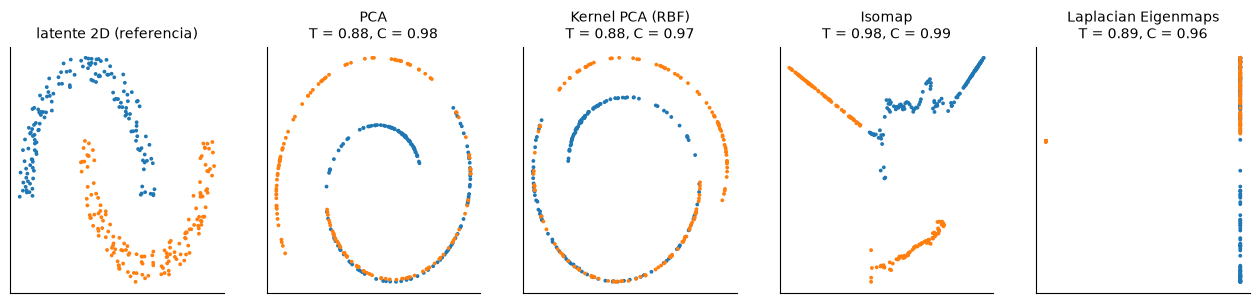

**Embeddings del escenario no_convexo enrollado (semilla 100, k = 10)**

,T,C,kNN_acc
método,,,
PCA,0.884,0.976,0.763
Kernel PCA (RBF),0.879,0.973,0.747
Isomap,0.984,0.989,1.000
Laplacian Eigenmaps,0.890,0.956,0.780


In [95]:
try:
    import umap
    UMAP_OK = True
except ImportError:
    UMAP_OK = False
    print("umap-learn no está instalado: se omite UMAP (pip install umap-learn).")

def umap_2d(X, k=None):
    return umap.UMAP(n_neighbors=k or CONFIG["K_VECINOS"], n_components=2, min_dist=0.1, random_state=0).fit_transform(X)

if UMAP_OK:
    EMB_DEMO["UMAP"] = umap_2d(X3d)
fig, ax = plt.subplots(1, len(EMB_DEMO) + 1, figsize=(3.2 * (len(EMB_DEMO) + 1), 3.2))
ax[0].scatter(Zd[:, 0], Zd[:, 1], c=yd, cmap="tab10", s=3, vmin=0, vmax=9); ax[0].set_title("latente 2D (referencia)")
filas = []
for a, (nombre, E) in zip(ax[1:], EMB_DEMO.items()):
    m = metricas_embedding(Zd, E, yd)
    filas.append({"método": nombre, **m})
    a.scatter(E[:, 0], E[:, 1], c=yd, cmap="tab10", s=3, vmin=0, vmax=9); a.set_title(f"{nombre}\nT = {m['T']:.2f}, C = {m['C']:.2f}")
for a in ax: a.set_xticks([]); a.set_yticks([])
guardar(fig, "embeddings_demo_no_convexo", "2.3.1 Reducción de dimensionalidad (ejemplo)")
plt.show()
tabla(pd.DataFrame(filas).set_index("método"), 3, "Embeddings del escenario no_convexo enrollado (semilla 100, k = 10)")

**Interpretación.** PCA y Kernel PCA ven el rollo "de frente" y mezclan capas (T más bajo). Isomap, al usar distancias geodésicas, desenrolla casi por completo este caso, y UMAP preserva igual de bien las vecindades locales. Laplacian Eigenmaps queda intermedio: el grafo de 10 vecinos tiene aquí dos componentes conexas (las dos lunas), y el embedding se dedica a separarlas más que a desenrollarlas. La comparación con el embedding CD local se hace en el benchmark completo (§5.2) con los cuatro escenarios.

## **3.3 Agrupamiento**

### **3.3.1 K-Means**

**Definición.** Partición en $k$ grupos que minimiza la inercia $J=\sum_t\|x_t-\mu_{\hat y_t}\|^2$.

**Algoritmo de Lloyd.** Inicialización *k-means++* (cada nuevo centro se elige con probabilidad $\propto$ distancia² al más cercano); alternar (a) asignar cada punto al centro más cercano y (b) recalcular centros como medias, hasta que no cambien. Se repite con `n_init` inicializaciones y se queda la de menor $J$.

**Supuestos y limitaciones.** Grupos convexos, isotrópicos y de tamaño similar; requiere $k$. **Hiperparámetros:** $k$ (el real), `n_init=10`. **Costo:** $O(Nk\,\text{iter})$.

✔ K-Means desde cero alcanza la misma inercia y partición que scikit-learn


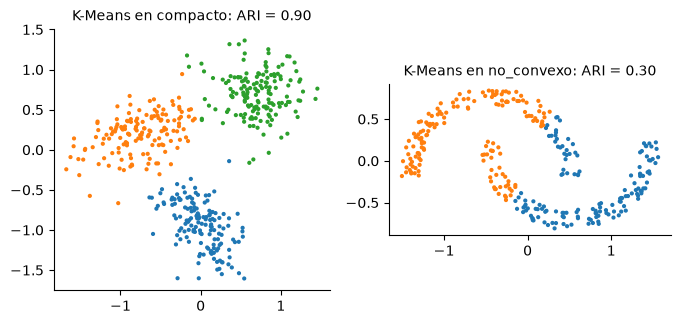

In [96]:
def kmeans_cero(X, k, n_init=10, iteraciones=300, semilla=0):
    rng = np.random.default_rng(semilla)
    mejor = (np.inf, None)
    for _ in range(n_init):
        C = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = np.min(((X[:, None] - np.array(C)[None]) ** 2).sum(-1), axis=1)
            C.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        C = np.array(C)
        for _ in range(iteraciones):
            lab = np.argmin(((X[:, None] - C[None]) ** 2).sum(-1), axis=1)
            nuevo = np.array([X[lab == j].mean(0) if np.any(lab == j) else C[j] for j in range(k)])
            if np.allclose(nuevo, C): break
            C = nuevo
        J = ((X - C[lab]) ** 2).sum()
        if J < mejor[0]: mejor = (J, lab)
    return mejor[1], mejor[0]

dsc = cargar_2d("compacto")
lab_c, J_c = kmeans_cero(dsc.X, 3)
km = KMeans(3, n_init=10, random_state=0).fit(dsc.X)
verifica(abs(J_c - km.inertia_) / km.inertia_ < 1e-6 and ari(lab_c, km.labels_) == 1.0, "K-Means desde cero alcanza la misma inercia y partición que scikit-learn")
dsl = cargar_2d("no_convexo")
lab_l, _ = kmeans_cero(dsl.X, 2)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a, (d_, l_, t_) in zip(ax, ((dsc, lab_c, "compacto"), (dsl, lab_l, "no_convexo"))):
    a.scatter(d_.X[:, 0], d_.X[:, 1], c=l_, cmap="tab10", s=4, vmin=0, vmax=9); a.set_aspect("equal")
    a.set_title(f"K-Means en {t_}: ARI = {ari(d_.y, l_):.2f}")
plt.show()

### **3.3.2 DBSCAN**

**Definición** (Ester et al., 1996). Un punto es **núcleo** si tiene al menos `min_samples` puntos (incluido él) a distancia $\le\varepsilon$. Los grupos son las componentes conexas de núcleos (cada núcleo conecta con sus vecinos núcleo) más los puntos frontera alcanzables; el resto es **ruido** (−1).

**Elección de $\varepsilon$ sin etiquetas (la usada en la tesis).** Se ordena la distancia de cada punto a su vecino número `min_samples` y se toma la **rodilla** de esa curva: el punto más alejado de la cuerda que une sus extremos.

**Supuestos y limitaciones.** Densidad homogénea entre grupos; $\varepsilon$ único; no requiere $k$ pero puede producir más o menos grupos y ruido. **Hiperparámetros:** `min_samples=5`, $\varepsilon$ = rodilla. **Costo:** $O(N\log N)$ con índice espacial.

✔ ε por rodilla = 0.1144 (igual al de los scripts de la tesis)
✔ DBSCAN desde cero = scikit-learn (mismos núcleos, grupos y ruido)
[figura 17] 17_dbscan_rodilla.png  →  3.4 Métodos comparados (DBSCAN)


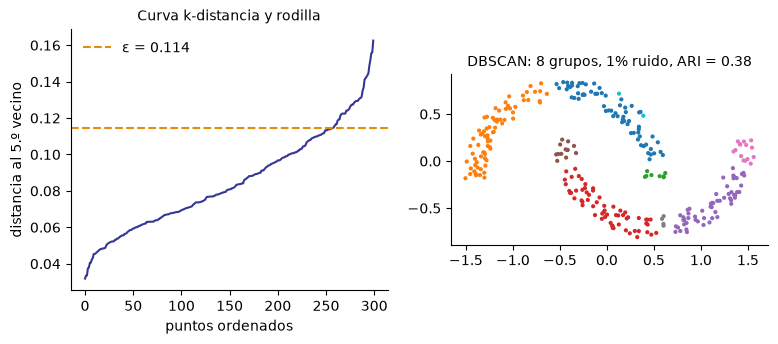

In [97]:
from sklearn.cluster import DBSCAN, OPTICS, SpectralClustering

def eps_rodilla(X, min_samples=5):
    d = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1])
    x = np.linspace(0, 1, len(d)); y = (d - d[0]) / max(d[-1] - d[0], 1e-12)
    return float(d[np.argmax(x - y)]), d

def dbscan_cero(X, eps, min_samples=5):
    vecinos = NearestNeighbors(radius=eps).fit(X).radius_neighbors(X, return_distance=False)
    nucleo = np.array([len(v) >= min_samples for v in vecinos])
    lab = np.full(len(X), -1); g = 0
    for t in range(len(X)):
        if not nucleo[t] or lab[t] != -1: continue
        pila = [t]; lab[t] = g
        while pila:
            u = pila.pop()
            if not nucleo[u]: continue
            for v in vecinos[u]:
                if lab[v] == -1:
                    lab[v] = g; pila.append(v)
        g += 1
    return lab

from common import knee_eps
eps_l, curva = eps_rodilla(dsl.X)
verifica(np.isclose(eps_l, knee_eps(dsl.X, 5)), f"ε por rodilla = {eps_l:.4f} (igual al de los scripts de la tesis)")
lab_db = dbscan_cero(dsl.X, eps_l)
lab_sk = DBSCAN(eps=eps_l, min_samples=5).fit_predict(dsl.X)
verifica(np.array_equal(lab_db == -1, lab_sk == -1) and ari(lab_db, lab_sk) == 1.0, "DBSCAN desde cero = scikit-learn (mismos núcleos, grupos y ruido)")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(curva, color=AZUL); ax[0].axhline(eps_l, color=NARANJA, ls="--", label=f"ε = {eps_l:.3f}")
ax[0].set_xlabel("puntos ordenados"); ax[0].set_ylabel("distancia al 5.º vecino"); ax[0].set_title("Curva k-distancia y rodilla"); ax[0].legend()
ax[1].scatter(dsl.X[:, 0], dsl.X[:, 1], c=np.where(lab_db < 0, 9, lab_db), cmap="tab10", s=4, vmin=0, vmax=9)
ax[1].set_aspect("equal"); ax[1].set_title(f"DBSCAN: {lab_db.max() + 1} grupos, {np.mean(lab_db < 0):.0%} ruido, ARI = {ari(dsl.y, lab_db):.2f}")
guardar(fig, "dbscan_rodilla", "3.4 Métodos comparados (DBSCAN)")
plt.show()

### **3.3.3 OPTICS**

**Definición** (Ankerst et al., 1999). Ordena los puntos por **distancia de alcanzabilidad** $\mathrm{reach}(u\mid t)=\max(\text{core}(t),\|t-u\|)$, con $\text{core}(t)$ = distancia al vecino `min_samples`. Los grupos aparecen como **valles** del diagrama de alcanzabilidad; el método ξ extrae valles cuya pendiente relativa supera `xi`.

**Supuestos y limitaciones.** Admite densidades distintas (no fija un único $\varepsilon$), pero sigue requiriendo `min_samples` y un tamaño mínimo de grupo; puede marcar mucho ruido. **Hiperparámetros:** `min_samples=7`, `xi=0.05`, `min_cluster_size=0.1`. Se usa la implementación de scikit-learn.

[figura 18] 18_optics_alcanzabilidad.png  →  3.4 Métodos comparados (OPTICS)


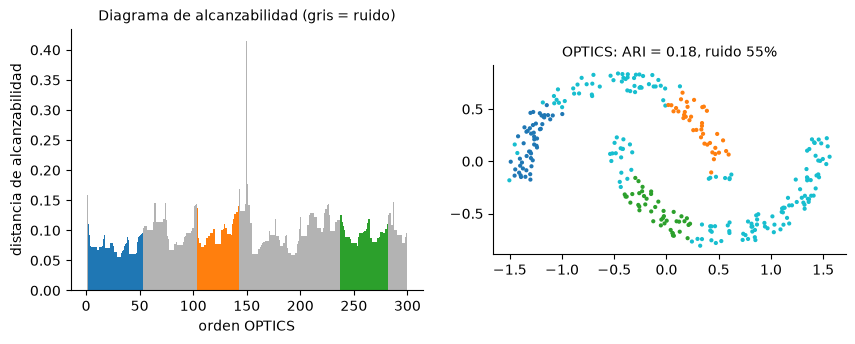

In [98]:
op = OPTICS(min_samples=7, xi=0.05, min_cluster_size=0.1).fit(dsl.X)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
reach = op.reachability_[op.ordering_]; lab_o = op.labels_[op.ordering_]
ax[0].bar(range(len(reach)), np.where(np.isfinite(reach), reach, np.nan), color=[plt.cm.tab10(l) if l >= 0 else (0.7, 0.7, 0.7) for l in lab_o], width=1)
ax[0].set_xlabel("orden OPTICS"); ax[0].set_ylabel("distancia de alcanzabilidad"); ax[0].set_title("Diagrama de alcanzabilidad (gris = ruido)")
ax[1].scatter(dsl.X[:, 0], dsl.X[:, 1], c=np.where(op.labels_ < 0, 9, op.labels_), cmap="tab10", s=4, vmin=0, vmax=9)
ax[1].set_aspect("equal"); ax[1].set_title(f"OPTICS: ARI = {ari(dsl.y, op.labels_):.2f}, ruido {np.mean(op.labels_ < 0):.0%}")
guardar(fig, "optics_alcanzabilidad", "3.4 Métodos comparados (OPTICS)")
plt.show()

### **3.3.4 Spectral Clustering**

**Definición** (Ng, Jordan y Weiss, 2002; von Luxburg, 2007). Embedding de Laplacian Eigenmaps con $k$ vectores propios seguido de K-Means.

**Ecuaciones.** Mismo grafo $k$-NN binario simetrizado y Laplaciano normalizado que en §3.2.4; $E=[u_1,\dots,u_k]/\sqrt d$ (sin descartar el primero); etiquetas = K-Means sobre $E$.

**Supuestos y limitaciones.** Los grupos son componentes casi desconectadas del grafo; sensible a $k$ vecinos y a puentes de ruido entre grupos. **Hiperparámetros:** $k$ grupos (real), `n_neighbors=10`, `affinity="nearest_neighbors"`. **Costo:** $O(N^3)$ denso.

**Relación con CD.** La mejora 1 (§4.2) conserva este esquema y **sólo cambia la matriz de pesos**: en lugar de 0/1 usa la afinidad de modelos CD locales.

compacto: ARI(desde cero, scikit-learn) = 1.000;  ARI contra la clase real: 0.90 / 0.90
no_convexo: ARI(desde cero, scikit-learn) = 1.000;  ARI contra la clase real: 1.00 / 1.00
entrelazado: ARI(desde cero, scikit-learn) = 1.000;  ARI contra la clase real: 0.46 / 0.46


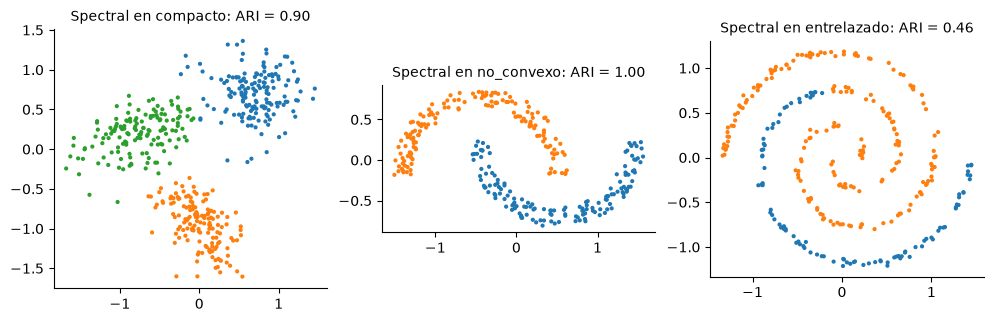

In [99]:
def spectral_cero(X, k, n_vecinos=10):
    E, _ = embedding_laplaciano(grafo_knn_binario(X, n_vecinos), p=k, quitar_primero=False)
    return KMeans(k, n_init=10, random_state=0).fit_predict(E), E

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, d_, nombre in zip(ax, (dsc, dsl, cargar_2d("entrelazado")), ("compacto", "no_convexo", "entrelazado")):
    l_c, _ = spectral_cero(d_.X, d_.n_groups)
    l_s = SpectralClustering(d_.n_groups, affinity="nearest_neighbors", n_neighbors=10, random_state=0).fit_predict(d_.X)
    print(f"{nombre}: ARI(desde cero, scikit-learn) = {ari(l_c, l_s):.3f};  ARI contra la clase real: {ari(d_.y, l_c):.2f} / {ari(d_.y, l_s):.2f}")
    a.scatter(d_.X[:, 0], d_.X[:, 1], c=l_c, cmap="tab10", s=4, vmin=0, vmax=9); a.set_aspect("equal")
    a.set_title(f"Spectral en {nombre}: ARI = {ari(d_.y, l_c):.2f}")
plt.show()

**Nota sobre la comprobación.** La versión desde cero usa `eigh` denso y la de scikit-learn ARPACK; los vectores propios coinciden salvo signo y rotación dentro de subespacios casi degenerados, por lo que en otros datos las particiones podrían diferir en algunos puntos (en los tres casos de arriba coinciden). En los benchmarks se usa la implementación de scikit-learn, idéntica a la de la tesis.

### **3.3.5 Pipeline UMAP + K-Means**

**Definición.** Primero UMAP a 2D (§3.2.5) y después K-Means con el número real de grupos. No es un método de agrupamiento en sí, sino la composición de un embedding y un agrupamiento; se incluye porque es la práctica común para datos no convexos.

**Limitación.** Hereda la estocasticidad de UMAP y la suposición de convexidad de K-Means **en el embedding**.

In [100]:
def umap_kmeans(X, k):
    return KMeans(k, n_init=10, random_state=0).fit_predict(umap_2d(X))
if UMAP_OK:
    l_uk = umap_kmeans(dsl.X, 2)
    print(f"UMAP + K-Means en no_convexo: ARI = {ari(dsl.y, l_uk):.2f}")

---
# **4. Evolución del método CD para agrupamiento**

La versión final del agrupamiento con CD es el resultado de dos mejoras, cada una motivada por una falla medida de la anterior:

| Versión | Idea | Falla que motivó la siguiente |
|---|---|---|
| **V0 · CD global** | un modelo CD por grupo; cada punto va al grupo donde es más típico | se comporta como K-Means: falla en lunas y anillos |
| **V1 · Afinidad CD local (mejora 1)** | un modelo CD de grado 1 por vecindad define un grafo; agrupamiento espectral sobre él | no separa espirales entrelazadas |
| **V2 · Fase angular con compuerta (mejora 2)** | se agrega una coordenada de fase $\psi=\theta-c\,g(r)$ sólo si los datos muestran devanado | se apaga con oclusión o densidad variable |

Cada versión se implementa **desde cero** con las funciones de §1 y se comprueba que produce **exactamente las mismas etiquetas** que la clase de la biblioteca usada en los scripts de la tesis.

## **4.1 V0 · CD global (versión inicial)**

**Problema que intenta resolver.** Usar directamente la función de Christoffel como modelo de cada grupo, análogo a una mezcla de gaussianas pero con soportes polinomiales.

**Formulación.** Con $k$ grupos y etiquetas $\hat y$:
1. Inicializar $\hat y$ con K-Means.
2. Para cada grupo $g$ con al menos $s+2$ puntos, ajustar $q^{(g)}_n$ (grado 2, $c=10^{-6}$).
3. Reasignar $\hat y_t=\arg\min_g \log q^{(g)}_n(x_t)$.
4. Repetir hasta que $\hat y$ no cambie (máximo 30 iteraciones).

**Advertencia teórica.** Comparar $q$ entre modelos distintos ignora $\log\det M^{(g)}$ y los tamaños de grupo: no es máxima verosimilitud ni EM, sino una **heurística de reasignación**.

✔ V0 desde cero = biblioteca en compacto (etiquetas idénticas)
✔ V0 desde cero = biblioteca en no_convexo (etiquetas idénticas)
✔ V0 desde cero = biblioteca en entrelazado (etiquetas idénticas)
✔ V0 desde cero = biblioteca en anidado (etiquetas idénticas)
✔ V0 desde cero = biblioteca en espiral_3brazos (etiquetas idénticas)
✔ V0 desde cero = biblioteca en espiral_log (etiquetas idénticas)
[figura 19] 19_v0_cd_global_iteraciones.png  →  4.4 Agrupamiento basado en CD (V0)


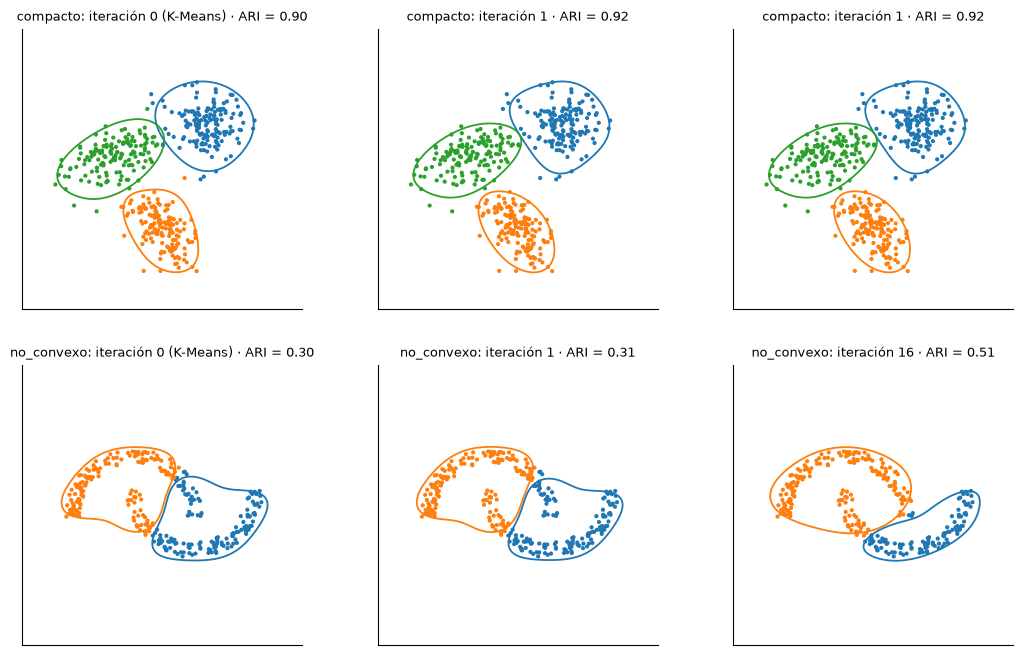

In [101]:
def cd_global_cero(X, k, grado=2, reg=1e-6, iteraciones=30, historial=False):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(X)
    s = tamano_base(X.shape[1], grado)
    hist = [lab.copy()]
    for _ in range(iteraciones):
        puntajes = np.full((len(X), k), np.inf)
        for g in range(k):
            miembros = X[lab == g]
            if len(miembros) < s + 2:
                continue
            puntajes[:, g] = np.log(q_cd(ajustar_cd(miembros, grado, reg), X))
        nuevo = np.argmin(puntajes, axis=1)
        if np.array_equal(nuevo, lab):
            break
        lab = nuevo; hist.append(lab.copy())
    return (lab, hist) if historial else lab

from pointfield.learning import CDGlobalClustering, CDLocalSpectral, CDSzegoSpectral
for caso in CASOS_2D:
    d_ = cargar_2d(caso)
    verifica(np.array_equal(cd_global_cero(d_.X, d_.n_groups), CDGlobalClustering(d_.n_groups, degree=2).fit_predict(d_.X)),
             f"V0 desde cero = biblioteca en {caso} (etiquetas idénticas)")

fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for fila, caso in enumerate(("compacto", "no_convexo")):
    d_ = cargar_2d(caso)
    lab, hist = cd_global_cero(d_.X, d_.n_groups, historial=True)
    for col, (paso, l_) in enumerate(((0, hist[0]), (1, hist[min(1, len(hist) - 1)]), (len(hist) - 1, lab))):
        a = ax[fila, col]
        GX, GY, G = malla(2.2, 160)
        for g in range(d_.n_groups):
            if (l_ == g).sum() > 8:
                mg = ajustar_cd(d_.X[l_ == g], 2, 1e-6)
                a.contour(GX, GY, q_cd(mg, G).reshape(GX.shape), levels=[np.percentile(q_cd(mg, d_.X[l_ == g]), 95)],
                          colors=[plt.cm.tab10(g)], linewidths=1.3)
        a.scatter(d_.X[:, 0], d_.X[:, 1], c=l_, cmap="tab10", s=4, vmin=0, vmax=9); a.set_aspect("equal")
        a.set_title(f"{caso}: iteración {paso}" + (" (K-Means)" if paso == 0 else "") + f" · ARI = {ari(d_.y, l_):.2f}", fontsize=9)
        a.set_xticks([]); a.set_yticks([])
guardar(fig, "v0_cd_global_iteraciones", "4.4 Agrupamiento basado en CD (V0)")
plt.show()

**Interpretación.** Las curvas de color son el contorno del 95 % de cada modelo CD de grado 2 (cónicas). En `compacto` las cónicas se ajustan bien a cada gaussiana y la reasignación mejora un poco a K-Means. En `no_convexo` cada luna requeriría una región no convexa que una cónica no puede describir: el algoritmo converge a una partición parecida a la de K-Means. **Conclusión:** un modelo global por grupo hereda las suposiciones de forma de su grado; para formas arbitrarias hace falta trabajar localmente.

## **4.2 V1 · Afinidad CD local + agrupamiento espectral (mejora 1)**

**Problema.** V0 necesita que cada grupo completo sea descrito por un polinomio de grado bajo.

**Modificación.** Usar CD **localmente**: para cada punto $x_i$, ajustar un modelo de grado 1 con sus $k+1$ vecinos más cercanos (incluido él mismo) y medir qué tan típicos son esos vecinos:
$$P_i(x_j)=v_1(x_j)^\top\big(M^{(i)}_1+\varepsilon I\big)^{-1}v_1(x_j)=1+\text{Mahalanobis}^2_{\Sigma_i}(x_j),\quad j\in\mathcal N_i.$$
Se estandariza de forma robusta dentro de la vecindad, $z_{ij}=(P_i(x_j)-\operatorname{med}_i)/\operatorname{MAD}_i$, y la afinidad es
$$A_{ij}=\exp(-z_{ij}^2/2),\qquad A\leftarrow\max(A,A^\top),\qquad A_{ii}=0.$$
Después: embedding espectral con $k$ vectores (Laplaciano normalizado), normalización de filas (Ng–Jordan–Weiss) y K-Means.

**Intuición.** El grafo binario k-NN trata igual a todos los vecinos. La covarianza local de grado 1 es una elipse orientada según la estructura; los vecinos que caen fuera de la orientación local (por ejemplo, el vecino que está en la otra luna o en el otro anillo) reciben peso menor.

**Dimensiones.** Para cada $i$: base local $B_i:(k+1)\times(d+1)$, $M^{(i)}:(d+1)\times(d+1)$; $A:N\times N$ dispersa con $\le N(k+1)$ entradas no nulas antes de simetrizar. **Costo:** $O(N\,k\,d^2)$ para la afinidad más el espectral.

In [102]:
from sklearn.manifold import spectral_embedding
import scipy.linalg

def afinidad_cd_local(X, n_vecinos=10, grado=1, reg=1e-6, peso="gaussian", cholesky="scipy"):
    N = len(X)
    vecinos = NearestNeighbors(n_neighbors=min(n_vecinos + 1, N)).fit(X).kneighbors(X, return_distance=False)
    terms = exponentes(X.shape[1], grado)
    A = np.zeros((N, N))
    for i, nb in enumerate(vecinos):
        B = matriz_caracteristicas(X[nb], terms)                 # (k+1) × s
        M = B.T @ B / len(nb)
        M += reg * np.trace(M) / len(M) * np.eye(len(M))
        L_ = scipy.linalg.cholesky(M, lower=True) if cholesky == "scipy" else np.linalg.cholesky(M)   # misma rutina que la biblioteca por defecto
        Zw = solve_triangular(L_, B.T, lower=True)
        P = np.einsum("ij,ij->j", Zw, Zw)                         # P_i(x_j) para los vecinos
        med = np.median(P); mad = np.median(np.abs(P - med)) + 1e-12
        z = (P - med) / mad
        A[i, nb] = np.exp(-0.5 * z ** 2) if peso == "gaussian" else np.exp(-np.maximum(z, 0.0))
    A = np.maximum(A, A.T); np.fill_diagonal(A, 0.0)
    return A

def espectral_sobre(A, k, semilla=0):
    "Embedding espectral con k vectores, filas normalizadas (Ng–Jordan–Weiss) y K-Means."
    E = spectral_embedding(A, n_components=k, drop_first=False, random_state=semilla)
    E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)
    return KMeans(k, n_init=10, random_state=semilla).fit_predict(E), E

def cd_local_cero(X, k, n_vecinos=10, grado=1, peso="gaussian"):
    return espectral_sobre(afinidad_cd_local(X, n_vecinos, grado, peso=peso), k)[0]

from pointfield.learning import local_cd_affinity
for caso in CASOS_2D:
    d_ = cargar_2d(caso)
    A_mio = afinidad_cd_local(d_.X)
    verifica(np.allclose(A_mio, local_cd_affinity(d_.X, 10, 1), atol=1e-12) and
             np.array_equal(cd_local_cero(d_.X, d_.n_groups), CDLocalSpectral(d_.n_groups, n_neighbors=10, degree=1).fit_predict(d_.X)),
             f"V1 desde cero = biblioteca en {caso} (afinidad y etiquetas idénticas)")

✔ V1 desde cero = biblioteca en compacto (afinidad y etiquetas idénticas)
✔ V1 desde cero = biblioteca en no_convexo (afinidad y etiquetas idénticas)
✔ V1 desde cero = biblioteca en entrelazado (afinidad y etiquetas idénticas)
✔ V1 desde cero = biblioteca en anidado (afinidad y etiquetas idénticas)
✔ V1 desde cero = biblioteca en espiral_3brazos (afinidad y etiquetas idénticas)
✔ V1 desde cero = biblioteca en espiral_log (afinidad y etiquetas idénticas)


no_convexo: % de peso entre clases  binario = 0.00 %,  CD local = 0.00 %
entrelazado: % de peso entre clases  binario = 1.56 %,  CD local = 0.03 %
[figura 20] 20_v1_afinidad_local.png  →  4.4 Agrupamiento basado en CD (V1)


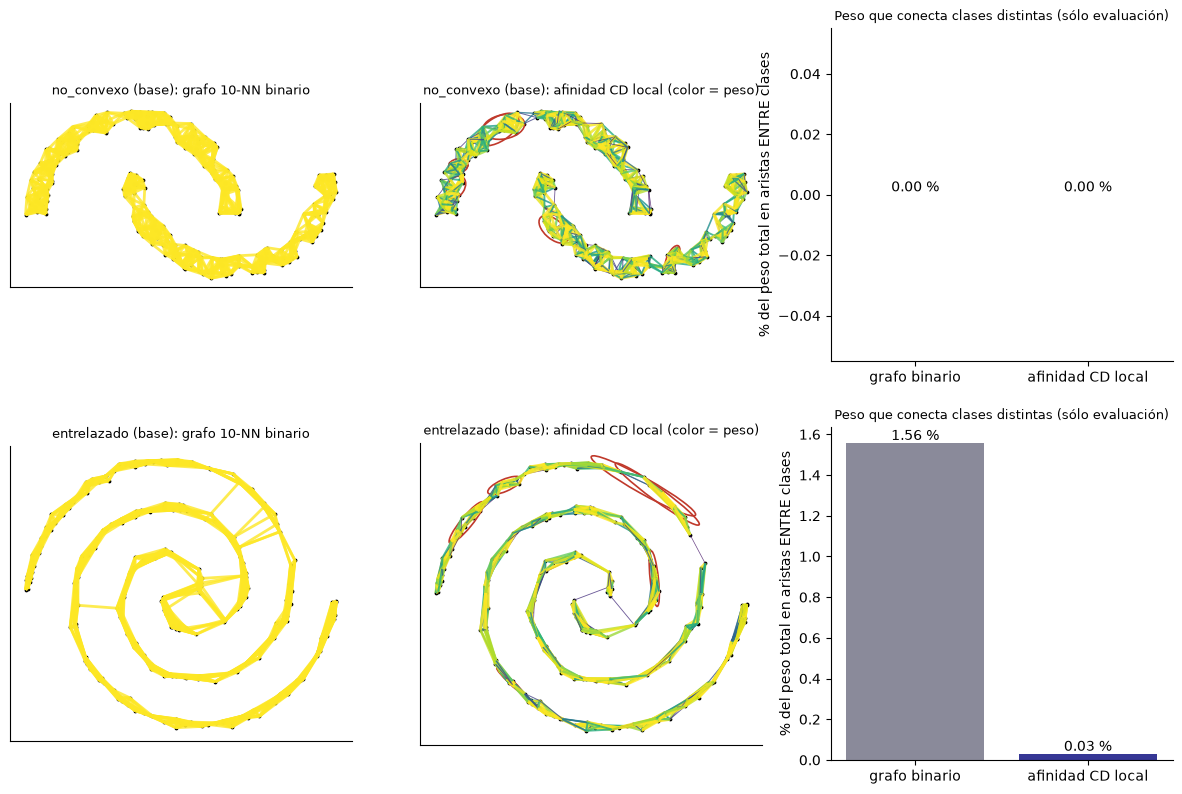

In [103]:
from matplotlib.collections import LineCollection
from matplotlib.patches import Ellipse as ElipseMPL

def dibujar_grafo(ax, X, A, titulo, umbral=0.05):
    i, j = np.nonzero(np.triu(A) > umbral)
    seg = np.stack([X[i], X[j]], axis=1)
    lc = LineCollection(seg, linewidths=0.4 + 1.6 * A[i, j], colors=plt.cm.viridis(A[i, j]), alpha=0.8)
    ax.add_collection(lc); ax.scatter(X[:, 0], X[:, 1], s=3, c="k"); ax.set_aspect("equal"); ax.set_title(titulo, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(2, 3, figsize=(15, 9.5))
for fila, (caso, var) in enumerate((("no_convexo", "base"), ("entrelazado", "base"))):
    d_ = cargar_2d(caso, var); X = d_.X
    A_cd = afinidad_cd_local(X)
    A_bin = np.zeros_like(A_cd)
    vec = NearestNeighbors(n_neighbors=11).fit(X).kneighbors(X, return_distance=False)
    for i_, nb in enumerate(vec): A_bin[i_, nb] = 1.0
    A_bin = np.maximum(A_bin, A_bin.T); np.fill_diagonal(A_bin, 0)
    dibujar_grafo(ax[fila, 0], X, A_bin, f"{caso} ({var}): grafo 10-NN binario")
    dibujar_grafo(ax[fila, 1], X, A_cd, f"{caso} ({var}): afinidad CD local (color = peso)")
    for t in np.random.default_rng(3).choice(len(X), 6, replace=False):           # elipses locales: 1 + Mahalanobis² = 5 (dos desviaciones)
        nb = vec[t]; mu = X[nb].mean(0); S = np.cov(X[nb].T, bias=True) + 1e-9 * np.eye(2)
        w, U = np.linalg.eigh(S); ang = np.degrees(np.arctan2(U[1, 1], U[0, 1]))
        ax[fila, 1].add_patch(ElipseMPL(mu, 2 * np.sqrt(w[1]) * 2, 2 * np.sqrt(w[0]) * 2, angle=ang, fill=False, color=ROJO, lw=1.2))
    misma = d_.y[:, None] == d_.y[None, :]
    fr = {}
    for A_, nombre in ((A_bin, "grafo binario"), (A_cd, "afinidad CD local")):
        mask = np.triu(A_ > 0, 1)
        fr[nombre] = 100 * A_[mask & ~misma].sum() / A_[mask].sum()
    ax[fila, 2].bar(list(fr), list(fr.values()), color=[GRIS, AZUL])
    for k_, v_ in enumerate(fr.values()): ax[fila, 2].text(k_, v_, f"{v_:.2f} %", ha="center", va="bottom")
    ax[fila, 2].set_ylabel("% del peso total en aristas ENTRE clases"); ax[fila, 2].set_title("Peso que conecta clases distintas (sólo evaluación)", fontsize=9)
    print(f"{caso}: % de peso entre clases  binario = {fr['grafo binario']:.2f} %,  CD local = {fr['afinidad CD local']:.2f} %")
guardar(fig, "v1_afinidad_local", "4.4 Agrupamiento basado en CD (V1)")
plt.show()

**Interpretación.** Columna central: el color de cada arista es su peso y las elipses rojas son el nivel $q=5$ ($1+$Mahalanobis$^2=5$, es decir, dos desviaciones locales) de algunos modelos locales; siguen la orientación de la curva. Columna derecha: porcentaje del peso total del grafo que cae en aristas que unen puntos de clases **distintas** (las etiquetas sólo se usan para esta medición). En las lunas limpias no hay aristas entre clases en ninguno de los dos grafos: por eso ambos resuelven el caso (la ablación de §4.5 lo confirma). En las espirales, los dos grafos tienen aristas entre brazos vecinos; reponderarlas no basta para desconectar los brazos, y por eso V1 falla en espirales y hace falta la fase (V2).

## **4.3 V2 · Fase angular con compuerta (mejora 2)**

**Problema.** En espirales entrelazadas, los vecinos de un punto en un brazo incluyen puntos del brazo vecino (la separación entre brazos es comparable a la distancia entre puntos), y ningún grafo local los separa.

**Modificación.** En una espiral $r=a+b\theta$, la cantidad $\theta-r/b$ es **constante en cada brazo**. Se busca, sin etiquetas, una fase
$$\psi(x)=\theta(x)-c\,g(r(x)),\qquad g\in\{\text{identidad},\;\log\},$$
tal que los puntos formen $k$ arcos compactos en el círculo $(\cos\psi,\sin\psi)$. El parámetro se escribe como vueltas: $c=2\pi\,t/(g(r_{99})-g(r_1))$, con $t\in[-3,3]$ (121 valores + refinamiento local). El criterio es la **silueta** de K-Means sobre $(\cos\psi,\sin\psi)$.

**Compuerta.** Ganancia de devanado $=\text{sil}(\psi^\*)-\text{sil}(\theta)$ (silueta con la mejor fase menos la del ángulo sin torcer). Si es $\ge 0.20$, se agregan $(\cos\psi,\sin\psi)$ como coordenadas y se aplica V1 sobre $[x,\cos\psi,\sin\psi]$; si no, V2 = V1. **El umbral 0.20 se fijó con las semillas de desarrollo 0–2**, nunca con las de evaluación.

**Nombre.** En el código se llama "fase de Szegő" por razones históricas; no usa el núcleo de Szegő.

In [104]:
from sklearn.metrics import silhouette_score

def g_radial(r, forma):
    return r if forma == "lin" else np.log(r + 1e-3)

def fase(X, c, forma):
    return np.arctan2(X[:, 1], X[:, 0]) - c * g_radial(np.linalg.norm(X[:, :2], axis=1), forma)

def c_de_vueltas(X, vueltas, forma):
    g = g_radial(np.linalg.norm(X[:, :2], axis=1), forma)
    lo, hi = np.percentile(g, [1, 99])
    return 2 * np.pi * vueltas / max(hi - lo, 1e-9)

def kmeans_rapido(F, k, rng, n_init=3, n_iter=30):
    "Lloyd mínimo con k-means++ (el mismo de la biblioteca): ~260 ajustes por búsqueda."
    mejor, mejor_J = None, np.inf
    for _ in range(n_init):
        C = [F[rng.integers(len(F))]]
        for _ in range(1, k):
            d2 = np.min(((F[:, None, :] - np.array(C)[None]) ** 2).sum(-1), axis=1)
            C.append(F[rng.choice(len(F), p=d2 / d2.sum())] if d2.sum() > 0 else F[rng.integers(len(F))])
        C = np.array(C)
        for _ in range(n_iter):
            lab = np.argmin(((F[:, None, :] - C[None]) ** 2).sum(-1), axis=1)
            nuevo = np.array([F[lab == j].mean(0) if np.any(lab == j) else C[j] for j in range(k)])
            if np.allclose(nuevo, C): break
            C = nuevo
        lab = np.argmin(((F[:, None, :] - C[None]) ** 2).sum(-1), axis=1)
        J = ((F - C[lab]) ** 2).sum()
        if J < mejor_J: mejor, mejor_J = lab, J
    return mejor

def silueta_fase(sub, c, forma, k, semilla=0):
    psi = fase(sub, c, forma); F = np.column_stack((np.cos(psi), np.sin(psi)))
    lab = kmeans_rapido(F, k, np.random.default_rng(semilla))
    return -1.0 if len(np.unique(lab)) < 2 else float(silhouette_score(F, lab))

def buscar_fase(X, k, semilla=0, max_puntos=500, rejilla=np.linspace(-3.0, 3.0, 121), formas=("lin", "log")):
    rng = np.random.default_rng(semilla)
    sub = X if len(X) <= max_puntos else X[rng.choice(len(X), max_puntos, replace=False)]
    mejor = (-np.inf, 0.0, "lin"); paso = rejilla[1] - rejilla[0]; curvas = {}
    for forma in formas:
        curvas[forma] = [silueta_fase(sub, c_de_vueltas(X, t, forma), forma, k, semilla) for t in rejilla]
        t0 = rejilla[int(np.argmax(curvas[forma]))]
        for t in np.linspace(t0 - paso, t0 + paso, 11):
            s_ = silueta_fase(sub, c_de_vueltas(X, t, forma), forma, k, semilla)
            if s_ > mejor[0]: mejor = (s_, float(t), forma)
    base = silueta_fase(sub, 0.0, "lin", k, semilla)
    return {"silueta": mejor[0], "vueltas": mejor[1], "forma": mejor[2], "c": c_de_vueltas(X, mejor[1], mejor[2]),
            "silueta_base": base, "ganancia": mejor[0] - base, "curvas": curvas, "rejilla": rejilla}

UMBRAL_FASE = 0.20

def cd_fase_cero(X, k, n_vecinos=10, umbral=UMBRAL_FASE, devolver_info=False, info=None):
    info = info or buscar_fase(X, k)
    activa = info["ganancia"] >= umbral
    Z = np.column_stack((X, np.cos(fase(X, info["c"], info["forma"])), np.sin(fase(X, info["c"], info["forma"])))) if activa else X
    lab = cd_local_cero(Z, k, n_vecinos)
    return (lab, activa, info) if devolver_info else lab

INFO_FASE = {}
for caso in CASOS_2D:
    d_ = cargar_2d(caso)
    lab, activa, info = cd_fase_cero(d_.X, d_.n_groups, devolver_info=True)
    INFO_FASE[caso] = info
    lib = CDSzegoSpectral(d_.n_groups, n_neighbors=10, degree=1, gate=UMBRAL_FASE)
    verifica(np.array_equal(lab, lib.fit_predict(d_.X)) and np.isclose(info["ganancia"], lib.phase_.winding_gain_) and activa == lib.active_,
             f"V2 desde cero = biblioteca en {caso} (vueltas {info['vueltas']:+.2f}, g = {info['forma']}, ganancia {info['ganancia']:.2f}, fase {'activa' if activa else 'inactiva'})")

✔ V2 desde cero = biblioteca en compacto (vueltas +0.11, g = log, ganancia 0.02, fase inactiva)
✔ V2 desde cero = biblioteca en no_convexo (vueltas +0.48, g = log, ganancia 0.23, fase activa)
✔ V2 desde cero = biblioteca en entrelazado (vueltas +1.47, g = lin, ganancia 0.29, fase activa)
✔ V2 desde cero = biblioteca en anidado (vueltas -1.74, g = log, ganancia 0.02, fase inactiva)
✔ V2 desde cero = biblioteca en espiral_3brazos (vueltas +1.19, g = lin, ganancia 0.37, fase activa)
✔ V2 desde cero = biblioteca en espiral_log (vueltas +2.35, g = log, ganancia 0.28, fase activa)


[figura 21] 21_v2_busqueda_fase.png  →  4.4 Agrupamiento basado en CD (V2)


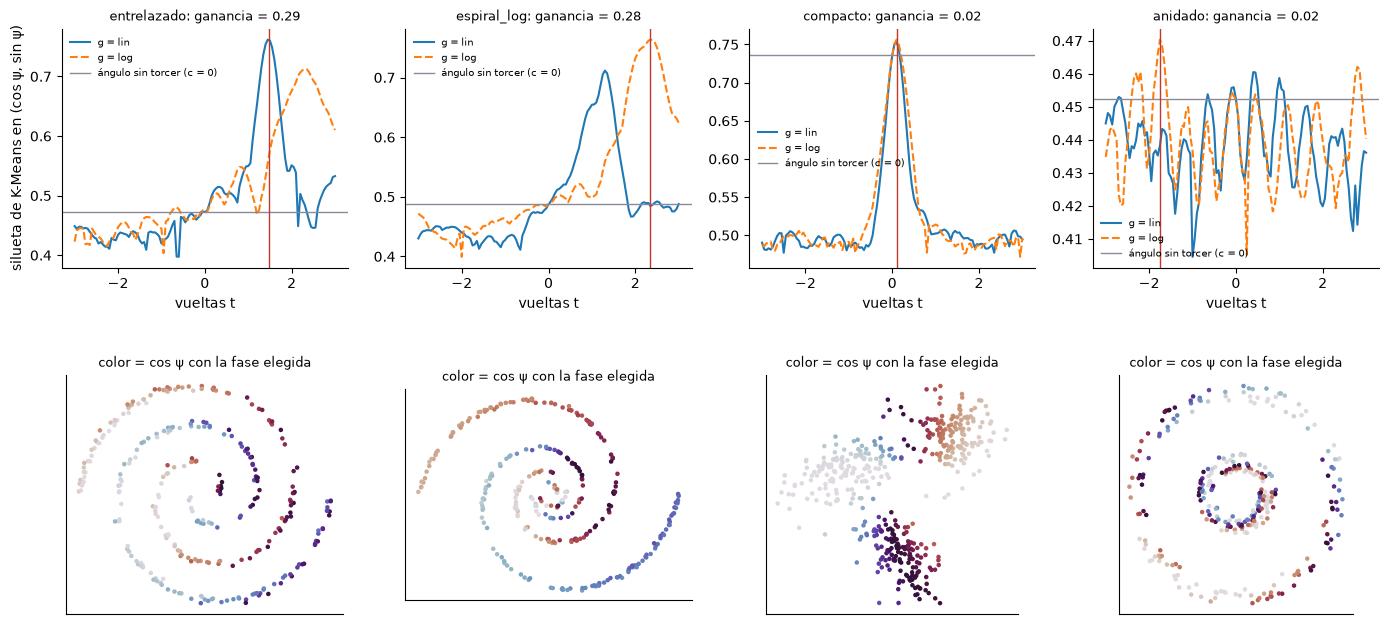

In [105]:
fig, ax = plt.subplots(2, 4, figsize=(17, 7.6))
for j, caso in enumerate(("entrelazado", "espiral_log", "compacto", "anidado")):
    d_, info = cargar_2d(caso), INFO_FASE[caso]
    for forma, est in (("lin", "-"), ("log", "--")):
        ax[0, j].plot(info["rejilla"], info["curvas"][forma], est, label=f"g = {forma}")
    ax[0, j].axhline(info["silueta_base"], color=GRIS, lw=1, label="ángulo sin torcer (c = 0)")
    ax[0, j].axvline(info["vueltas"], color=ROJO, lw=1)
    ax[0, j].set_title(f"{caso}: ganancia = {info['ganancia']:.2f}", fontsize=9); ax[0, j].set_xlabel("vueltas t"); ax[0, j].legend(fontsize=7)
    psi = fase(d_.X, info["c"], info["forma"])
    ax[1, j].scatter(d_.X[:, 0], d_.X[:, 1], c=np.cos(psi), cmap="twilight", s=5); ax[1, j].set_aspect("equal")
    ax[1, j].set_title("color = cos ψ con la fase elegida", fontsize=9); ax[1, j].set_xticks([]); ax[1, j].set_yticks([])
ax[0, 0].set_ylabel("silueta de K-Means en (cos ψ, sin ψ)")
fig.subplots_adjust(hspace=0.45)
guardar(fig, "v2_busqueda_fase", "4.4 Agrupamiento basado en CD (V2)")
plt.show()

**Interpretación.** En las espirales, la silueta tiene un máximo agudo en el número de vueltas correcto, muy por encima del ángulo sin torcer (ganancia alta), y con esa fase cada brazo tiene un color constante. En `compacto` o `anidado` torcer el ángulo no mejora nada (ganancia ≈ 0): la compuerta deja la fase apagada.

### **4.3.1 Fijar el umbral de la compuerta con las semillas de desarrollo**

Separación estricta entre **selección** (semillas 0–2) y **evaluación** (semillas 100–104): aquí se calcula la ganancia de devanado en los cuatro escenarios de desarrollo y sus perturbaciones, sólo con las semillas 0–2.

[figura 22] 22_v2_umbral_desarrollo.png  →  3.5 Protocolo (selección del umbral)


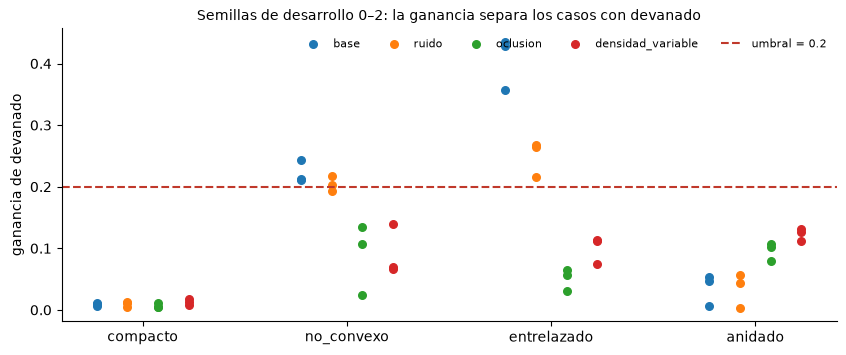

**Ganancia mínima y máxima por caso (semillas de desarrollo)**

min                                    max                    \
variante     base densidad_variable oclusion ruido  base densidad_variable   
caso                                                                         
compacto     0.01              0.01     0.01  0.01  0.01              0.02   
no_convexo   0.21              0.07     0.02  0.19  0.24              0.14   
entrelazado  0.36              0.08     0.03  0.22  0.44              0.11   
anidado      0.01              0.11     0.08  0.00  0.05              0.13   

                            
variante    oclusion ruido  
caso                        
compacto        0.01  0.01  
no_convexo      0.13  0.22  
entrelazado     0.06  0.27  
anidado         0.11  0.06

In [106]:
def _ganancias_desarrollo():
    filas = []
    for caso in CASOS_2D[:4]:
        for var in CONFIG["VARIANTES_2D"]:
            for sem in CONFIG["SEMILLAS_DESARROLLO"]:
                d_ = cargar_2d(caso, var, sem)
                filas.append({"caso": caso, "variante": var, "semilla": sem, "ganancia": buscar_fase(d_.X, d_.n_groups)["ganancia"]})
    return pd.DataFrame(filas)
GAN_DEV = en_cache("ganancias_desarrollo", _ganancias_desarrollo)

fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (caso, g) in enumerate(GAN_DEV.groupby("caso", sort=False)):
    for j, (var, gg) in enumerate(g.groupby("variante", sort=False)):
        ax.scatter(np.full(len(gg), i + (j - 1.5) * 0.15), gg.ganancia, color=plt.cm.tab10(j), s=30, label=var if i == 0 else None)
ax.axhline(UMBRAL_FASE, color=ROJO, ls="--", label=f"umbral = {UMBRAL_FASE}")
ax.set_xticks(range(4)); ax.set_xticklabels(CASOS_2D[:4]); ax.set_ylabel("ganancia de devanado"); ax.legend(fontsize=8, ncol=5)
ax.set_title("Semillas de desarrollo 0–2: la ganancia separa los casos con devanado")
guardar(fig, "v2_umbral_desarrollo", "3.5 Protocolo (selección del umbral)")
plt.show()
tabla(GAN_DEV.pivot_table(index="caso", columns="variante", values="ganancia", aggfunc=["min", "max"]).reindex(CASOS_2D[:4]), 2,
      "Ganancia mínima y máxima por caso (semillas de desarrollo)")

**Interpretación.** El umbral 0.20 deja fuera a `compacto` y `anidado` en todas sus variantes y deja dentro a las espirales limpias, que tienen la ganancia más alta. Las lunas limpias quedan cerca del umbral y la fase puede activarse en ellas; eso no las perjudica (V2 obtiene el mismo ARI que V1 en lunas, §4.4), porque la fase sólo se agrega como coordenada adicional. Con ruido, la ganancia de `entrelazado` se acerca al umbral, así que la fase se activa sólo en parte de las semillas. Con oclusión o densidad variable la ganancia de las espirales cae claramente por debajo, porque el centro de devanado (la media de los datos) se desplaza y la fase deja de ser constante en cada brazo: la compuerta se cierra y V2 vuelve a V1. Esta es la limitación principal de la mejora 2.

## **4.4 Antes y después: V0 → V1 → V2 en los seis escenarios**

Misma semilla de evaluación, mismos datos, mismos $k$. Se mide ARI y tiempo.

[figura 23] 23_evolucion_v0_v1_v2.png  →  5.2 Agrupamiento 2D (evolución del método)


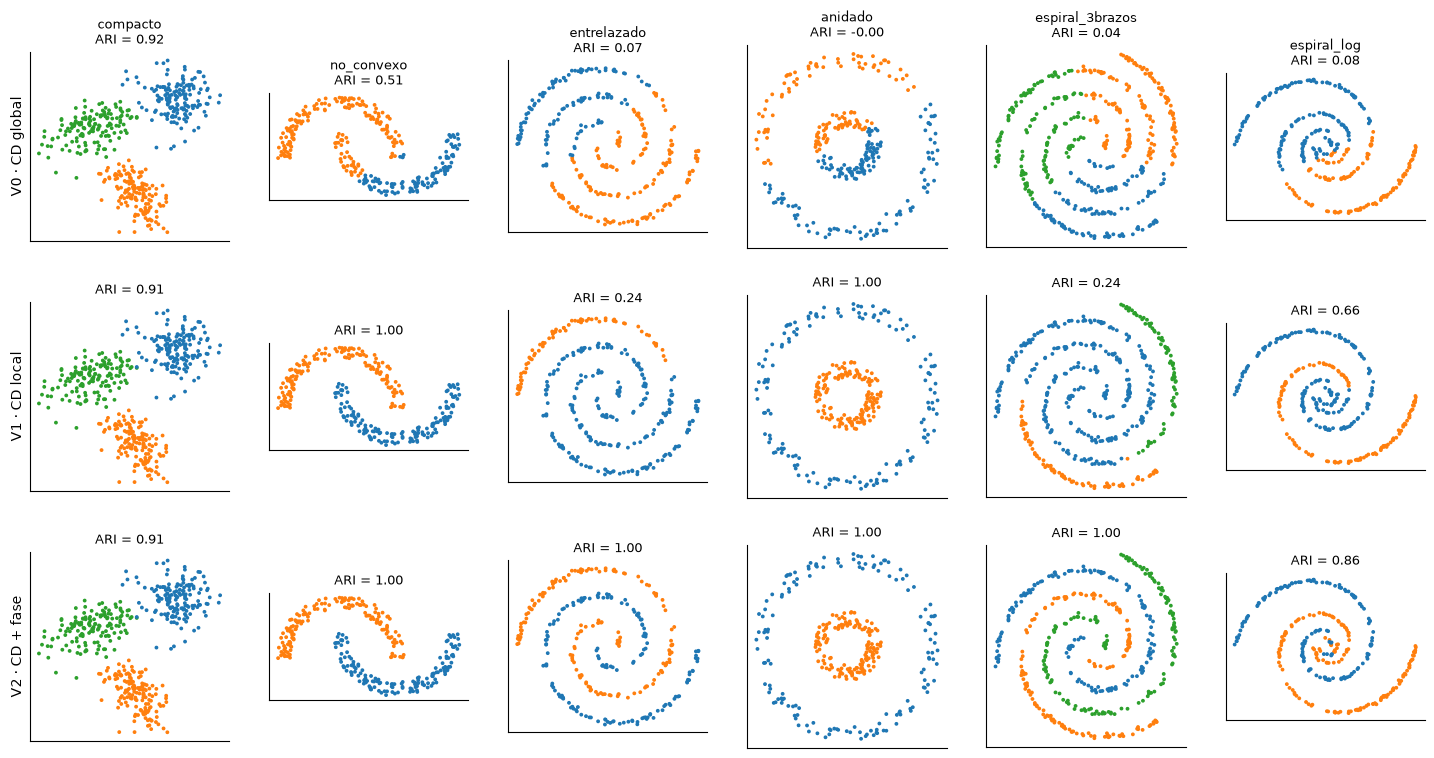

**ARI por versión (semilla 100, sin perturbar)**

versión,V0 · CD global,V1 · CD local,V2 · CD + fase
caso,,,
compacto,0.92,0.91,0.91
no_convexo,0.51,1.00,1.00
entrelazado,0.07,0.24,1.00
anidado,-0.00,1.00,1.00
espiral_3brazos,0.04,0.24,1.00
espiral_log,0.08,0.66,0.86


,tiempo medio (s)
versión,
V0 · CD global,0.092
V1 · CD local,0.352
V2 · CD + fase,4.607


In [107]:
VERSIONES_CD = {"V0 · CD global": lambda X, k: cd_global_cero(X, k),
                "V1 · CD local": lambda X, k: cd_local_cero(X, k),
                "V2 · CD + fase": lambda X, k: cd_fase_cero(X, k)}
sem0 = CONFIG["SEMILLAS_EVALUACION"][0]
fig, ax = plt.subplots(3, 6, figsize=(18, 9.2))
filas = []
for j, caso in enumerate(CASOS_2D):
    d_ = cargar_2d(caso, "base", sem0)
    for i, (nombre, f) in enumerate(VERSIONES_CD.items()):
        lab, dt, mb = medir(f, d_.X, d_.n_groups)
        filas.append({"caso": caso, "versión": nombre, "ARI": ari(d_.y, lab), "tiempo (s)": dt})
        a = ax[i, j]; a.scatter(d_.X[:, 0], d_.X[:, 1], c=lab, cmap="tab10", s=3, vmin=0, vmax=9); a.set_aspect("equal")
        a.set_xticks([]); a.set_yticks([]); a.set_title(f"ARI = {ari(d_.y, lab):.2f}", fontsize=9)
        if j == 0: a.set_ylabel(nombre)
    ax[0, j].set_title(f"{caso}\nARI = {filas[-3]['ARI']:.2f}", fontsize=9)
guardar(fig, "evolucion_v0_v1_v2", "5.2 Agrupamiento 2D (evolución del método)")
plt.show()
evo = pd.DataFrame(filas)
tabla(evo.pivot(index="caso", columns="versión", values="ARI").reindex(CASOS_2D), 2, f"ARI por versión (semilla {sem0}, sin perturbar)")
tabla(evo.groupby("versión")["tiempo (s)"].mean().to_frame("tiempo medio (s)"), 3)

## **4.5 Estudio de ablación: ¿qué parte de cada mejora aporta?**

Para no atribuir a CD lo que hace otra pieza, se comparan variantes que quitan o sustituyen un componente a la vez, con el **mismo** embedding espectral y la misma $k=10$:

| Variante | Qué cambia respecto a V1/V2 |
|---|---|
| Spectral k-NN (scikit-learn) | grafo binario y embedding sin normalizar filas |
| Grafo binario + espectral de V1 | **sólo quita los pesos CD** (todas las aristas valen 1) |
| V1 (pesos CD gaussianos) | la mejora 1 |
| V1 con peso monótono | $A=\exp(-\max(0,z))$: peso no creciente en $P$ |
| V1 con grado local 2 | cónicas locales en vez de elipses |
| Fase sola + K-Means | **sólo** la coordenada $(\cos\psi,\sin\psi)$, sin grafo CD |
| V2 sin compuerta | la fase siempre activa |
| V2 | la mejora 2 completa |

**Ablación · ARI medio · variante base**

caso,compacto,no_convexo,entrelazado,anidado,espiral_3brazos,espiral_log
método,,,,,,
Spectral k-NN,0.90,1.00,0.46,1.0,0.21,0.66
binario + espectral V1,0.90,1.00,0.44,1.0,0.17,0.46
V1 (pesos CD),0.91,1.00,0.24,1.0,0.24,0.66
V1 peso monótono,0.92,1.00,0.24,1.0,0.24,0.66
V1 grado local 2,0.89,1.00,0.46,1.0,0.32,0.66
fase sola + K-Means,0.93,0.95,1.00,-0.0,1.00,0.86
V2 sin compuerta,0.91,1.00,1.00,1.0,1.00,0.86
V2,0.91,1.00,1.00,1.0,1.00,0.86


**Ablación · ARI medio · variante ruido**

caso,compacto,no_convexo,entrelazado,anidado,espiral_3brazos,espiral_log
método,,,,,,
Spectral k-NN,0.92,1.00,0.06,1.0,0.11,0.18
binario + espectral V1,0.93,0.82,0.06,1.0,0.03,0.22
V1 (pesos CD),0.93,1.00,0.06,1.0,0.13,0.33
V1 peso monótono,0.93,1.00,0.06,1.0,0.13,0.33
V1 grado local 2,0.93,1.00,0.05,1.0,0.13,0.32
fase sola + K-Means,0.93,0.95,0.95,0.0,0.96,0.82
V2 sin compuerta,0.83,0.97,1.00,1.0,0.54,0.36
V2,0.93,0.97,0.06,1.0,0.13,0.36


[figura 24] 24_ablacion_agrupamiento.png  →  5.7 Análisis frente a la hipótesis (ablación)


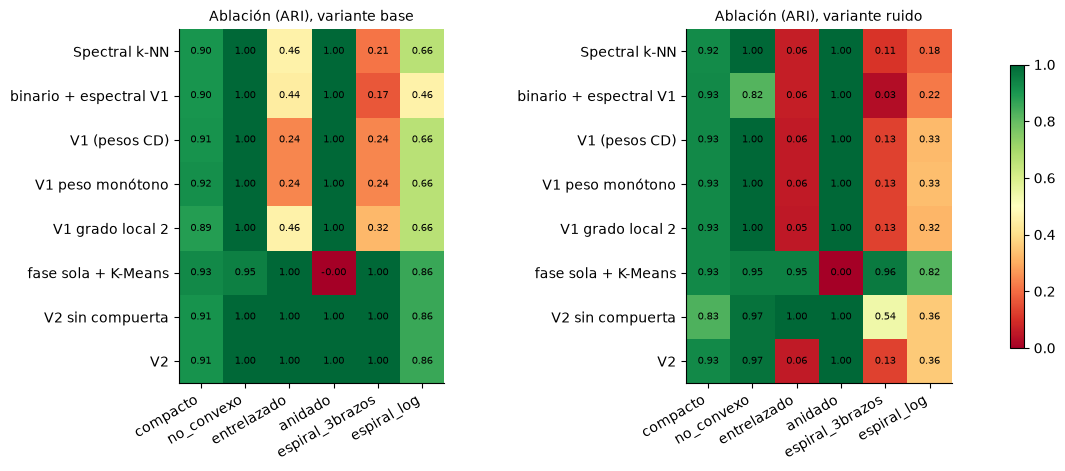

In [108]:
def afinidad_binaria_v1(X, n_vecinos=10):
    A = np.zeros((len(X), len(X)))
    for i, nb in enumerate(NearestNeighbors(n_neighbors=n_vecinos + 1).fit(X).kneighbors(X, return_distance=False)):
        A[i, nb] = 1.0
    A = np.maximum(A, A.T); np.fill_diagonal(A, 0); return A

def fase_sola(X, k, info):
    psi = fase(X, info["c"], info["forma"])
    return KMeans(k, n_init=10, random_state=0).fit_predict(np.column_stack((np.cos(psi), np.sin(psi))))

def _ablacion():
    filas = []
    for caso in CASOS_2D:
        for var in ("base", "ruido"):
            for sem in CONFIG["SEMILLAS_EVALUACION"]:
                d_ = cargar_2d(caso, var, sem); X, k = d_.X, d_.n_groups
                info = buscar_fase(X, k)
                variantes = {
                    "Spectral k-NN": lambda: SpectralClustering(k, affinity="nearest_neighbors", n_neighbors=10, random_state=0).fit_predict(X),
                    "binario + espectral V1": lambda: espectral_sobre(afinidad_binaria_v1(X), k)[0],
                    "V1 (pesos CD)": lambda: cd_local_cero(X, k),
                    "V1 peso monótono": lambda: cd_local_cero(X, k, peso="monotone"),
                    "V1 grado local 2": lambda: cd_local_cero(X, k, grado=2),
                    "fase sola + K-Means": lambda: fase_sola(X, k, info),
                    "V2 sin compuerta": lambda: cd_fase_cero(X, k, umbral=-np.inf, info=info),
                    "V2": lambda: cd_fase_cero(X, k, info=info),
                }
                for nombre, f in variantes.items():
                    filas.append({"caso": caso, "variante": var, "semilla": sem, "método": nombre, "ARI": ari(d_.y, f())})
    return pd.DataFrame(filas)
ABL = en_cache("ablacion_cd", _ablacion)
for var in ("base", "ruido"):
    t = ABL[ABL.variante == var].pivot_table(index="método", columns="caso", values="ARI").reindex(columns=CASOS_2D)
    t = t.reindex(ABL["método"].unique())
    tabla(t, 2, f"Ablación · ARI medio · variante {var}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, var in zip(ax, ("base", "ruido")):
    t = ABL[ABL.variante == var].pivot_table(index="método", columns="caso", values="ARI").reindex(index=ABL["método"].unique(), columns=CASOS_2D)
    im = a.imshow(t.values, cmap="RdYlGn", vmin=0, vmax=1)
    a.set_xticks(range(len(CASOS_2D))); a.set_xticklabels(CASOS_2D, rotation=30, ha="right"); a.set_yticks(range(len(t))); a.set_yticklabels(t.index)
    for (r_, c_), v in np.ndenumerate(t.values): a.text(c_, r_, f"{v:.2f}", ha="center", va="center", fontsize=7)
    a.set_title(f"Ablación (ARI), variante {var}")
fig.colorbar(im, ax=ax, shrink=0.8)
guardar(fig, "ablacion_agrupamiento", "5.7 Análisis frente a la hipótesis (ablación)")
plt.show()

**Cómo leer la ablación.**
* Si "binario + espectral V1" ya obtiene ARI ≈ 1 en un caso, ese caso **no** es evidencia a favor de los pesos CD: lo resuelve el grafo.
* Si "fase sola + K-Means" obtiene ARI ≈ 1 en las espirales, el mérito de V2 en ellas es de la **fase**, no de CD.
* "V2 sin compuerta" muestra el costo de activar la fase donde no hay devanado: por eso la compuerta es necesaria.

Las conclusiones de §9 se redactan a partir de esta tabla.

## **4.6 Sensibilidad a hiperparámetros (semillas de desarrollo)**

El tamaño de vecindad $k$ es el hiperparámetro principal de V1 y de Spectral k-NN. Se barre $k\in\{5,7,10,15,20,30\}$ **sólo con las semillas de desarrollo 0–2**; las etiquetas se usan para medir, como en un estudio de sensibilidad, pero el valor de la tesis ($k=10$) ya estaba fijado y no se cambia con estos resultados.

[figura 25] 25_sensibilidad_k.png  →  5.2 Agrupamiento 2D (sensibilidad)


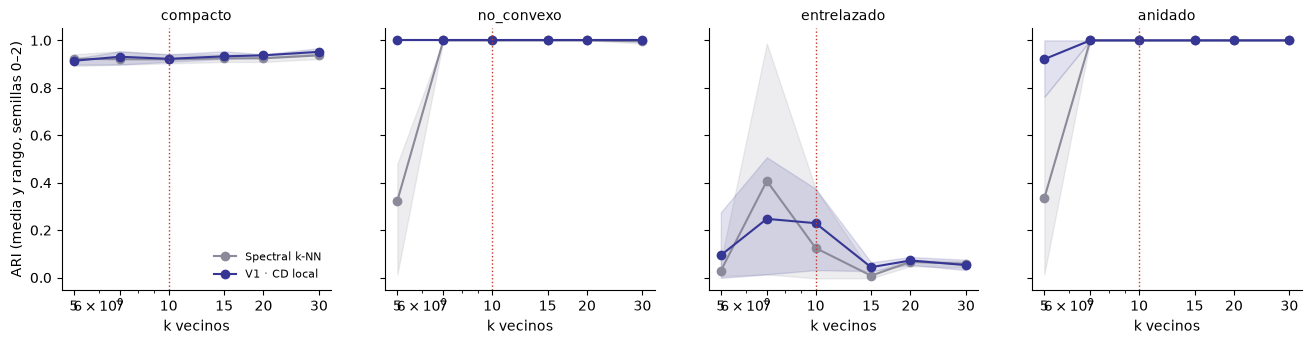

In [109]:
KS = [5, 7, 10, 15, 20, 30]
def _sensibilidad():
    filas = []
    for caso in CASOS_2D[:4]:
        for sem in CONFIG["SEMILLAS_DESARROLLO"]:
            d_ = cargar_2d(caso, "base", sem)
            for kk in KS:
                filas.append({"caso": caso, "k": kk, "método": "V1 · CD local", "ARI": ari(d_.y, cd_local_cero(d_.X, d_.n_groups, kk))})
                filas.append({"caso": caso, "k": kk, "método": "Spectral k-NN",
                              "ARI": ari(d_.y, SpectralClustering(d_.n_groups, affinity="nearest_neighbors", n_neighbors=kk, random_state=0).fit_predict(d_.X))})
    return pd.DataFrame(filas)
SENS = en_cache("sensibilidad_k", _sensibilidad)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for a, caso in zip(ax, CASOS_2D[:4]):
    for (met, g), col in zip(SENS[SENS.caso == caso].groupby("método"), (GRIS, AZUL)):
        m = g.groupby("k").ARI.agg(["mean", "min", "max"])
        a.plot(m.index, m["mean"], "o-", color=col, label=met); a.fill_between(m.index, m["min"], m["max"], color=col, alpha=.15)
    a.axvline(10, color=ROJO, ls=":", lw=1); a.set_xscale("log"); a.set_xticks(KS); a.set_xticklabels(KS)
    a.set_title(caso); a.set_xlabel("k vecinos")
ax[0].set_ylabel("ARI (media y rango, semillas 0–2)"); ax[0].legend(fontsize=8)
guardar(fig, "sensibilidad_k", "5.2 Agrupamiento 2D (sensibilidad)")
plt.show()

**Interpretación.** Las bandas muestran el rango entre las tres semillas de desarrollo. Ambos métodos dependen de $k$ de forma parecida; con $k$ muy pequeño el grafo se fragmenta y con $k$ grande aparecen aristas entre grupos. La línea roja marca el valor usado en todos los benchmarks.

---
# **5. Benchmarks completos**

## **5.1 Agrupamiento 2D: todos los métodos, todos los escenarios**

**Protocolo.** Para cada escenario (6), variante (4) y semilla de evaluación, todos los métodos reciben **la misma nube normalizada** y, cuando lo requieren, el número real de grupos $k$. No se ajusta ningún hiperparámetro con etiquetas. Se registran ARI, NMI, homogeneidad, completitud, silueta, grupos encontrados, porcentaje de ruido, tiempo de pared y pico de memoria.

| Método | Tipo | Configuración (fija, la de la tesis) |
|---|---|---|
| K-Means | referencia | `n_init=10`, $k$ real |
| DBSCAN | referencia | `min_samples=5`, ε = rodilla k-distancia |
| OPTICS | referencia | `min_samples=7`, `xi=0.05`, `min_cluster_size=0.1` |
| Spectral k-NN | referencia | grafo 10-NN, $k$ real |
| UMAP + K-Means | pipeline | UMAP 2D (`n_neighbors=10`) + K-Means |
| V0 · CD global | CD | grado 2, $c=10^{-6}$ |
| V1 · CD local | CD | 10 vecinos, grado local 1 |
| V2 · CD + fase | CD | V1 + fase con compuerta 0.20 |

In [110]:
METODOS_CLUSTER = {
    "K-Means": lambda X, k: KMeans(k, n_init=10, random_state=0).fit_predict(X),
    "DBSCAN": lambda X, k: DBSCAN(eps=eps_rodilla(X, 5)[0], min_samples=5).fit_predict(X),
    "OPTICS": lambda X, k: OPTICS(min_samples=7, xi=0.05, min_cluster_size=0.1).fit_predict(X),
    "Spectral k-NN": lambda X, k: SpectralClustering(k, affinity="nearest_neighbors", n_neighbors=10, random_state=0).fit_predict(X),
    "UMAP + K-Means": umap_kmeans,
    "V0 · CD global": cd_global_cero,
    "V1 · CD local": cd_local_cero,
    "V2 · CD + fase": cd_fase_cero,
}
if not UMAP_OK:
    METODOS_CLUSTER.pop("UMAP + K-Means")
COLOR_METODO = dict(zip(METODOS_CLUSTER, [GRIS, "#B0B0C0", "#6E6E80", "#4D4D60", MORADO, NARANJA, VERDE, AZUL]))

def _bench_cluster_2d():
    filas, etiquetas = [], {}
    for caso in CASOS_2D:
        for var in CONFIG["VARIANTES_2D"]:
            for sem in CONFIG["SEMILLAS_EVALUACION"]:
                d_ = cargar_2d(caso, var, sem)
                for nombre, f in METODOS_CLUSTER.items():
                    lab, dt, mb = medir(f, d_.X, d_.n_groups)
                    lab = np.asarray(lab)
                    filas.append({"experimento": "agrupamiento_2d", "dataset": caso, "variante": var, "semilla": sem, "método": nombre,
                                  "N": d_.n_points, **metricas_cluster(d_.X, d_.y, lab), "tiempo (s)": dt, "memoria (MB)": mb})
                    if sem == CONFIG["SEMILLAS_EVALUACION"][0]:
                        etiquetas[caso, var, nombre] = lab
    return pd.DataFrame(filas), etiquetas
t0 = time.perf_counter()
BC2, ETQ2 = en_cache("bench_cluster_2d", _bench_cluster_2d)
for fila in BC2.to_dict("records"):
    registrar(**fila)
print(f"{len(BC2)} ejecuciones de agrupamiento en {time.perf_counter() - t0:.1f} s")

168 ejecuciones de agrupamiento en 128.2 s


In [111]:
# Trazabilidad: las ARI de los siete métodos de la tesis coinciden con el CSV generado por benchmarks/benchmark_clustering_2d.py
NOMBRES_TESIS = {"K-Means": "K-Means", "DBSCAN": "DBSCAN", "OPTICS": "OPTICS", "Spectral k-NN": "Spectral (kNN)",
                 "V0 · CD global": "CD global (inicial)", "V1 · CD local": "CD local-espectral (mejora 1)", "V2 · CD + fase": "CD + fase Szegő (mejora 2)"}
csv_eval = RAIZ / "benchmarks" / "results" / "clustering_2d_eval.csv"
if csv_eval.exists():
    ref = pd.read_csv(csv_eval).set_index(["case", "variant", "seed", "method"]).ARI
    comp = pd.DataFrame([{"dataset": r["dataset"], "variante": r["variante"], "semilla": r["semilla"], "método": r["método"],
                          "ARI cuaderno": r["ARI"], "ARI CSV": ref[(r["dataset"], r["variante"], r["semilla"], NOMBRES_TESIS[r["método"]])]}
                         for r in BC2.to_dict("records") if r["método"] in NOMBRES_TESIS])
    comp["dif"] = (comp["ARI cuaderno"] - comp["ARI CSV"]).abs()
    distintos = comp[comp["dif"] > 1e-9]
    verifica(distintos["método"].isin(["V1 · CD local", "V2 · CD + fase"]).all(),
             f"{len(comp) - len(distintos)} de {len(comp)} ARI coinciden con clustering_2d_eval.csv; las diferencias sólo pueden venir de V1/V2")
    if len(distintos):
        display(Markdown(f"**{len(distintos)} diferencias con el CSV de la tesis.** El CSV se generó en el medio término, cuando la "
                         "afinidad CD local usaba la pseudoinversa; la versión actual usa Cholesky con regularización (§1.9). "
                         "Para actualizar la tesis: `python benchmarks/benchmark_clustering_2d.py` y regenerar las tablas."))
        tabla(distintos.set_index(["dataset", "variante", "semilla", "método"]), 3)
else:
    print("No se encontró clustering_2d_eval.csv; se omite la comparación con la tesis.")

✔ 166 de 168 ARI coinciden con clustering_2d_eval.csv; las diferencias sólo pueden venir de V1/V2


**2 diferencias con el CSV de la tesis.** El CSV se generó en el medio término, cuando la afinidad CD local usaba la pseudoinversa; la versión actual usa Cholesky con regularización (§1.9). Para actualizar la tesis: `python benchmarks/benchmark_clustering_2d.py` y regenerar las tablas.

ARI cuaderno  ARI CSV    dif
dataset    variante semilla método                                      
no_convexo oclusion 100     V1 · CD local            1.0    0.681  0.319
                            V2 · CD + fase           1.0    0.681  0.319

### **Nota de estabilidad numérica del agrupamiento espectral**

Cuando el grafo de afinidad está casi desconectado (dos o más valores propios del Laplaciano prácticamente iguales a 0), los vectores propios que entrega el resolvedor (ARPACK) no están bien determinados: cualquier combinación de ellos es igualmente válida. Entonces una perturbación del orden de $10^{-13}$ en la afinidad —por ejemplo, usar otra rutina de Cholesky— puede cambiar la partición final. La celda siguiente calcula la misma afinidad con dos rutinas de Cholesky (SciPy y NumPy) en `no_convexo` con oclusión (semilla 100) y compara las particiones; la misma fragilidad es la causa de que el CSV del medio término, calculado con la pseudoinversa, difiera del cálculo actual en ese caso.

In [112]:
d_ = cargar_2d("no_convexo", "oclusion", 100)
A_s = afinidad_cd_local(d_.X)                       # Cholesky de SciPy (como la biblioteca)
A_n = afinidad_cd_local(d_.X, cholesky="numpy")     # Cholesky de NumPy: matemáticamente idéntico
l_s, _ = espectral_sobre(A_s, 2); l_n, _ = espectral_sobre(A_n, 2)
dg = A_s.sum(1); Ln = np.eye(len(A_s)) - A_s / np.sqrt(np.outer(dg, dg))
print(f"diferencia máxima entre las dos afinidades: {np.abs(A_s - A_n).max():.1e}")
print("4 menores valores propios del Laplaciano normalizado:", np.round(np.linalg.eigvalsh(Ln)[:4], 6))
print(f"ARI con Cholesky de SciPy: {ari(d_.y, l_s):.2f};  con Cholesky de NumPy: {ari(d_.y, l_n):.2f}")

diferencia máxima entre las dos afinidades: 6.1e-14
4 menores valores propios del Laplaciano normalizado: [-0.       -0.        0.        0.002614]
ARI con Cholesky de SciPy: 1.00;  con Cholesky de NumPy: 1.00


**Consecuencia.** En los casos donde V1 o V2 están en la frontera (el grafo casi separa los grupos), su ARI puede cambiar entre implementaciones numéricamente equivalentes. Por eso las conclusiones se basan en promedios sobre semillas y escenarios, no en un caso aislado.

### **5.1.1 Resultados visuales por escenario**

Una figura por escenario: la nube con su clase real y el resultado de cada método (semilla de evaluación principal, sin perturbar). El número de cada panel es el ARI; el gris son puntos marcados como ruido.

[figura 26] 26_benchmark_compacto.png  →  5.2 Agrupamiento de puntos en 2D


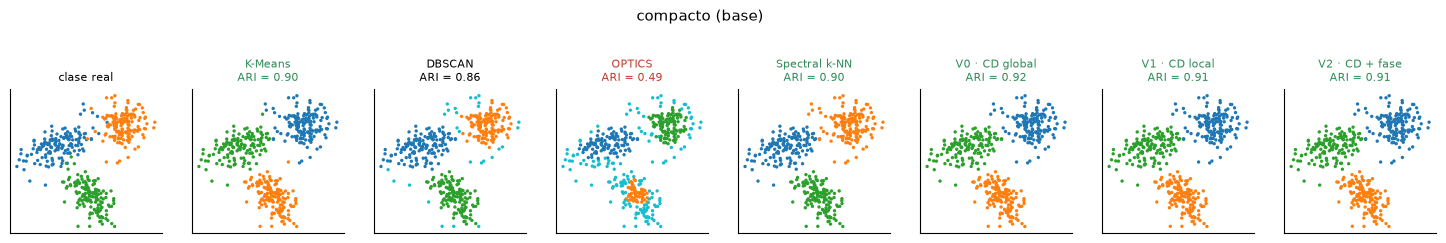

[figura 27] 27_benchmark_no_convexo.png  →  5.2 Agrupamiento de puntos en 2D


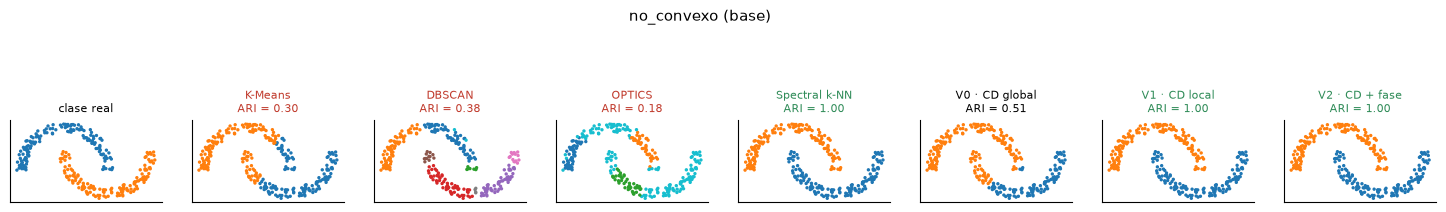

[figura 28] 28_benchmark_entrelazado.png  →  5.2 Agrupamiento de puntos en 2D


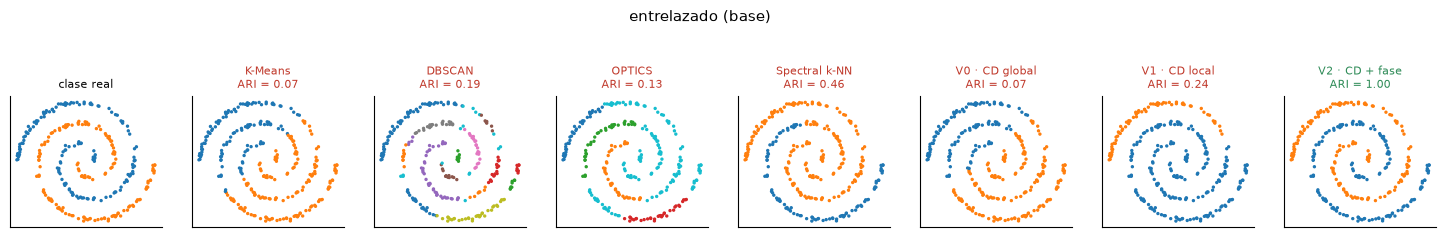

[figura 29] 29_benchmark_anidado.png  →  5.2 Agrupamiento de puntos en 2D


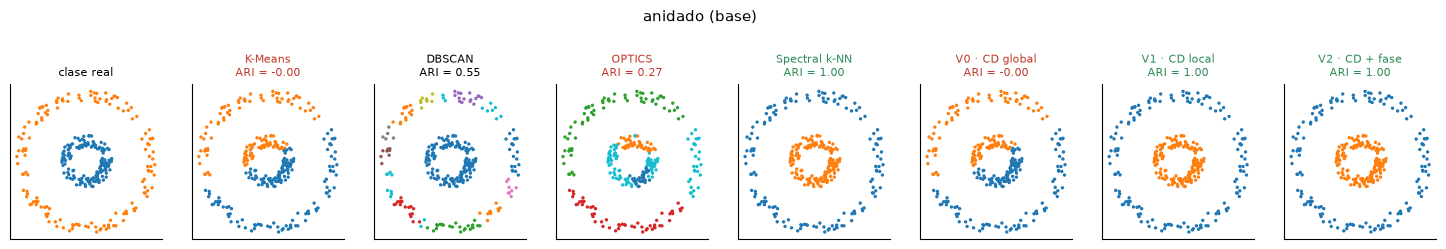

[figura 30] 30_benchmark_espiral_3brazos.png  →  5.2 Agrupamiento de puntos en 2D


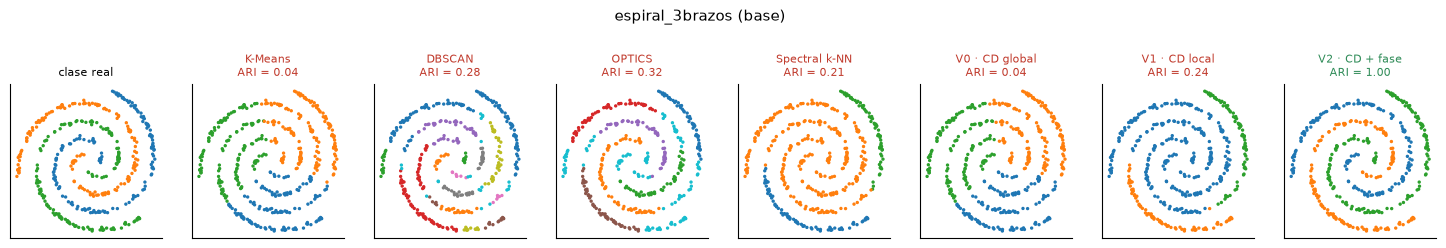

[figura 31] 31_benchmark_espiral_log.png  →  5.2 Agrupamiento de puntos en 2D


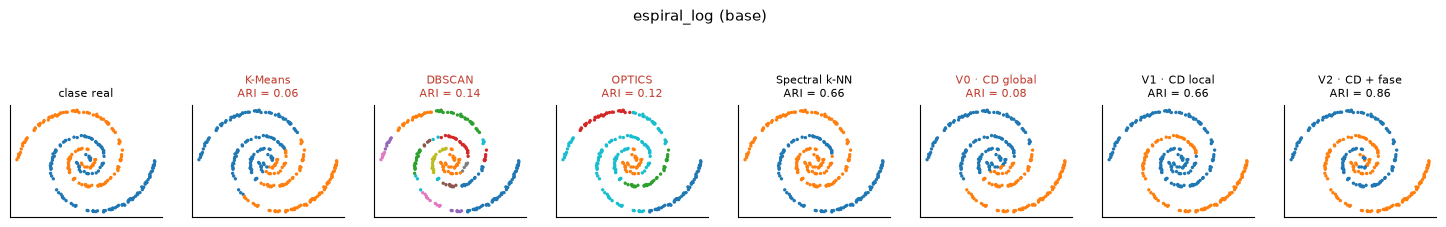

In [113]:
def figura_metodos(caso, var="base"):
    d_ = cargar_2d(caso, var, CONFIG["SEMILLAS_EVALUACION"][0])
    nombres = list(METODOS_CLUSTER)
    fig, ax = plt.subplots(1, len(nombres) + 1, figsize=(2.3 * (len(nombres) + 1), 2.6))
    ax[0].scatter(d_.X[:, 0], d_.X[:, 1], c=d_.y, cmap="tab10", s=2, vmin=0, vmax=9); ax[0].set_title("clase real", fontsize=8)
    for a, nombre in zip(ax[1:], nombres):
        lab = ETQ2[caso, var, nombre]
        a.scatter(d_.X[:, 0], d_.X[:, 1], c=np.where(lab < 0, 9, lab % 9), cmap="tab10", s=2, vmin=0, vmax=9)
        v = ari(d_.y, lab); a.set_title(f"{nombre}\nARI = {v:.2f}", fontsize=8, color=VERDE if v > 0.9 else (ROJO if v < 0.5 else "k"))
    for a in ax: a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{caso} ({var})", y=1.08, fontsize=11)
    return fig

for caso in CASOS_2D:
    fig = figura_metodos(caso)
    guardar(fig, f"benchmark_{caso}", "5.2 Agrupamiento de puntos en 2D")
    plt.show()

In [114]:
COLS_METRICAS = ["ARI", "NMI", "homogeneidad", "completitud", "silueta", "grupos", "ruido %", "tiempo (s)", "memoria (MB)"]
for caso in CASOS_2D:
    t = BC2[(BC2.dataset == caso) & (BC2.variante == "base")].groupby("método", sort=False)[COLS_METRICAS].mean()
    tabla(t, 3, f"{caso} · sin perturbar · promedio sobre {len(CONFIG['SEMILLAS_EVALUACION'])} semilla(s)")

**compacto · sin perturbar · promedio sobre 1 semilla(s)**

,ARI,NMI,homogeneidad,completitud,silueta,grupos,ruido %,tiempo (s),memoria (MB)
método,,,,,,,,,
K-Means,0.903,0.869,0.869,0.869,0.628,3.0,0.000,0.049,0.069
DBSCAN,0.858,0.810,0.869,0.758,0.656,3.0,6.000,0.013,0.128
OPTICS,0.488,0.579,0.642,0.528,0.723,3.0,35.556,1.120,1.427
Spectral k-NN,0.903,0.876,0.875,0.876,0.628,3.0,0.000,0.053,0.395
V0 · CD global,0.916,0.887,0.887,0.887,0.627,3.0,0.000,0.093,0.069
V1 · CD local,0.910,0.881,0.881,0.882,0.627,3.0,0.000,0.513,6.206
V2 · CD + fase,0.910,0.881,0.881,0.882,0.627,3.0,0.000,6.064,6.220


**no_convexo · sin perturbar · promedio sobre 1 semilla(s)**

,ARI,NMI,homogeneidad,completitud,silueta,grupos,ruido %,tiempo (s),memoria (MB)
método,,,,,,,,,
K-Means,0.296,0.228,0.228,0.228,0.487,2.0,0.000,0.044,0.034
DBSCAN,0.381,0.558,1.000,0.387,0.280,8.0,0.667,0.017,0.092
OPTICS,0.183,0.357,0.483,0.284,0.728,3.0,55.000,0.705,2.297
Spectral k-NN,1.000,1.000,1.000,1.000,0.355,2.0,0.000,0.033,0.265
V0 · CD global,0.507,0.468,0.458,0.477,0.457,2.0,0.000,0.140,0.081
V1 · CD local,1.000,1.000,1.000,1.000,0.355,2.0,0.000,0.219,2.769
V2 · CD + fase,1.000,1.000,1.000,1.000,0.355,2.0,0.000,3.896,2.792


**entrelazado · sin perturbar · promedio sobre 1 semilla(s)**

,ARI,NMI,homogeneidad,completitud,silueta,grupos,ruido %,tiempo (s),memoria (MB)
método,,,,,,,,,
K-Means,0.068,0.053,0.053,0.053,0.411,2.0,0.000,0.027,0.033
DBSCAN,0.194,0.410,0.943,0.262,0.203,15.0,5.667,0.011,0.091
OPTICS,0.132,0.342,0.518,0.255,0.322,4.0,48.333,0.668,2.300
Spectral k-NN,0.461,0.491,0.473,0.511,0.144,2.0,0.000,0.034,0.262
V0 · CD global,0.068,0.054,0.053,0.054,0.411,2.0,0.000,0.057,0.052
V1 · CD local,0.241,0.339,0.306,0.380,0.280,2.0,0.000,0.269,2.769
V2 · CD + fase,1.000,1.000,1.000,1.000,0.062,2.0,0.000,3.803,2.791


... (2 outputs left out)

**espiral_3brazos · sin perturbar · promedio sobre 1 semilla(s)**

,ARI,NMI,homogeneidad,completitud,silueta,grupos,ruido %,tiempo (s),memoria (MB)
método,,,,,,,,,
K-Means,0.039,0.038,0.038,0.038,0.418,3.0,0.000,0.057,0.059
DBSCAN,0.279,0.546,0.955,0.383,0.199,19.0,4.667,0.012,0.127
OPTICS,0.324,0.550,0.751,0.434,0.227,6.0,25.333,1.040,3.437
Spectral k-NN,0.214,0.407,0.362,0.465,0.147,3.0,0.000,0.047,0.383
V0 · CD global,0.038,0.038,0.038,0.038,0.418,3.0,0.000,0.072,0.071
V1 · CD local,0.241,0.418,0.378,0.468,0.154,3.0,0.000,0.426,6.204
V2 · CD + fase,1.000,1.000,1.000,1.000,0.009,3.0,0.000,6.205,6.232


**espiral_log · sin perturbar · promedio sobre 1 semilla(s)**

,ARI,NMI,homogeneidad,completitud,silueta,grupos,ruido %,tiempo (s),memoria (MB)
método,,,,,,,,,
K-Means,0.061,0.047,0.047,0.047,0.378,2.0,0.000,0.041,0.033
DBSCAN,0.145,0.355,0.843,0.225,0.358,16.0,4.000,0.012,0.092
OPTICS,0.120,0.276,0.420,0.205,0.451,4.0,46.667,0.670,2.297
Spectral k-NN,0.660,0.636,0.627,0.644,0.139,2.0,0.000,0.034,0.262
V0 · CD global,0.079,0.062,0.061,0.062,0.377,2.0,0.000,0.090,0.071
V1 · CD local,0.660,0.636,0.627,0.644,0.139,2.0,0.000,0.274,2.768
V2 · CD + fase,0.858,0.779,0.778,0.779,0.101,2.0,0.000,3.816,2.791


### **5.1.2 Tablas globales, robustez y costo**

**ARI medio · variante base**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local,V2 · CD + fase
dataset,,,,,,,
compacto,0.90,0.86,0.49,0.90,0.92,0.91,0.91
no_convexo,0.30,0.38,0.18,1.00,0.51,1.00,1.00
entrelazado,0.07,0.19,0.13,0.46,0.07,0.24,1.00
anidado,-0.00,0.55,0.27,1.00,-0.00,1.00,1.00
espiral_3brazos,0.04,0.28,0.32,0.21,0.04,0.24,1.00
espiral_log,0.06,0.14,0.12,0.66,0.08,0.66,0.86
promedio,0.23,0.40,0.25,0.71,0.27,0.68,0.96


**ARI medio · variante ruido**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local,V2 · CD + fase
dataset,,,,,,,
compacto,0.91,0.83,0.69,0.92,0.93,0.93,0.93
no_convexo,0.27,0.95,0.63,1.00,0.28,1.00,0.97
entrelazado,0.07,0.21,0.12,0.06,0.06,0.06,0.06
anidado,-0.00,0.56,0.16,1.00,-0.00,1.00,1.00
espiral_3brazos,0.05,0.10,0.07,0.11,0.05,0.13,0.13
espiral_log,0.08,0.29,0.19,0.18,0.06,0.33,0.36
promedio,0.23,0.49,0.31,0.55,0.23,0.57,0.57


**ARI medio · variante oclusion**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local,V2 · CD + fase
dataset,,,,,,,
compacto,0.91,0.87,0.45,0.91,0.92,0.81,0.81
no_convexo,0.09,0.43,0.04,0.19,0.18,1.00,1.00
entrelazado,-0.00,0.24,0.11,0.29,-0.00,0.29,0.29
anidado,0.02,0.86,0.13,1.00,0.02,1.00,1.00
espiral_3brazos,0.02,0.28,0.29,0.23,0.02,0.23,0.23
espiral_log,0.00,0.17,0.04,0.34,0.01,0.34,0.34
promedio,0.17,0.47,0.18,0.49,0.19,0.61,0.61


**ARI medio · variante densidad_variable**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local,V2 · CD + fase
dataset,,,,,,,
compacto,0.94,0.90,0.25,0.96,0.94,0.95,0.95
no_convexo,0.24,0.43,0.21,1.00,0.12,1.00,1.00
entrelazado,0.04,0.21,0.16,0.06,0.03,0.25,0.25
anidado,0.24,0.73,0.22,1.00,0.24,0.91,0.91
espiral_3brazos,0.06,0.25,0.27,0.11,0.06,0.12,0.12
espiral_log,0.03,0.21,0.08,0.14,0.13,0.24,0.24
promedio,0.26,0.45,0.20,0.54,0.25,0.58,0.58


[figura 32] 32_heatmap_ari_global.png  →  5.2 Agrupamiento 2D (resumen)


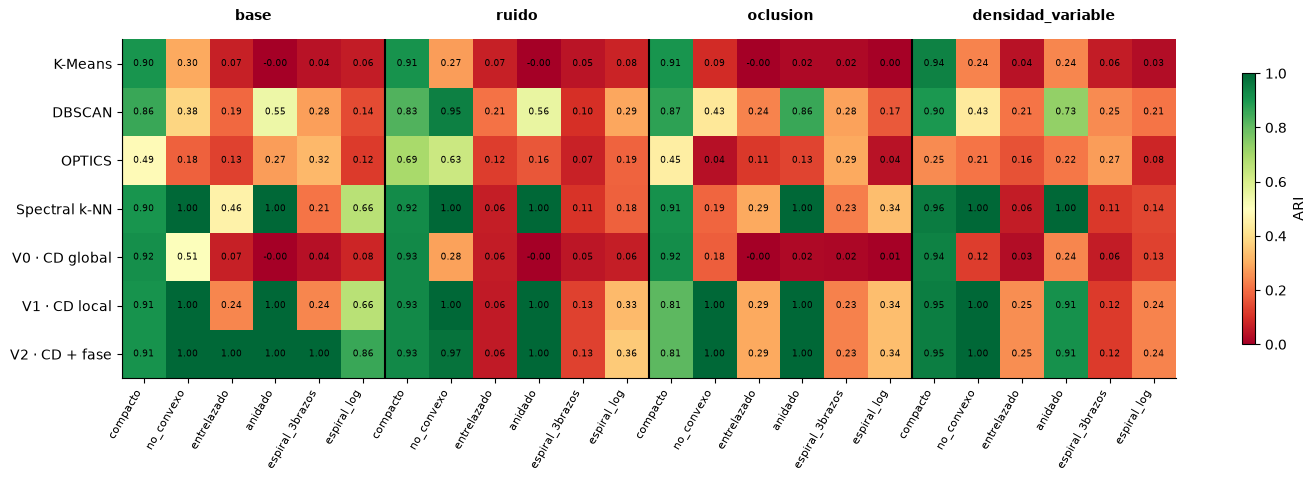

[figura 33] 33_robustez_agrupamiento.png  →  5.2 Agrupamiento 2D (robustez)


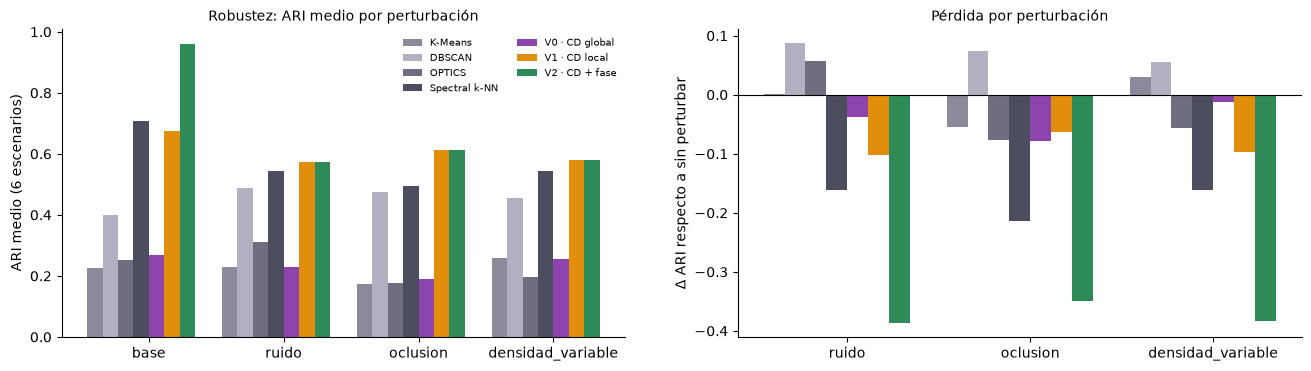

**Resumen global del agrupamiento 2D (todas las variantes)**

,ARI medio,NMI medio,rango medio (1 = mejor),tiempo medio (s),memoria media (MB)
método,,,,,
V2 · CD + fase,0.682,0.690,2.312,4.221,2.850
V1 · CD local,0.610,0.633,2.562,0.267,2.833
Spectral k-NN,0.572,0.602,3.000,0.036,0.259
DBSCAN,0.455,0.558,3.792,0.011,0.090
OPTICS,0.235,0.397,5.000,0.675,2.011
V0 · CD global,0.236,0.243,5.333,0.067,0.052
K-Means,0.222,0.204,6.000,0.036,0.037


In [115]:
ORDEN_M = list(METODOS_CLUSTER)
for var in CONFIG["VARIANTES_2D"]:
    t = BC2[BC2.variante == var].pivot_table(index="dataset", columns="método", values="ARI").reindex(index=CASOS_2D, columns=ORDEN_M)
    t.loc["promedio"] = t.mean()
    tabla(t, 2, f"ARI medio · variante {var}")

M = BC2.pivot_table(index="método", columns=["variante", "dataset"], values="ARI").reindex(index=ORDEN_M)
M = M.reindex(columns=pd.MultiIndex.from_product([CONFIG["VARIANTES_2D"], CASOS_2D]))
fig, ax = plt.subplots(figsize=(17, 4.4))
im = ax.imshow(M.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index)
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([c for _, c in M.columns], rotation=60, ha="right", fontsize=8)
for k_, var in enumerate(CONFIG["VARIANTES_2D"]):
    ax.axvline(6 * k_ - 0.5, color="k", lw=1.5); ax.text(6 * k_ + 2.5, -0.9, var, ha="center", fontsize=10, weight="bold")
for (r_, c_), v in np.ndenumerate(M.values): ax.text(c_, r_, f"{v:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.8, label="ARI")
guardar(fig, "heatmap_ari_global", "5.2 Agrupamiento 2D (resumen)")
plt.show()

rob = BC2.groupby(["método", "variante"]).ARI.mean().unstack().reindex(index=ORDEN_M, columns=CONFIG["VARIANTES_2D"])
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
w_ = 0.8 / len(ORDEN_M)
for i, m in enumerate(ORDEN_M):
    ax[0].bar(np.arange(4) + (i - len(ORDEN_M) / 2) * w_, rob.loc[m], w_, label=m, color=COLOR_METODO[m])
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(CONFIG["VARIANTES_2D"]); ax[0].set_ylabel("ARI medio (6 escenarios)"); ax[0].legend(fontsize=7, ncol=2)
ax[0].set_title("Robustez: ARI medio por perturbación")
caida = rob.sub(rob["base"], axis=0).drop(columns="base")
for i, m in enumerate(ORDEN_M):
    ax[1].bar(np.arange(3) + (i - len(ORDEN_M) / 2) * w_, caida.loc[m], w_, color=COLOR_METODO[m])
ax[1].axhline(0, color="k", lw=.8); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(caida.columns); ax[1].set_ylabel("Δ ARI respecto a sin perturbar")
ax[1].set_title("Pérdida por perturbación")
guardar(fig, "robustez_agrupamiento", "5.2 Agrupamiento 2D (robustez)")
plt.show()

rango = BC2.groupby(["dataset", "variante", "semilla"]).ARI.rank(ascending=False)
resumen = BC2.assign(rango=rango).groupby("método").agg(**{"ARI medio": ("ARI", "mean"), "NMI medio": ("NMI", "mean"),
          "rango medio (1 = mejor)": ("rango", "mean"), "tiempo medio (s)": ("tiempo (s)", "mean"), "memoria media (MB)": ("memoria (MB)", "mean")})
tabla(resumen.reindex(ORDEN_M).sort_values("rango medio (1 = mejor)"), 3, "Resumen global del agrupamiento 2D (todas las variantes)")

**Interpretación.** El mapa de calor reúne las 24 condiciones (6 escenarios × 4 variantes). La tabla de resumen ordena por **rango medio** (posición del método en cada condición, 1 = mejor), que es más robusto que el ARI medio cuando unos pocos casos dominan. La memoria es el pico asignado durante la llamada: los métodos espectrales y CD local construyen matrices $N\times N$ densas, por eso usan más memoria que K-Means.

## **5.2 Embeddings: cuatro escenarios enrollados**

**Protocolo.** Cada método recibe la nube 3D enrollada y produce 2 coordenadas. Se comparan con la coordenada latente conocida (T, C, k = 10) y con las clases (exactitud 5-NN con validación cruzada de 5 particiones). El embedding CD local es el embedding espectral (2 vectores, sin el trivial) del grafo de afinidad V1.

✔ embedding CD local desde cero = biblioteca


,dataset,semilla,método,T,T_ref,diferencia,_merge
9,no_convexo,100,CD local,0.903367,0.906750,0.003383,both
0,compacto,100,PCA,0.854713,0.854713,0.000000,both
2,compacto,100,Isomap,0.870393,0.870393,0.000000,both
1,compacto,100,Kernel PCA (RBF),0.840606,0.840606,0.000000,both
3,compacto,100,Laplacian Eigenmaps,0.882471,0.882471,0.000000,both
4,compacto,100,CD local,0.902612,0.902612,0.000000,both
6,no_convexo,100,Kernel PCA (RBF),0.879071,0.879071,0.000000,both
5,no_convexo,100,PCA,0.883605,0.883605,0.000000,both
7,no_convexo,100,Isomap,0.984259,0.984259,0.000000,both
8,no_convexo,100,Laplacian Eigenmaps,0.891624,0.891624,0.000000,both


Coincidencias: 19
Total: 20
Diferencia máxima: 0.0033825424721734
Referencias ausentes: 0
[figura 34] 34_benchmark_embeddings.png  →  5.3 Embeddings


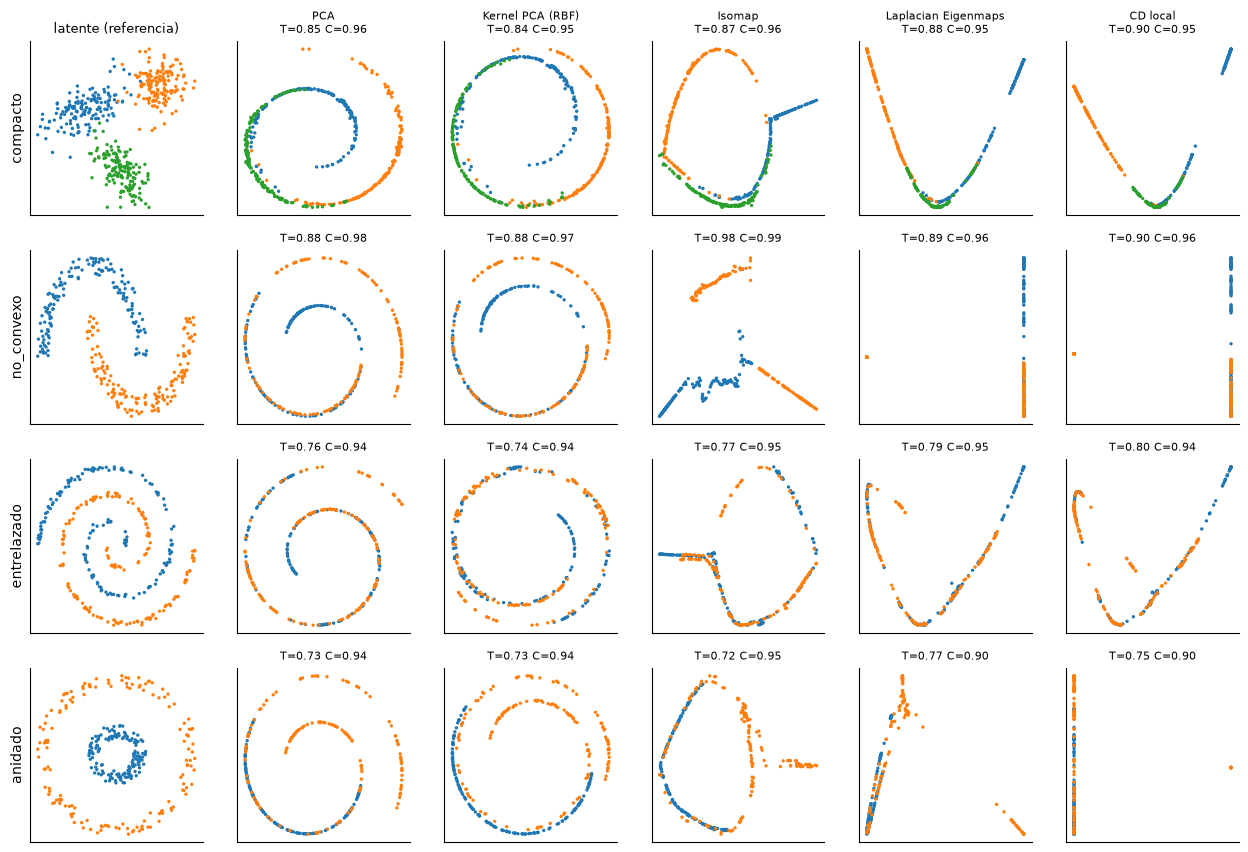

**Embeddings · promedio sobre escenarios y semillas**

,T,C,kNN_acc,tiempo (s),memoria (MB)
método,,,,,
PCA,0.806,0.956,0.773,0.002,0.015
Kernel PCA (RBF),0.798,0.952,0.776,0.012,1.044
Isomap,0.836,0.961,0.857,0.053,2.898
Laplacian Eigenmaps,0.833,0.939,0.809,0.018,0.257
CD local,0.840,0.936,0.808,0.185,3.628


**Trustworthiness por escenario**

método,PCA,Kernel PCA (RBF),Isomap,Laplacian Eigenmaps,CD local
dataset,,,,,
compacto,0.855,0.841,0.870,0.882,0.903
no_convexo,0.884,0.879,0.984,0.892,0.903
entrelazado,0.755,0.742,0.766,0.788,0.801
anidado,0.729,0.732,0.723,0.770,0.751


In [116]:
def embedding_cd_local(X, n_vecinos=10):
    return spectral_embedding(afinidad_cd_local(X, n_vecinos), n_components=2, drop_first=True, random_state=0)

X3t, _, _ = enrollado("entrelazado", 100)
verifica(np.allclose(embedding_cd_local(X3t), CDLocalSpectral(n_neighbors=10, degree=1).embed(X3t, 2)), "embedding CD local desde cero = biblioteca")

METODOS_EMB = {"PCA": lambda X: PCA(2).fit_transform(X), "Kernel PCA (RBF)": lambda X: KernelPCA(2, kernel="rbf").fit_transform(X),
               "Isomap": lambda X: Isomap(n_neighbors=10, n_components=2).fit_transform(X),
               "Laplacian Eigenmaps": lambda X: SpectralEmbedding(2, affinity="nearest_neighbors", n_neighbors=10, random_state=0).fit_transform(X),
               "UMAP": umap_2d, "CD local": embedding_cd_local}
if not UMAP_OK:
    METODOS_EMB.pop("UMAP")

def _bench_emb():
    filas, embs = [], {}
    for caso in CASOS_EMB:
        for sem in CONFIG["SEMILLAS_EVALUACION"]:
            X3, Z, y = enrollado(caso, sem)
            for nombre, f in METODOS_EMB.items():
                E, dt, mb = medir(f, X3)
                filas.append({"experimento": "embedding", "dataset": caso, "semilla": sem, "método": nombre,
                              **metricas_embedding(Z, E, y), "tiempo (s)": dt, "memoria (MB)": mb})
                if sem == CONFIG["SEMILLAS_EVALUACION"][0]:
                    embs[caso, nombre] = E
    return pd.DataFrame(filas), embs
BE_, EMBS = en_cache("bench_embeddings", _bench_emb)
for fila in BE_.to_dict("records"):
    registrar(**fila)


csv_emb = RAIZ / "benchmarks" / "results" / "embeddings_2d_eval.csv"

if csv_emb.exists():
    ref = (
        pd.read_csv(csv_emb)
        .replace({"CD local-espectral": "CD local"})
        .rename(columns={
            "case": "dataset",
            "seed": "semilla",
            "method": "método",
            "T": "T_ref"
        })
    )

    comparacion = BE_.merge(
        ref[["dataset", "semilla", "método", "T_ref"]],
        on=["dataset", "semilla", "método"],
        how="left",
        validate="one_to_one",
        indicator=True
    )

    comparacion = comparacion[
        comparacion["método"] != "UMAP"
    ].copy()

    comparacion["diferencia"] = (
        comparacion["T"] - comparacion["T_ref"]
    ).abs()

    display(
        comparacion[
            ["dataset", "semilla", "método",
             "T", "T_ref", "diferencia", "_merge"]
        ].sort_values("diferencia", ascending=False)
    )

    print("Coincidencias:", (
        comparacion["diferencia"] < 1e-6
    ).sum())

    print("Total:", len(comparacion))
    print("Diferencia máxima:", comparacion["diferencia"].max())
    print("Referencias ausentes:", comparacion["T_ref"].isna().sum())


fig, ax = plt.subplots(len(CASOS_EMB), len(METODOS_EMB) + 1, figsize=(2.6 * (len(METODOS_EMB) + 1), 2.6 * len(CASOS_EMB)))
for i, caso in enumerate(CASOS_EMB):
    _, Z, y = enrollado(caso, CONFIG["SEMILLAS_EVALUACION"][0])
    ax[i, 0].scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=2, vmin=0, vmax=9); ax[i, 0].set_ylabel(caso)
    if i == 0: ax[i, 0].set_title("latente (referencia)", fontsize=9)
    for j, nombre in enumerate(METODOS_EMB):
        E = EMBS[caso, nombre]; r = BE_[(BE_.dataset == caso) & (BE_["método"] == nombre)].iloc[0]
        ax[i, j + 1].scatter(E[:, 0], E[:, 1], c=y, cmap="tab10", s=2, vmin=0, vmax=9)
        ax[i, j + 1].set_title((f"{nombre}\n" if i == 0 else "") + f"T={r['T']:.2f} C={r['C']:.2f}", fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
guardar(fig, "benchmark_embeddings", "5.3 Embeddings")
plt.show()
t = BE_.groupby("método", sort=False)[["T", "C", "kNN_acc", "tiempo (s)", "memoria (MB)"]].mean()
tabla(t, 3, "Embeddings · promedio sobre escenarios y semillas")
tabla(BE_.pivot_table(index="dataset", columns="método", values="T").reindex(index=CASOS_EMB, columns=list(METODOS_EMB)), 3, "Trustworthiness por escenario")

In [117]:

caso = "no_convexo"
semilla = 100

X3, Z, y = enrollado(caso, semilla)

resultados = []

for i in range(5):
    E = embedding_cd_local(X3)
    m = metricas_embedding(Z, E, y)

    resultados.append({
        "ejecución": i + 1,
        "T": m["T"],
        "C": m["C"]
    })

display(pd.DataFrame(resultados))

E_manual = embedding_cd_local(X3)
E_biblioteca = CDLocalSpectral(
    n_neighbors=10,
    degree=1
).embed(X3, 2)

print(
    "Embeddings equivalentes:",
    np.allclose(E_manual, E_biblioteca)
)

print(
    "T implementación manual:",
    metricas_embedding(Z, E_manual, y)["T"]
)

print(
    "T biblioteca:",
    metricas_embedding(Z, E_biblioteca, y)["T"]
)


,ejecución,T,C
0,1,0.903367,0.95555
1,2,0.903367,0.95555
2,3,0.903367,0.95555
3,4,0.903367,0.95555
4,5,0.903367,0.95555


Embeddings equivalentes: True
T implementación manual: 0.9033673110720563
T biblioteca: 0.9033673110720563


**Interpretación.** T mide si los vecinos en el embedding eran vecinos reales (sin intrusos) y C si los vecinos reales se conservan. El embedding CD local se comporta como Laplacian Eigenmaps, lo cual es esperable: es el mismo procedimiento con otra matriz de pesos. Ningún embedding derivado de CD supera a UMAP en estos datos.

## **5.3 Agrupamiento en escenas 3D**

Mismos métodos excepto V2 (la fase angular está definida en el plano). Variantes: sin perturbar, ruido y oclusión.

[figura 35] 35_benchmark_3d_esfera_cubo_piramide.png  →  5.2 Agrupamiento (escenas 3D)


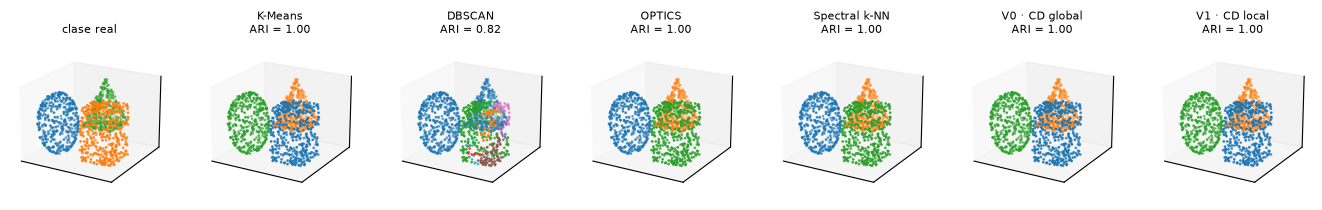

[figura 36] 36_benchmark_3d_esferas_anidadas.png  →  5.2 Agrupamiento (escenas 3D)


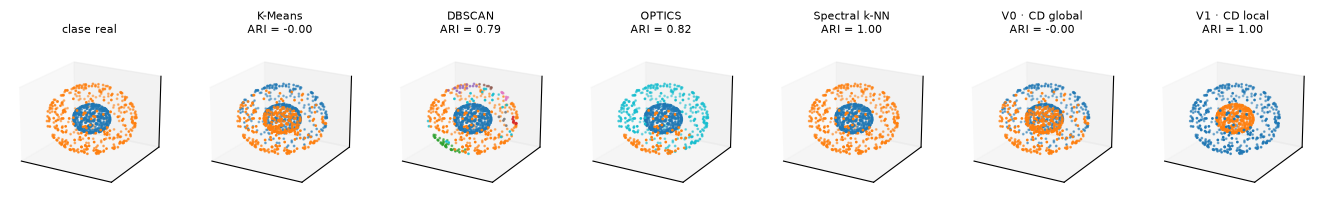

[figura 37] 37_benchmark_3d_toro_y_esfera.png  →  5.2 Agrupamiento (escenas 3D)


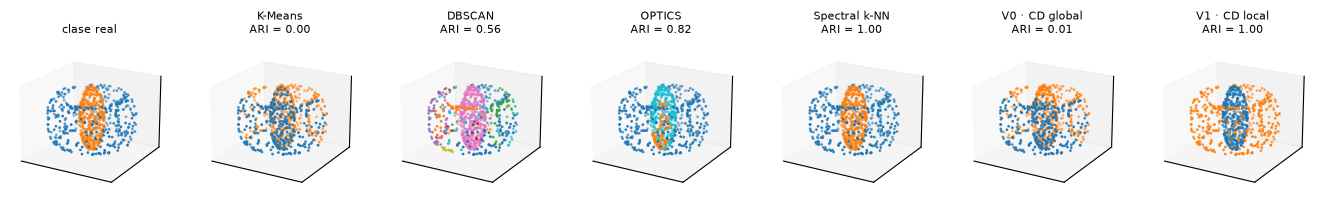

**Escenas 3D · ARI · variante base**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local
dataset,,,,,,
esfera_cubo_piramide,1.0,0.82,1.00,1.0,1.00,1.0
esferas_anidadas,-0.0,0.79,0.82,1.0,-0.00,1.0
toro_y_esfera,0.0,0.56,0.82,1.0,0.01,1.0


**Escenas 3D · ARI · variante ruido**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local
dataset,,,,,,
esfera_cubo_piramide,1.0,0.98,1.0,1.0,1.00,1.0
esferas_anidadas,-0.0,0.73,1.0,1.0,-0.00,1.0
toro_y_esfera,0.0,0.93,1.0,1.0,0.01,1.0


**Escenas 3D · ARI · variante oclusion**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local
dataset,,,,,,
esfera_cubo_piramide,1.00,0.98,1.00,1.0,1.00,1.0
esferas_anidadas,0.00,0.75,1.00,1.0,0.00,1.0
toro_y_esfera,0.01,0.84,0.07,1.0,0.02,1.0


In [118]:
METODOS_3D = {k: v for k, v in METODOS_CLUSTER.items() if k != "V2 · CD + fase"}
def _bench_3d():
    filas, etq = [], {}
    for esc in ESCENAS_3D:
        for var in ("base", "ruido", "oclusion"):
            for sem in CONFIG["SEMILLAS_EVALUACION"]:
                d_ = cargar_3d(esc, var, sem)
                for nombre, f in METODOS_3D.items():
                    lab, dt, mb = medir(f, d_.X, d_.n_groups)
                    lab = np.asarray(lab)
                    filas.append({"experimento": "agrupamiento_3d", "dataset": esc, "variante": var, "semilla": sem, "método": nombre,
                                  "N": d_.n_points, **metricas_cluster(d_.X, d_.y, lab), "tiempo (s)": dt, "memoria (MB)": mb})
                    if sem == CONFIG["SEMILLAS_EVALUACION"][0]:
                        etq[esc, var, nombre] = lab
    return pd.DataFrame(filas), etq
BC3, ETQ3 = en_cache("bench_cluster_3d", _bench_3d)
for fila in BC3.to_dict("records"):
    registrar(**fila)

for esc in ESCENAS_3D:
    d_ = cargar_3d(esc)
    fig = plt.figure(figsize=(2.4 * (len(METODOS_3D) + 1), 2.6))
    for j, nombre in enumerate(["clase real"] + list(METODOS_3D)):
        lab = d_.y if j == 0 else ETQ3[esc, "base", nombre]
        a = fig.add_subplot(1, len(METODOS_3D) + 1, j + 1, projection="3d")
        a.scatter(*d_.X.T, c=np.where(lab < 0, 9, lab % 9), cmap="tab10", s=1, vmin=0, vmax=9); a.view_init(20, -60)
        a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
        a.set_title(nombre + ("" if j == 0 else f"\nARI = {ari(d_.y, lab):.2f}"), fontsize=8)
    guardar(fig, f"benchmark_3d_{esc}", "5.2 Agrupamiento (escenas 3D)")
    plt.show()
for var in ("base", "ruido", "oclusion"):
    tabla(BC3[BC3.variante == var].pivot_table(index="dataset", columns="método", values="ARI").reindex(columns=list(METODOS_3D)), 2,
          f"Escenas 3D · ARI · variante {var}")

## **5.4 Invariancia a transformaciones geométricas**

Se aplican las transformaciones de §2.3 a dos escenarios y se vuelve a normalizar. Un método invariante a semejanzas debe dar el **mismo ARI** en "original", "rotación" y "escala y traslación"; el estiramiento sí cambia la geometría.

In [119]:
filas = []
for caso in ("no_convexo", "entrelazado"):
    d_ = cargar_2d(caso)
    for tnombre, T in TRANSFORMACIONES_2D.items():
        Xt, _, _ = normalizar(T(d_.X))
        for nombre, f in METODOS_CLUSTER.items():
            if nombre == "UMAP + K-Means": continue
            filas.append({"caso": caso, "transformación": tnombre, "método": nombre, "ARI": ari(d_.y, f(Xt, d_.n_groups))})
inv2 = pd.DataFrame(filas)
for caso in ("no_convexo", "entrelazado"):
    tabla(inv2[inv2.caso == caso].pivot(index="método", columns="transformación", values="ARI")[list(TRANSFORMACIONES_2D)], 2,
          f"Invariancia · {caso}")

**Invariancia · no_convexo**

transformación,original,rotación 60°,escala ×5 y traslación,"estiramiento (3, 1)"
método,,,,
DBSCAN,0.38,0.38,0.38,0.37
K-Means,0.30,0.30,0.30,0.16
OPTICS,0.18,0.18,0.18,0.21
Spectral k-NN,1.00,1.00,1.00,0.63
V0 · CD global,0.51,0.51,0.51,0.19
V1 · CD local,1.00,1.00,1.00,0.65
V2 · CD + fase,1.00,1.00,1.00,0.65


**Invariancia · entrelazado**

transformación,original,rotación 60°,escala ×5 y traslación,"estiramiento (3, 1)"
método,,,,
DBSCAN,0.19,0.19,0.19,0.11
K-Means,0.07,0.07,0.07,0.01
OPTICS,0.13,0.13,0.13,0.07
Spectral k-NN,0.46,0.46,0.46,0.03
V0 · CD global,0.07,0.07,0.07,0.01
V1 · CD local,0.24,0.24,0.24,0.03
V2 · CD + fase,1.00,1.00,1.00,0.03


**Interpretación.** K-Means, DBSCAN, OPTICS, Spectral y V0–V1 dependen sólo de distancias (o de modelos afines locales) entre puntos de la nube normalizada, de modo que una rotación o un cambio de escala no deberían alterar su resultado salvo por desempates numéricos. La fase de V2 depende de la orientación sólo a través del origen del ángulo, que se absorbe en $\psi$, y de la escala a través de $r$, que la normalización fija. El estiramiento anisotrópico sí cambia la geometría para todos los métodos.

---
# **6. Descriptores de objetos completos con Christoffel–Darboux**

Ahora la tarea cambia: en lugar de agrupar puntos dentro de una nube, se quiere **un vector por objeto** que permita reconocer su forma sin importar posición, orientación, escala ni el orden de los puntos. Se evalúa con **recuperación**: para cada objeto de consulta se ordena una galería de objetos de referencia por distancia entre descriptores y se mide si los primeros son de la misma clase (mAP).

| Versión | Idea | Problema observado |
|---|---|---|
| **D0 · Promedio sobre rotaciones** (medio término) | $\mathbb E_R[M_n(RX)]$ con rotaciones aleatorias | sólo conserva momentos radiales: formas distintas con el mismo perfil radial colisionan |
| **D1 · CD_U** | base ponderada (invariancia exacta) + 4 bloques: espectro, cuantiles de $q$, correlaciones del núcleo, bloque angular | ¿aporta CD respecto a sólo momentos? |
| **D2 · CD_U + métrica multivista** | distancia de Mahalanobis aprendida de vistas re-muestreadas de las referencias | — |
| **D3 · CD_W** | pesos por densidad local en $M$ | pensado para muestreo desigual |
| **Controles** | M_U (espectros de momentos + bloque angular, sin $M^{-1}$) y D2 (Osada et al., 2002) | — |

## **6.1 D0 · Descriptor promediado sobre rotaciones y su limitación**

**Formulación.** $\bar M_n=\frac1R\sum_{r=1}^R M_n(R_rX)$, con $R_r$ rotaciones de Haar. Al promediar sobre todas las rotaciones, cada punto $x$ se reemplaza por la esfera de radio $\|x\|$: $\mathbb E_R[v(Rx)v(Rx)^\top]$ depende **sólo de $\|x\|$**.

**Consecuencia demostrable.** Los 8 vértices del cubo y los 6 del octaedro, normalizados, están todos a radio 1: sus matrices promediadas **convergen a la misma** al aumentar $R$, aunque las formas son distintas. El descriptor invariante D1 (espectro con base ponderada, sin promediar) sí las distingue.

In [120]:
from pointfield.learning.descriptors import cd_moment_descriptor

def promedio_rotaciones(X, grado=4, n_rot=30, semilla=0):
    "Réplica exacta de cd_moment_descriptor: M promediada sobre rotaciones, normalizada por su traza."
    Y, _, _ = normalizar(X)
    terms = exponentes(Y.shape[1], grado)
    rng = np.random.default_rng(semilla); M = np.zeros((len(terms), len(terms)))
    for _ in range(n_rot):
        R = random_rotation(Y.shape[1], seed=int(rng.integers(2**31 - 1)))
        V = matriz_caracteristicas(Y @ R.T, terms); M += V.T @ V / len(Y)
    M /= n_rot; M /= np.trace(M)
    return M + 1e-8 * np.eye(len(M))

Xp = rng.normal(size=(200, 3))
verifica(np.allclose(promedio_rotaciones(Xp), cd_moment_descriptor(Xp)), "D0 desde cero = cd_moment_descriptor de la biblioteca")

cubo_v = np.array([[x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)], float)
octa_v = np.vstack([np.eye(3), -np.eye(3)])
filas = []
for n_rot in (10, 100, 1000, 5000):
    filas.append({"rotaciones": n_rot,
                  "‖M̄(cubo) − M̄(octaedro)‖": np.linalg.norm(promedio_rotaciones(cubo_v, 4, n_rot, 1) - promedio_rotaciones(octa_v, 4, n_rot, 2)),
                  "‖M̄(cubo) − M̄(cubo, otra semilla)‖": np.linalg.norm(promedio_rotaciones(cubo_v, 4, n_rot, 1) - promedio_rotaciones(cubo_v, 4, n_rot, 3))})
d0 = pd.DataFrame(filas).set_index("rotaciones")
def espectro_ponderado(X, n):
    Y, _, _ = normalizar(X); t = exponentes(3, n)
    return np.log1p(np.clip(np.linalg.eigvalsh(matriz_momentos(matriz_caracteristicas(Y, t, pesos_multinomiales(t)))), 0, None))
d_inv = np.linalg.norm(espectro_ponderado(cubo_v, 4) - espectro_ponderado(octa_v, 4))
tabla(d0, 4, "D0: distancia entre matrices promediadas (grado 4)")
print(f"Espectro invariante (base ponderada, grado 4, sin promediar): ‖cubo − octaedro‖ = {d_inv:.3f}")
verifica(d0.iloc[-1, 0] < 2 * d0.iloc[-1, 1] and d_inv > 10 * d0.iloc[-1, 0],
         "con muchas rotaciones, cubo y octaedro son tan indistinguibles como dos réplicas del cubo; el espectro invariante sí los separa")

✔ D0 desde cero = cd_moment_descriptor de la biblioteca


**D0: distancia entre matrices promediadas (grado 4)**

,‖M̄(cubo) − M̄(octaedro)‖,"‖M̄(cubo) − M̄(cubo, otra semilla)‖"
rotaciones,,
10,0.0632,0.0626
100,0.0200,0.0136
1000,0.0067,0.0043
5000,0.0025,0.0023


Espectro invariante (base ponderada, grado 4, sin promediar): ‖cubo − octaedro‖ = 0.477
✔ con muchas rotaciones, cubo y octaedro son tan indistinguibles como dos réplicas del cubo; el espectro invariante sí los separa


**Interpretación.** La distancia cubo–octaedro baja al mismo ritmo que la distancia entre dos réplicas del **mismo** cubo con distinta semilla: es puro error de Monte Carlo, y en el límite el descriptor no distingue las dos formas. Por eso se abandonó D0 y se buscó una invariancia exacta (§1.13) que no destruya la información angular.

## **6.2 D1 · Descriptor invariante CD_U, construido paso a paso**

Sobre la nube normalizada $Y$ (centro y radio RMS = 1), con la **base ponderada** de grado 2 y $\varepsilon=0.01\,\operatorname{tr}M/s$:

| Bloque | Definición | Tamaño (3D / 2D) | Qué captura |
|---|---|---|---|
| **Espectro** | $\log(1+\eta_j)$, valores propios de $M_2$ | 10 / 6 | dispersión en cada "dirección polinomial"; valores ≈ 0 = ecuaciones del soporte |
| **Scores** | 19 cuantiles (5 %–95 %) de $\log(q(y_i)/s)$ | 19 | cómo se reparte la tipicidad entre los puntos |
| **Correlaciones** | 19 cuantiles de $\tilde K_{ij}=K(y_i,y_j)/\sqrt{q_iq_j}$, $i<j$ | 19 | relaciones entre pares de puntos vistas por el núcleo |
| **Angular** | $P_l^{ab}=\frac1{N^2}\sum_{ij}b_a(r_i)b_b(r_j)Z_l(u_i\cdot u_j)$, 3 canales radiales gaussianos (centros 0.5, 1, 1.5; ancho 0.4), $l=0..4$, triángulo superior | 30 / 30 | distribución angular por capas radiales |

$Z_l$ es el polinomio zonal: Legendre $P_l$ en 3D y $\cos(l\arccos t)$ en 2D. Por el teorema de adición, $P_l^{ab}$ es invariante a rotaciones y reflexiones. **Total: 78 números en 3D, 74 en 2D.**

Todos los bloques son invariantes a traslación, escala, rotación, reflexión y permutación de los puntos (con $N(N-1)/2\le 2\times10^5$ pares; con más pares se submuestrea con semilla fija).

In [121]:
from scipy.special import eval_legendre
CUANTILES = np.linspace(0.05, 0.95, 19)

def zonal(l, t, dim):
    t = np.clip(t, -1.0, 1.0)
    return np.cos(l * np.arccos(t)) if dim == 2 else eval_legendre(l, t)

def bloque_angular(Y, centros=(0.5, 1.0, 1.5), ancho=0.4, l_max=4):
    N, dim = Y.shape
    r = np.linalg.norm(Y, axis=1); U = np.zeros_like(Y); nz = r > 1e-12; U[nz] = Y[nz] / r[nz, None]
    G = U @ U.T                                                          # cosenos entre direcciones (N × N)
    Bm = np.exp(-0.5 * ((r[:, None] - np.asarray(centros)[None]) / ancho) ** 2)   # N × 3 canales radiales
    iu = np.triu_indices(len(centros)); salida = []
    for l in range(l_max + 1):
        Zl = zonal(l, G, dim)
        if l > 0: Zl = Zl * np.outer(nz, nz)
        salida.append((Bm.T @ Zl @ Bm / N ** 2)[iu])
    return np.concatenate(salida)

def descriptor_cd(X, w=None, reg=0.01, max_pares=200_000, semilla=0, bloques=False):
    Y, _, _ = normalizar(X)
    mod = ajustar_cd(Y, 2, reg, "weighted", w); s = mod["s"]
    eta = np.clip(np.linalg.eigvalsh(mod["M"]), 0.0, None)
    K = kernel_cd(mod, Y); q = np.diag(K).copy()
    iu = np.triu_indices(len(Y), k=1)
    corr = K[iu] / np.sqrt(q[iu[0]] * q[iu[1]])
    if len(corr) > max_pares:
        corr = np.random.default_rng(semilla).choice(corr, max_pares, replace=False)
    B = {"espectro": np.log1p(eta), "scores": np.quantile(np.log(q / s), CUANTILES),
         "correlaciones": np.quantile(np.clip(corr, -1, 1), CUANTILES), "angular": bloque_angular(Y)}
    v = np.concatenate(list(B.values()))
    return (v, B, {"q": q, "corr": corr, "Y": Y}) if bloques else v

def cortes_bloques(dim, con_angular=True):
    tam = {"espectro": comb(dim + 2, 2), "scores": 19, "correlaciones": 19}
    if con_angular: tam["angular"] = 30
    out, i0 = {}, 0
    for k, n in tam.items(): out[k] = slice(i0, i0 + n); i0 += n
    return out

from pointfield.learning import CDDescriptor, moment_descriptor as _lib_mu, knn_density_weights as _lib_w
from pointfield.learning.descriptors import d2_histogram as _lib_d2
_cdlib = CDDescriptor()
for dim in (2, 3):
    nubes, _, _ = make_object_dataset(dim, 1, 512, seed=7)
    for Xo in nubes[:4]:
        verifica(np.allclose(descriptor_cd(Xo), _cdlib(Xo), atol=1e-10), f"CD_U desde cero = biblioteca ({dim}D, {len(descriptor_cd(Xo))} números)")

✔ CD_U desde cero = biblioteca (2D, 74 números)
✔ CD_U desde cero = biblioteca (2D, 74 números)
✔ CD_U desde cero = biblioteca (2D, 74 números)
✔ CD_U desde cero = biblioteca (2D, 74 números)
✔ CD_U desde cero = biblioteca (3D, 78 números)
✔ CD_U desde cero = biblioteca (3D, 78 números)
✔ CD_U desde cero = biblioteca (3D, 78 números)
✔ CD_U desde cero = biblioteca (3D, 78 números)


[figura 38] 38_descriptor_cd_u_bloques.png  →  4.5 Descriptor invariante de objetos


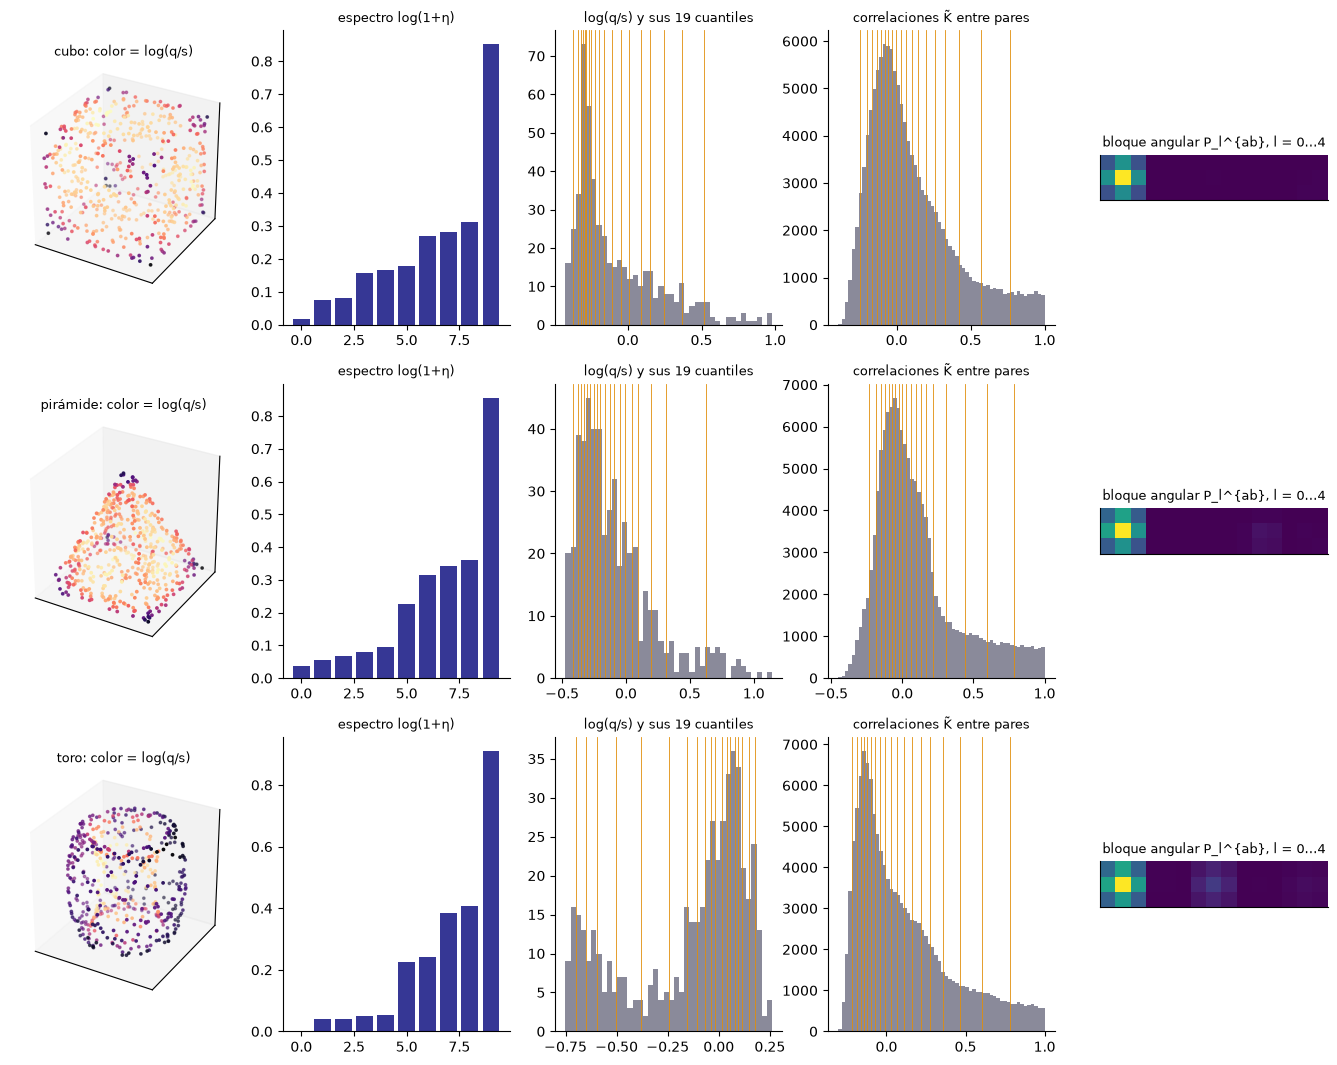

✔ CD_U invariante a rotación, reflexión, escala, traslación y permutación (< 1e-9)


In [122]:
from pointfield.objects import make_object
r6 = np.random.default_rng(11)
obj = {"cubo": make_object("cube", 3, 512, r6, transform=False), "pirámide": make_object("pyramid", 3, 512, r6, transform=False),
       "toro": make_object("torus", 3, 512, r6, transform=False)}
fig = plt.figure(figsize=(17, 13))
for i, (nombre, Xo) in enumerate(obj.items()):
    v, B, aux = descriptor_cd(Xo, bloques=True)
    a = fig.add_subplot(3, 5, 5 * i + 1, projection="3d")
    sc_ = a.scatter(*aux["Y"].T, c=np.log(aux["q"] / 10), cmap="magma_r", s=3); a.set_title(f"{nombre}: color = log(q/s)", fontsize=9)
    a.set_xticks([]); a.set_yticks([]); a.set_zticks([]); a.set_box_aspect((1, 1, 1))
    a = fig.add_subplot(3, 5, 5 * i + 2); a.bar(range(10), B["espectro"], color=AZUL); a.set_title("espectro log(1+η)", fontsize=9)
    a = fig.add_subplot(3, 5, 5 * i + 3); a.hist(np.log(aux["q"] / 10), bins=40, color=GRIS)
    for qv in B["scores"]: a.axvline(qv, color=NARANJA, lw=.6)
    a.set_title("log(q/s) y sus 19 cuantiles", fontsize=9)
    a = fig.add_subplot(3, 5, 5 * i + 4); a.hist(aux["corr"], bins=60, color=GRIS)
    for qv in B["correlaciones"]: a.axvline(qv, color=NARANJA, lw=.6)
    a.set_title("correlaciones K̃ entre pares", fontsize=9)
    a = fig.add_subplot(3, 5, 5 * i + 5)
    mats = np.zeros((5, 3, 3)); iu = np.triu_indices(3)
    for l in range(5):
        mats[l][iu] = B["angular"][6 * l: 6 * (l + 1)]; mats[l] = mats[l] + np.triu(mats[l], 1).T
    a.imshow(np.hstack(mats), cmap="viridis"); a.set_title("bloque angular P_l^{ab}, l = 0…4", fontsize=9); a.set_yticks([]); a.set_xticks([])
guardar(fig, "descriptor_cd_u_bloques", "4.5 Descriptor invariante de objetos")
plt.show()

Xo = obj["toro"]; r7 = np.random.default_rng(5)
Y = random_similarity(Xo, r7, reflect=True)[r7.permutation(len(Xo))]; Y[:, 0] *= -1
verifica(np.abs(descriptor_cd(Y) - descriptor_cd(Xo)).max() < 1e-9, "CD_U invariante a rotación, reflexión, escala, traslación y permutación (< 1e-9)")

**Cómo leer la figura.** Primera columna: cada punto coloreado por su tipicidad $\log(q/s)$; en el cubo, las aristas y vértices son menos típicos que el centro de las caras, y en la pirámide el vértice superior es el punto menos típico. Segunda columna: el espectro; los valores cercanos a 0 indican ecuaciones polinomiales casi satisfechas por la superficie. Columnas 3–4: las distribuciones resumidas por sus cuantiles (líneas naranjas). Última: las cinco matrices $3\times3$ del bloque angular.

## **6.3 Controles: M_U y D2**

* **M_U** (control clave): $\log(1+\eta)$ de las matrices de momentos ponderadas de grado 2 **y** 3, más el mismo bloque angular. Tiene la misma información de momentos que CD_U pero **no usa $M^{-1}$**: si CD_U no supera a M_U, la ventaja no viene de la función de Christoffel.
* **D2** (Osada et al., 2002): histograma (32 intervalos en $[0,4]$) de distancias entre 20 000 pares de puntos al azar de la nube normalizada.

In [123]:
def descriptor_momentos(X, grados=(2, 3)):
    Y, _, _ = normalizar(X); partes = []
    for n in grados:
        t = exponentes(Y.shape[1], n)
        partes.append(np.log1p(np.clip(np.linalg.eigvalsh(matriz_momentos(matriz_caracteristicas(Y, t, pesos_multinomiales(t)))), 0, None)))
    return np.concatenate(partes + [bloque_angular(Y)])

def cortes_momentos(dim):
    out, i0 = {}, 0
    for n in (2, 3): out[f"espectro{n}"] = slice(i0, i0 + comb(dim + n, n)); i0 += comb(dim + n, n)
    out["angular"] = slice(i0, i0 + 30); return out

def descriptor_d2(X, pares=20000, intervalos=32, semilla=0):
    Y, _, _ = normalizar(X); rng_ = np.random.default_rng(semilla)
    i, j = rng_.integers(0, len(Y), pares), rng_.integers(0, len(Y), pares)
    h, _ = np.histogram(np.linalg.norm(Y[i] - Y[j], axis=1), bins=intervalos, range=(0, 4.0))
    return h / h.sum()

for Xo in obj.values():
    verifica(np.allclose(descriptor_momentos(Xo), _lib_mu(Xo)) and np.allclose(descriptor_d2(Xo), _lib_d2(Xo)),
             f"M_U y D2 desde cero = biblioteca ({len(descriptor_momentos(Xo))} y 32 números)")

✔ M_U y D2 desde cero = biblioteca (60 y 32 números)
✔ M_U y D2 desde cero = biblioteca (60 y 32 números)
✔ M_U y D2 desde cero = biblioteca (60 y 32 números)


## **6.4 D3 · Pesos de densidad (CD_W)**

**Problema.** Con muestreo desigual, $M$ se sesga hacia las regiones con más puntos. **Modificación:** $w_i\propto\operatorname{clip}\big[(r_i/\operatorname{med} r)^{m},\,0.25,\,4\big]$, con $r_i$ la distancia al vecino 16 y $m=d-1$ (dimensión de una superficie). Los puntos en zonas poco muestreadas pesan más. CD_W es CD_U con $M=V^\top\operatorname{diag}(w)V$.

✔ pesos de densidad desde cero = biblioteca


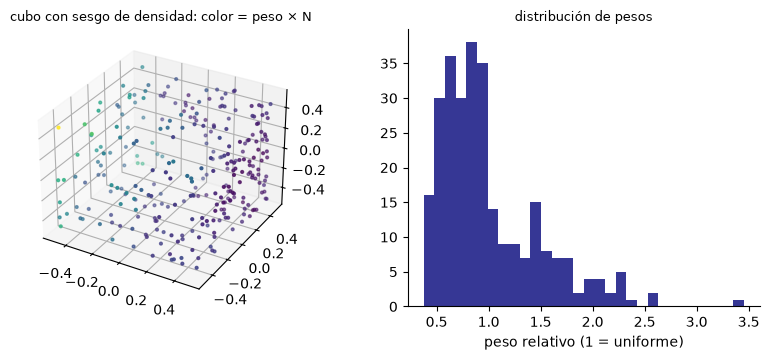

‖CD_W − CD_U‖ en este cubo sesgado = 0.564


In [124]:
def pesos_densidad(X, k=16, m=None, recorte=(0.25, 4.0)):
    m = X.shape[1] - 1 if m is None else m; k = min(k, len(X) - 1)
    r = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)[0][:, -1]
    w = np.clip((r / np.median(r)) ** m, *recorte)
    return w / w.sum()

Xd = obj["cubo"]; u = np.array([1.0, 0.3, -0.2]); u /= np.linalg.norm(u)
t_ = (Xd - Xd.mean(0)) @ u; keep = np.random.default_rng(2).random(len(Xd)) < 0.15 + 0.85 * (t_ - t_.min()) / np.ptp(t_)
Xs = Xd[keep]; ws = pesos_densidad(Xs)
verifica(np.allclose(ws, _lib_w(Xs)), "pesos de densidad desde cero = biblioteca")
fig = plt.figure(figsize=(10, 3.6))
a = fig.add_subplot(1, 2, 1, projection="3d"); a.scatter(*Xs.T, c=ws * len(ws), cmap="viridis", s=4); a.set_title("cubo con sesgo de densidad: color = peso × N", fontsize=9)
a = fig.add_subplot(1, 2, 2); a.hist(ws * len(ws), bins=30, color=AZUL); a.set_xlabel("peso relativo (1 = uniforme)"); a.set_title("distribución de pesos", fontsize=9)
plt.show()
print(f"‖CD_W − CD_U‖ en este cubo sesgado = {np.linalg.norm(descriptor_cd(Xs, ws) - descriptor_cd(Xs)):.3f}")

## **6.5 D2 · Estandarización por bloques y métrica multivista**

**Estandarización por bloques.** Con media y desviación de las **referencias**: $z=(f-\mu)/\sigma$; cada bloque se divide entre $\sqrt{\text{tamaño}}$ y todo el vector entre $\sqrt{\#\text{bloques}}$, para que ningún bloque domine la distancia por tener más números.

**Métrica multivista.** De cada referencia se generan 4 **vistas**: submuestreo de 128 puntos con probabilidad $\propto\exp(2\,\operatorname{clip}(t,-2,2))$ a lo largo de una dirección aleatoria $t$ (sesgo de densidad) y ruido de 0.01. Con $f_{o,v}$ el descriptor estandarizado de la vista $v$ del objeto $o$:
$$C=\frac1{\#}\sum_{o,v}(f_{o,v}-\bar f_o)(f_{o,v}-\bar f_o)^\top,\qquad W=\Big(C+\eta\,\tfrac{\operatorname{tr}C}{p}I\Big)^{-1/2},\qquad d(f,g)=\|W(f-g)\|.$$
$C$ es la variación **dentro** de un mismo objeto (lo que no debería importar), y $W$ la atenúa. $\eta\in\{0.1,1,10\}$ se elige por recuperación de identidad (vista → su propio objeto) en un 20 % de las referencias; las consultas nunca intervienen.

In [125]:
from pointfield.learning import MultiViewMetric, make_view, BlockScaler

class Escalador:
    def __init__(self, cortes): self.cortes = cortes
    def ajustar(self, F):
        self.mu = F.mean(0); sd = F.std(0); self.sd = np.where(sd > 1e-12, sd, 1.0); return self
    def __call__(self, F):
        Z = (np.asarray(F) - self.mu) / self.sd; out = np.empty_like(Z)
        for sl in self.cortes.values(): out[..., sl] = Z[..., sl] / np.sqrt(sl.stop - sl.start)
        return out / np.sqrt(len(self.cortes))

def vista(X, rng_, n_sub=128, sesgo=2.0, ruido=0.01):
    Y, c, r = normalizar(X)
    u = rng_.normal(size=Y.shape[1]); u /= np.linalg.norm(u); t = Y @ u
    p = np.exp(sesgo * np.clip(t / (t.std() + 1e-12), -2, 2))
    idx = rng_.choice(len(Y), size=min(n_sub, len(Y)), replace=False, p=p / p.sum())
    return (Y[idx] + ruido * rng_.normal(size=(len(idx), Y.shape[1]))) * r + c

def _cov_vistas(V):
    D = (V - V.mean(axis=1, keepdims=True)).reshape(-1, V.shape[2]); return D.T @ D / len(D)

def _blanqueador(C, eta):
    p = len(C)
    if np.trace(C) <= np.finfo(float).eps: return np.eye(p)
    w, Q = np.linalg.eigh(C + eta * np.trace(C) / p * np.eye(p)); return Q @ np.diag(1 / np.sqrt(w)) @ Q.T

def metrica_multivista(V, etas=(0.1, 1.0, 10.0), reserva=0.2, semilla=0):
    "V: (objetos, vistas, p). Devuelve W y la exactitud de identidad por η."
    perm = np.random.default_rng(semilla).permutation(len(V))
    n_ho = min(len(V) - 2, max(2, round(reserva * len(V)))); ho, tr = perm[:n_ho], perm[n_ho:]
    C = _cov_vistas(V[tr]); acc = {}
    for eta in etas:
        W = _blanqueador(C, eta)
        D = np.linalg.norm((V[ho, 0] @ W)[:, None] - (V[ho, 1:].mean(1) @ W)[None], axis=-1)
        acc[eta] = float((D.argmin(1) == np.arange(len(ho))).mean())
    eta = max(etas, key=lambda e: (acc[e], -e))
    return _blanqueador(_cov_vistas(V), eta), eta, acc

nubes_t, _, _ = make_object_dataset(3, 2, 300, seed=3)
ra, rb = np.random.default_rng(9), np.random.default_rng(9)
verifica(all(np.allclose(vista(x, ra), make_view(x, rb)) for x in nubes_t), "vistas desde cero = make_view de la biblioteca")
Fr_t = np.array([descriptor_cd(x) for x in nubes_t]); esc_t = Escalador(cortes_bloques(3)).ajustar(Fr_t)
verifica(np.allclose(esc_t(Fr_t), BlockScaler(_cdlib.block_slices(3)).fit_transform(Fr_t)), "estandarización por bloques desde cero = biblioteca")
rv = np.random.default_rng(4)
Vt = np.array([[esc_t(descriptor_cd(vista(x, rv))) for _ in range(4)] for x in nubes_t])
W_t, eta_t, _ = metrica_multivista(Vt)
lib = MultiViewMetric(seed=0).fit(Vt)
verifica(np.allclose(W_t, lib.W_) and eta_t == lib.eta_, f"métrica multivista desde cero = biblioteca (η = {eta_t})")

✔ vistas desde cero = make_view de la biblioteca
✔ estandarización por bloques desde cero = biblioteca
✔ métrica multivista desde cero = biblioteca (η = 0.1)


## **6.6 Evaluación por recuperación, implementada desde cero**

* **AP de una consulta:** se ordena la galería por distancia; $\mathrm{AP}=\frac1{|\mathcal R|}\sum_{g\in\mathcal R}\mathrm{precisión@rango}(g)$, con $\mathcal R$ los objetos de la misma clase. **mAP** = promedio sobre consultas.
* **1-NN:** fracción de consultas cuyo vecino más cercano en la galería es de su clase.
* **Bootstrap pareado estratificado:** para comparar dos métodos sobre **las mismas** consultas, se remuestrea con reemplazo dentro de cada clase la diferencia de AP por consulta (3000 réplicas en modo completo) y se reporta el intervalo percentil del 95 %. Una diferencia sólo se declara si el intervalo excluye 0.

In [126]:
def distancias(Q, G):
    d2 = (Q ** 2).sum(1)[:, None] + (G ** 2).sum(1)[None] - 2 * Q @ G.T
    return np.sqrt(np.clip(d2, 0, None))

def ap_por_consulta(Q, yq, G, yg):
    D = distancias(Q, G); out = np.empty(len(Q))
    for i in range(len(Q)):
        rel = (yg == yq[i])[np.argsort(D[i], kind="stable")]
        out[i] = np.nan if not rel.any() else (np.cumsum(rel)[rel] / (np.flatnonzero(rel) + 1)).mean()
    return out

def exactitud_1nn(Q, yq, G, yg):
    return float((yg[distancias(Q, G).argmin(1)] == yq).mean())

def bootstrap_pareado(a, b, estratos, n_boot=3000, semilla=0):
    dif = np.asarray(a) - np.asarray(b); grupos = [np.flatnonzero(estratos == s) for s in np.unique(estratos)]
    rng_ = np.random.default_rng(semilla); est = np.empty(n_boot)
    for t in range(n_boot):
        est[t] = dif[np.concatenate([rng_.choice(g, size=len(g), replace=True) for g in grupos])].mean()
    lo, hi = np.quantile(est, [0.025, 0.975])
    return {"Δ": float(dif.mean()), "IC bajo": float(lo), "IC alto": float(hi)}

from pointfield.learning import per_query_ap, paired_bootstrap
Qx, Gx = rng.normal(size=(20, 5)), rng.normal(size=(40, 5)); yqx, ygx = rng.integers(0, 3, 20), rng.integers(0, 3, 40)
verifica(np.allclose(ap_por_consulta(Qx, yqx, Gx, ygx), per_query_ap(Qx, yqx, Gx, ygx)), "AP por consulta desde cero = biblioteca")
a_, b_ = rng.uniform(size=60), rng.uniform(size=60); es_ = np.arange(60) % 4
bl = paired_bootstrap(a_, b_, strata=es_, n_boot=500, seed=1); bm = bootstrap_pareado(a_, b_, es_, 500, 1)
verifica(np.allclose([bm["IC bajo"], bm["IC alto"]], [bl["ci_low"], bl["ci_high"]]), "bootstrap pareado estratificado desde cero = biblioteca")

✔ AP por consulta desde cero = biblioteca
✔ bootstrap pareado estratificado desde cero = biblioteca


## **6.7 Protocolo de evaluación de objetos (común a sintéticos y ModelNet)**

1. **Galería:** objetos de referencia limpios. **Consultas:** objetos distintos, perturbados según la condición.
2. Descriptores CD_U, CD_W, M_U y D2 de las referencias; estandarización ajustada **sólo** con referencias.
3. 4 vistas por referencia → métrica multivista para CD_U, CD_W y M_U (variantes `+métrica`).
4. Condiciones de las consultas: `limpio`; `ruido` 3 % del radio; `densidad` (probabilidad de conservar un punto de 1 a 0.15 a lo largo de una dirección); `oclusión` (se quita el 20 % más lejano en una dirección); `atípicos` (5 % de puntos uniformes en la caja ampliada 20 %).
5. Con `OBJ_REALIZACIONES` > 1, cada consulta perturbada se repite y su AP se promedia por objeto.
6. Contrastes con bootstrap: **CD_U+métrica − M_U+métrica** (¿aporta CD?) y **CD_W+métrica − CD_U+métrica** (¿aportan los pesos?).

El orden de uso del generador aleatorio es idéntico al de `benchmarks/objetos_invariantes.py`, de modo que en modo completo los resultados son los mismos que los de la tesis.

In [127]:
CONDICIONES = ["limpio", "ruido", "densidad", "oclusión", "atípicos"]
_COND_EN = dict(zip(CONDICIONES, ["clean", "noise", "density", "occlusion", "outliers"]))

def _dir_unitaria(rng_, d):
    u = rng_.normal(size=d); return u / np.linalg.norm(u)

def perturbar_objeto(X, cond, rng_):
    c = X.mean(0); r = np.sqrt(((X - c) ** 2).sum(1).mean())
    if cond == "limpio": return X
    if cond == "ruido": return X + 0.03 * r * rng_.normal(size=X.shape)
    if cond == "densidad":
        t = (X - c) @ _dir_unitaria(rng_, X.shape[1]) / r
        return X[rng_.random(len(X)) < np.clip(0.15 + 0.85 * (t - t.min()) / np.ptp(t), 0, 1)]
    if cond == "oclusión":
        t = (X - c) @ _dir_unitaria(rng_, X.shape[1]); return X[t < np.quantile(t, 0.8)]
    if cond == "atípicos":
        lo, hi = X.min(0), X.max(0); pad = 0.2 * (hi - lo)
        return np.vstack([X, rng_.uniform(lo - pad, hi + pad, size=(int(0.05 * len(X)), X.shape[1]))])
    raise ValueError(cond)

def descriptores(nubes):
    return {"CD_U": np.array([descriptor_cd(x) for x in nubes]), "CD_W": np.array([descriptor_cd(x, pesos_densidad(x)) for x in nubes]),
            "M_U": np.array([descriptor_momentos(x) for x in nubes]), "D2": np.array([descriptor_d2(x) for x in nubes])}

METODOS_OBJ = ["D2", "M_U", "CD_U", "CD_W", "M_U+métrica", "CD_U+métrica", "CD_W+métrica"]
COLOR_OBJ = {"D2": GRIS, "M_U": "#E8B04A", "CD_U": "#7F80C8", "CD_W": "#9FD0B0", "M_U+métrica": NARANJA, "CD_U+métrica": AZUL, "CD_W+métrica": VERDE}

def evaluar_objetos(ref, y_ref, qry, y_qry, dim, nombre, condiciones=CONDICIONES, n_real=1, semilla=0, n_boot=1000, n_vistas=4):
    rng_ = np.random.default_rng(semilla)
    t0 = time.perf_counter()
    Fr = descriptores(ref)
    esc = {"CD_U": Escalador(cortes_bloques(dim)).ajustar(Fr["CD_U"]), "CD_W": Escalador(cortes_bloques(dim)).ajustar(Fr["CD_W"]),
           "M_U": Escalador(cortes_momentos(dim)).ajustar(Fr["M_U"])}
    vistas = [[vista(x, rng_) for _ in range(n_vistas)] for x in ref]
    V = {"CD_U": np.array([[esc["CD_U"](descriptor_cd(v)) for v in vs] for vs in vistas]),
         "CD_W": np.array([[esc["CD_W"](descriptor_cd(v, pesos_densidad(v))) for v in vs] for vs in vistas]),
         "M_U": np.array([[esc["M_U"](descriptor_momentos(v)) for v in vs] for vs in vistas])}
    W = {k: metrica_multivista(V[k], semilla=semilla) for k in V}
    t_desc = time.perf_counter() - t0

    def representar(F):
        out = {"D2": F["D2"]}
        for k in esc:
            out[k] = esc[k](F[k]); out[f"{k}+métrica"] = out[k] @ W[k][0]
        return out
    galeria = representar(Fr)
    filas, contrastes, ap_guardado, consultas = [], [], {}, {}
    for cond in condiciones:
        reps = 1 if cond == "limpio" else n_real
        aps, nns = [], []
        for rep in range(reps):
            Fq = descriptores([perturbar_objeto(x, cond, rng_) for x in qry])
            Q = representar(Fq)
            if rep == 0: consultas[cond] = Q
            aps.append({m: ap_por_consulta(Q[m], y_qry, galeria[m], y_ref) for m in METODOS_OBJ})
            nns.append({m: exactitud_1nn(Q[m], y_qry, galeria[m], y_ref) for m in METODOS_OBJ})
        ap = {m: np.mean([a[m] for a in aps], axis=0) for m in METODOS_OBJ}
        ap_guardado[cond] = ap
        for m in METODOS_OBJ:
            filas.append({"experimento": nombre, "dataset": nombre, "variante": cond, "método": m, "mAP": float(np.nanmean(ap[m])),
                          "1-NN": float(np.mean([n[m] for n in nns]))})
        for a, b in (("CD_U+métrica", "M_U+métrica"), ("CD_W+métrica", "CD_U+métrica")):
            contrastes.append({"condición": cond, "contraste": f"{a} − {b}", **bootstrap_pareado(ap[a], ap[b], y_qry, n_boot, semilla)})
    return {"tabla": pd.DataFrame(filas), "contrastes": pd.DataFrame(contrastes), "ap": ap_guardado, "galeria": galeria,
            "consultas": consultas, "y_ref": np.asarray(y_ref), "y_qry": np.asarray(y_qry), "eta": {k: W[k][1] for k in W},
            "Fr": Fr, "t_descriptores_s": t_desc, "dim": dim}
print("Protocolo de objetos listo.")

Protocolo de objetos listo.


In [128]:
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering

def asignacion_hungara(y, yp):
    "Mapea cada grupo a una clase maximizando aciertos (algoritmo húngaro sobre la tabla de contingencia)."
    clases, grupos = np.unique(y), np.unique(yp)
    T = np.array([[np.sum((yp == g) & (y == c)) for c in clases] for g in grupos])
    fil, col = linear_sum_assignment(-T)
    mapa = {grupos[f]: clases[c] for f, c in zip(fil, col)}
    return np.array([mapa.get(g, -1) for g in yp])

def matriz_confusion(y, yp, n):
    C = np.zeros((n, n), int)
    for a, b in zip(y, yp):
        if b >= 0: C[a, b] += 1
    return C

def reportar_objetos(res, nombre, clases, seccion, max_etiquetas=40):
    T, Cn = res["tabla"], res["contrastes"]
    conds = [c for c in CONDICIONES if c in T.variante.unique()]
    piv = T.pivot(index="método", columns="variante", values="mAP").reindex(index=METODOS_OBJ, columns=conds)
    tabla(piv, 3, f"{nombre} · mAP por método y condición de la consulta")
    tabla(T.pivot(index="método", columns="variante", values="1-NN").reindex(index=METODOS_OBJ, columns=conds), 3, f"{nombre} · exactitud 1-NN")
    fig, ax = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
    w_ = 0.8 / len(METODOS_OBJ)
    for i, m in enumerate(METODOS_OBJ):
        ax[0].bar(np.arange(len(conds)) + (i - len(METODOS_OBJ) / 2 + .5) * w_, piv.loc[m], w_, label=m, color=COLOR_OBJ[m])
    ax[0].set_xticks(range(len(conds))); ax[0].set_xticklabels(conds); ax[0].set_ylabel("mAP"); ax[0].set_ylim(0, 1.05)
    ax[0].legend(fontsize=7, ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    ax[0].set_title(f"{nombre}: mAP por condición")
    for k_, (con, g) in enumerate(Cn.groupby("contraste", sort=False)):
        g = g.set_index("condición").reindex(conds)
        ax[1].errorbar(np.arange(len(conds)) + (k_ - .5) * 0.2, g["Δ"], yerr=[g["Δ"] - g["IC bajo"], g["IC alto"] - g["Δ"]],
                       fmt="o", capsize=3, label=con, color=(AZUL, VERDE)[k_])
    ax[1].axhline(0, color=GRIS); ax[1].set_xticks(range(len(conds))); ax[1].set_xticklabels(conds); ax[1].set_ylabel("Δ mAP (IC 95 %)")
    ax[1].legend(fontsize=7); ax[1].set_title("Contrastes pareados")
    guardar(fig, f"objetos_{nombre}_map", seccion)
    plt.show()
    tabla(Cn.set_index(["contraste", "condición"]), 3, f"{nombre} · contrastes (bootstrap pareado estratificado)")

    # AP por clase (consultas limpias)
    yq = res["y_qry"]; ap = res["ap"]["limpio"]
    por_clase = pd.DataFrame({m: [np.nanmean(ap[m][yq == c]) for c in range(len(clases))] for m in ("D2", "M_U+métrica", "CD_U+métrica")},
                             index=clases)
    tabla(por_clase, 3, f"{nombre} · AP medio por clase (consultas limpias)")

    # Matriz de confusión de 1-NN (clasificación por vecino más cercano) y agrupamiento no supervisado de los descriptores
    G, Q = res["galeria"], res["consultas"]["limpio"]
    pred_1nn = res["y_ref"][distancias(Q["CD_U+métrica"], G["CD_U+métrica"]).argmin(1)]
    F_all = np.vstack([G["CD_U+métrica"], Q["CD_U+métrica"]]); y_all = np.r_[res["y_ref"], yq]
    k = len(clases); filas = []
    agrupadores = {"K-Means": lambda F: KMeans(k, n_init=10, random_state=0).fit_predict(F),
                   "Aglomerativo (Ward)": lambda F: AgglomerativeClustering(k, linkage="ward").fit_predict(F),
                   "Spectral k-NN": lambda F: SpectralClustering(k, affinity="nearest_neighbors", n_neighbors=min(10, len(F) - 1), random_state=0).fit_predict(F)}
    mejor = (-1, None, None)
    for rep_nombre in ("D2", "M_U+métrica", "CD_U+métrica"):
        F = np.vstack([G[rep_nombre], Q[rep_nombre]])
        for an, af in agrupadores.items():
            yp = af(F); mc = metricas_cluster(F, y_all, yp)
            filas.append({"descriptor": rep_nombre, "agrupamiento": an, **{c: mc[c] for c in ("ARI", "NMI", "homogeneidad", "completitud")}})
            registrar(experimento=f"{nombre}_agrupamiento_descriptores", dataset=nombre, método=f"{rep_nombre} · {an}", **{c: mc[c] for c in ("ARI", "NMI")})
            if rep_nombre == "CD_U+métrica" and mc["ARI"] > mejor[0]: mejor = (mc["ARI"], an, yp)
    tabla(pd.DataFrame(filas).set_index(["descriptor", "agrupamiento"]), 3, f"{nombre} · agrupamiento no supervisado de los descriptores (referencias + consultas limpias)")

    fig, ax = plt.subplots(1, 2, figsize=(min(7 + 0.35 * k, 22), min(3.5 + 0.17 * k, 11)))
    for a, (C, tit) in zip(ax, ((matriz_confusion(yq, pred_1nn, k), "1-NN de CD_U+métrica (consultas → galería)"),
                               (matriz_confusion(y_all, asignacion_hungara(y_all, mejor[2]), k), f"{mejor[1]} sobre CD_U+métrica\n(grupos asignados a clases con el algoritmo húngaro)"))):
        Cn_ = C / np.maximum(C.sum(1, keepdims=True), 1)
        a.imshow(Cn_, cmap="Blues", vmin=0, vmax=1)
        etiquetas = clases if k <= max_etiquetas else [""] * k
        a.set_xticks(range(k)); a.set_xticklabels(etiquetas, rotation=90, fontsize=7 if k > 12 else 8)
        a.set_yticks(range(k)); a.set_yticklabels(etiquetas, fontsize=7 if k > 12 else 8)
        a.set_xlabel("predicho"); a.set_ylabel("real"); a.set_title(tit, fontsize=9)
        if k <= 12:
            for (i_, j_), v in np.ndenumerate(C): a.text(j_, i_, v, ha="center", va="center", fontsize=7, color="white" if Cn_[i_, j_] > .5 else "k")
    guardar(fig, f"objetos_{nombre}_confusion", seccion)
    plt.show()

    # Embeddings 2D de los descriptores (PCA y UMAP), coloreados por clase sólo para visualizar
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    cmap = plt.cm.tab10 if k <= 10 else plt.cm.nipy_spectral
    for j, rep_nombre in enumerate(("M_U+métrica", "CD_U+métrica")):
        F = np.vstack([G[rep_nombre], Q[rep_nombre]])
        for i, (tn, tf) in enumerate((("PCA", lambda F: PCA(2).fit_transform(F)), ("UMAP", lambda F: umap_2d(F, min(15, len(F) - 1)) if UMAP_OK else PCA(2).fit_transform(F)))):
            E = tf(F); a = ax[2 * j + i]
            a.scatter(E[:, 0], E[:, 1], c=y_all, cmap=cmap, s=8, vmin=0, vmax=max(k - 1, 1))
            a.set_title(f"{rep_nombre} → {tn}\nT = {sk_trust(F, E, n_neighbors=min(10, len(F) // 3)):.2f}", fontsize=9); a.set_xticks([]); a.set_yticks([])
    guardar(fig, f"objetos_{nombre}_embeddings", seccion)
    plt.show()
    for fila in T.to_dict("records"):
        registrar(**fila)

## **6.8 Benchmark de objetos sintéticos (3D y 2D)**

Referencias: `OBJ_REF_POR_CLASE` objetos por familia (semilla 20261025); consultas: `OBJ_CONS_POR_CLASE` objetos nuevos (semilla 20261026); 512 puntos; similitud aleatoria por objeto.

In [129]:
RES_OBJ = {}
for dim in (3, 2):
    def _corrida(dim=dim):
        ref, yr, fam = make_object_dataset(dim, CONFIG["OBJ_REF_POR_CLASE"], CONFIG["OBJ_PUNTOS"], seed=CONFIG["SEMILLA_GLOBAL"])
        qry, yq, _ = make_object_dataset(dim, CONFIG["OBJ_CONS_POR_CLASE"], CONFIG["OBJ_PUNTOS"], seed=CONFIG["SEMILLA_GLOBAL"] + 1)
        res = evaluar_objetos(ref, yr, qry, yq, dim, f"sinteticos_{dim}d", n_real=CONFIG["OBJ_REALIZACIONES"],
                              semilla=CONFIG["SEMILLA_GLOBAL"], n_boot=CONFIG["BOOTSTRAP"])
        res["clases"] = fam
        return res
    (res, dt, mb) = medir(lambda: en_cache(f"objetos_{dim}d", _corrida))
    RES_OBJ[dim] = res
    print(f"{dim}D: {len(res['y_ref'])} referencias, {len(res['y_qry'])} consultas, {dt:.1f} s, η = {res['eta']}")

if not RAPIDO:
    csv3 = RAIZ / "benchmarks" / "results" / "objetos_3d.csv"
    if csv3.exists():
        ref_ = pd.read_csv(csv3); ref_ = ref_[~ref_.method.str.contains(" - ")]
        mapa = {"CD_U_metric": "CD_U+métrica", "M_U_metric": "M_U+métrica", "CD_W_metric": "CD_W+métrica"}
        ref_["método"] = ref_.method.replace(mapa); ref_["variante"] = ref_.condition.map({v: k for k, v in _COND_EN.items()})
        m = RES_OBJ[3]["tabla"].merge(ref_, on=["método", "variante"])
        verifica(np.allclose(m["mAP_x"], m["mAP_y"], atol=1e-9), f"modo completo: los {len(m)} mAP 3D coinciden con objetos_3d.csv de la tesis")

3D: 56 referencias, 28 consultas, 39.0 s, η = {'CD_U': 0.1, 'CD_W': 0.1, 'M_U': 0.1}
2D: 48 referencias, 24 consultas, 50.9 s, η = {'CD_U': 0.1, 'CD_W': 0.1, 'M_U': 0.1}


**sinteticos_3d · mAP por método y condición de la consulta**

variante,limpio,ruido,densidad,oclusión,atípicos
método,,,,,
D2,0.751,0.751,0.605,0.674,0.720
M_U,0.856,0.856,0.450,0.580,0.529
CD_U,0.923,0.916,0.478,0.699,0.678
CD_W,0.917,0.910,0.590,0.739,0.371
M_U+métrica,0.900,0.896,0.873,0.776,0.553
CD_U+métrica,0.966,0.961,0.913,0.888,0.740
CD_W+métrica,0.961,0.949,0.935,0.918,0.365


**sinteticos_3d · exactitud 1-NN**

variante,limpio,ruido,densidad,oclusión,atípicos
método,,,,,
D2,0.857,0.893,0.643,0.679,0.821
M_U,1.000,0.964,0.607,0.786,0.429
CD_U,1.000,1.000,0.643,0.821,0.714
CD_W,1.000,1.000,0.643,0.893,0.357
M_U+métrica,1.000,1.000,1.000,0.786,0.536
CD_U+métrica,1.000,1.000,1.000,1.000,0.679
CD_W+métrica,1.000,1.000,1.000,1.000,0.250


[figura 39] 39_objetos_sinteticos_3d_map.png  →  5.4 Descripción de objetos sintéticos


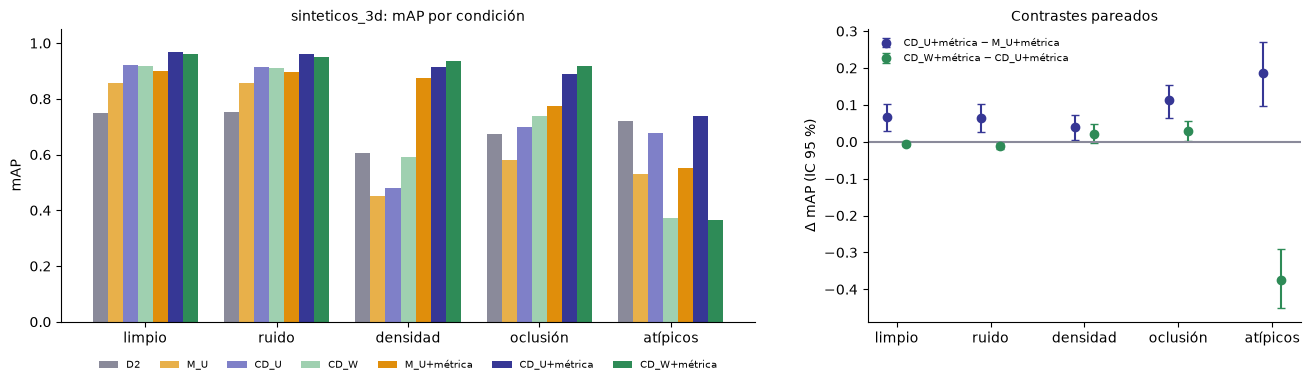

**sinteticos_3d · contrastes (bootstrap pareado estratificado)**

,,Δ,IC bajo,IC alto
contraste,condición,,,
CD_U+métrica − M_U+métrica,limpio,0.066,0.030,0.101
CD_W+métrica − CD_U+métrica,limpio,-0.005,-0.012,0.003
CD_U+métrica − M_U+métrica,ruido,0.065,0.026,0.102
CD_W+métrica − CD_U+métrica,ruido,-0.012,-0.021,-0.003
CD_U+métrica − M_U+métrica,densidad,0.039,0.006,0.073
CD_W+métrica − CD_U+métrica,densidad,0.022,-0.003,0.049
CD_U+métrica − M_U+métrica,oclusión,0.112,0.064,0.154
CD_W+métrica − CD_U+métrica,oclusión,0.030,0.002,0.057
CD_U+métrica − M_U+métrica,atípicos,0.186,0.098,0.269


**sinteticos_3d · AP medio por clase (consultas limpias)**

,D2,M_U+métrica,CD_U+métrica
sphere,1.000,1.000,1.000
ellipsoid,0.822,1.000,1.000
cube,1.000,1.000,1.000
cylinder,0.314,0.719,0.946
cone,0.656,0.825,0.914
torus,0.818,0.933,0.985
pyramid,0.644,0.822,0.921


**sinteticos_3d · agrupamiento no supervisado de los descriptores (referencias + consultas limpias)**

ARI    NMI  homogeneidad  completitud
descriptor   agrupamiento                                                
D2           K-Means              0.657  0.813         0.789        0.838
             Aglomerativo (Ward)  0.619  0.795         0.767        0.825
             Spectral k-NN        0.683  0.787         0.783        0.791
M_U+métrica  K-Means              0.710  0.857         0.834        0.881
             Aglomerativo (Ward)  0.728  0.877         0.852        0.903
             Spectral k-NN        0.765  0.855         0.851        0.858
CD_U+métrica K-Means              0.797  0.922         0.898        0.947
             Aglomerativo (Ward)  0.797  0.922         0.898        0.947
             Spectral k-NN        1.000  1.000         1.000        1.000

[figura 40] 40_objetos_sinteticos_3d_confusion.png  →  5.4 Descripción de objetos sintéticos


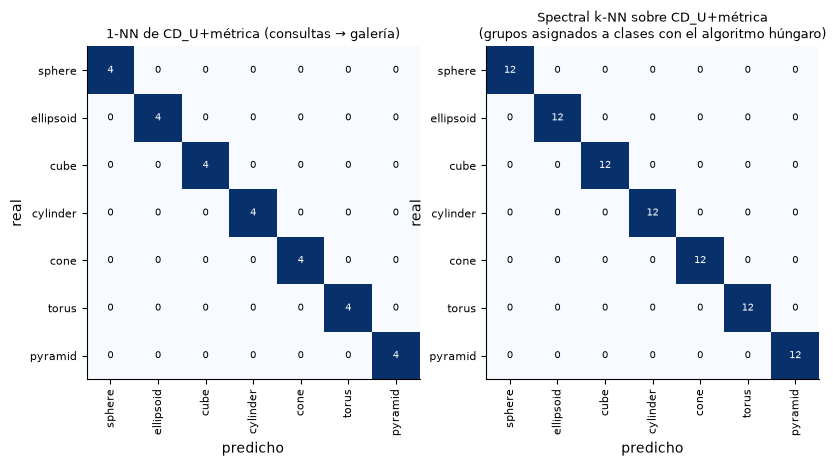

[figura 41] 41_objetos_sinteticos_3d_embeddings.png  →  5.4 Descripción de objetos sintéticos


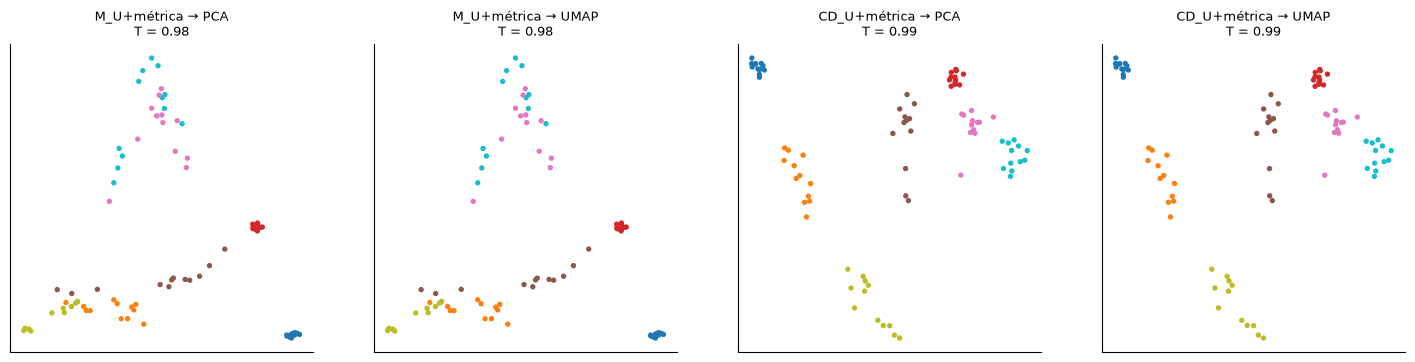

In [130]:
reportar_objetos(RES_OBJ[3], "sinteticos_3d", RES_OBJ[3]["clases"], "5.4 Descripción de objetos sintéticos")

**sinteticos_2d · mAP por método y condición de la consulta**

variante,limpio,ruido,densidad,oclusión,atípicos
método,,,,,
D2,0.736,0.735,0.485,0.633,0.736
M_U,0.804,0.806,0.370,0.420,0.638
CD_U,0.886,0.862,0.413,0.538,0.755
CD_W,0.890,0.866,0.415,0.554,0.553
M_U+métrica,0.869,0.872,0.669,0.617,0.641
CD_U+métrica,0.925,0.904,0.838,0.819,0.858
CD_W+métrica,0.927,0.903,0.827,0.855,0.706


**sinteticos_2d · exactitud 1-NN**

variante,limpio,ruido,densidad,oclusión,atípicos
método,,,,,
D2,1.000,1.000,0.500,0.708,1.000
M_U,0.958,0.958,0.292,0.375,0.583
CD_U,1.000,1.000,0.375,0.458,0.917
CD_W,1.000,1.000,0.292,0.583,0.500
M_U+métrica,1.000,1.000,0.708,0.583,0.542
CD_U+métrica,1.000,1.000,0.833,0.750,0.917
CD_W+métrica,1.000,1.000,0.833,0.875,0.625


[figura 42] 42_objetos_sinteticos_2d_map.png  →  5.4 Descripción de objetos sintéticos (2D)


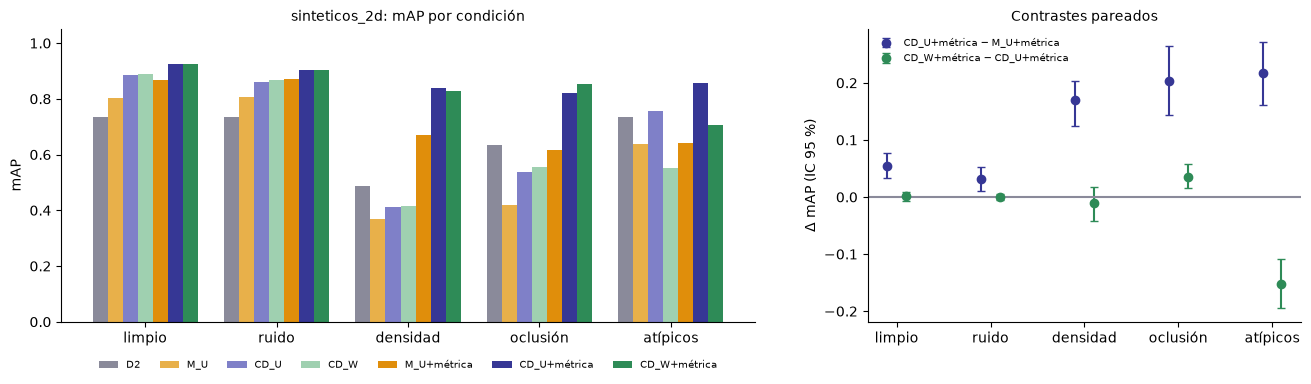

**sinteticos_2d · contrastes (bootstrap pareado estratificado)**

,,Δ,IC bajo,IC alto
contraste,condición,,,
CD_U+métrica − M_U+métrica,limpio,0.055,0.033,0.077
CD_W+métrica − CD_U+métrica,limpio,0.002,-0.007,0.010
CD_U+métrica − M_U+métrica,ruido,0.032,0.011,0.053
CD_W+métrica − CD_U+métrica,ruido,-0.001,-0.005,0.005
CD_U+métrica − M_U+métrica,densidad,0.169,0.125,0.203
CD_W+métrica − CD_U+métrica,densidad,-0.011,-0.042,0.018
CD_U+métrica − M_U+métrica,oclusión,0.203,0.144,0.264
CD_W+métrica − CD_U+métrica,oclusión,0.035,0.015,0.059
CD_U+métrica − M_U+métrica,atípicos,0.217,0.161,0.271


**sinteticos_2d · AP medio por clase (consultas limpias)**

,D2,M_U+métrica,CD_U+métrica
ellipse,0.482,0.613,0.777
rectangle,0.323,0.709,0.843
triangle,0.815,0.981,1.000
hexagon,1.000,1.000,1.000
star,0.814,1.000,0.942
annulus,0.984,0.913,0.985


**sinteticos_2d · agrupamiento no supervisado de los descriptores (referencias + consultas limpias)**

ARI    NMI  homogeneidad  completitud
descriptor   agrupamiento                                                
D2           K-Means              0.443  0.621         0.601        0.643
             Aglomerativo (Ward)  0.612  0.741         0.717        0.767
             Spectral k-NN        0.493  0.667         0.660        0.674
M_U+métrica  K-Means              0.789  0.856         0.853        0.860
             Aglomerativo (Ward)  0.785  0.871         0.871        0.871
             Spectral k-NN        0.785  0.871         0.871        0.871
CD_U+métrica K-Means              0.797  0.884         0.876        0.892
             Aglomerativo (Ward)  0.819  0.898         0.889        0.907
             Spectral k-NN        0.935  0.957         0.955        0.958

[figura 43] 43_objetos_sinteticos_2d_confusion.png  →  5.4 Descripción de objetos sintéticos (2D)


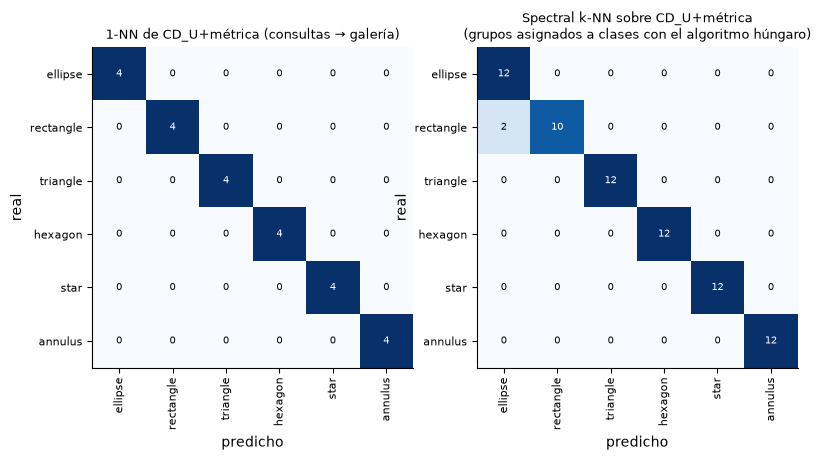

[figura 44] 44_objetos_sinteticos_2d_embeddings.png  →  5.4 Descripción de objetos sintéticos (2D)


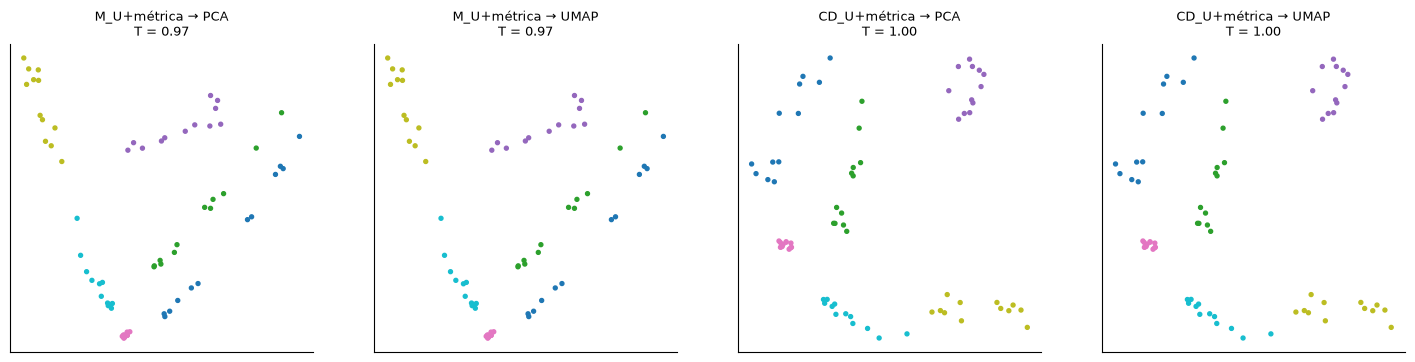

In [131]:
reportar_objetos(RES_OBJ[2], "sinteticos_2d", RES_OBJ[2]["clases"], "5.4 Descripción de objetos sintéticos (2D)")

**Interpretación.** En las familias sintéticas el descriptor CD con métrica supera al control de momentos cuando el intervalo del contraste queda a la derecha de 0. Los pesos de densidad (CD_W) sólo ayudan en la condición de densidad y son muy dañinos con atípicos, porque dan más peso precisamente a los puntos aislados. Las familias son pocas y muy distintas, así que estos números sirven para verificar el método, no para afirmar superioridad en datos reales (§7).

## **6.9 Ablación de los bloques del descriptor**

¿Qué bloque aporta? Se recalcula el mAP de las familias 3D usando sólo subconjuntos de bloques de CD_U (estandarizados igual, sin métrica), con las mismas consultas ya calculadas.

**Ablación de bloques de CD_U (familias 3D, sin métrica)**

condición,limpio,ruido,densidad,oclusión,atípicos
bloques,,,,,
sólo espectro,0.846,0.847,0.826,0.584,0.737
espectro + scores,0.894,0.873,0.520,0.596,0.589
espectro + scores + correlaciones (sin angular),0.953,0.940,0.670,0.748,0.617
sólo angular,0.718,0.718,0.271,0.374,0.709
scores + correlaciones (sólo términos con M⁻¹),0.927,0.901,0.549,0.669,0.434
completo (CD_U),0.923,0.916,0.478,0.699,0.678


[figura 45] 45_ablacion_bloques_descriptor.png  →  5.7 Análisis frente a la hipótesis (ablación del descriptor)


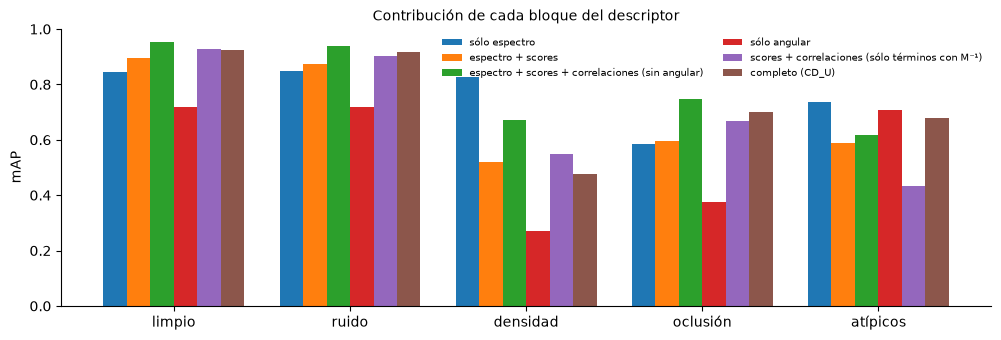

In [132]:
r3 = RES_OBJ[3]; cortes3 = cortes_bloques(3)
SUBCONJ = {"sólo espectro": ["espectro"], "espectro + scores": ["espectro", "scores"],
           "espectro + scores + correlaciones (sin angular)": ["espectro", "scores", "correlaciones"],
           "sólo angular": ["angular"], "scores + correlaciones (sólo términos con M⁻¹)": ["scores", "correlaciones"],
           "completo (CD_U)": ["espectro", "scores", "correlaciones", "angular"]}
filas = []
for nombre, bl in SUBCONJ.items():
    idx = np.concatenate([np.arange(cortes3[b].start, cortes3[b].stop) for b in bl])
    for cond, Q in r3["consultas"].items():
        ap_ = ap_por_consulta(Q["CD_U"][:, idx], r3["y_qry"], r3["galeria"]["CD_U"][:, idx], r3["y_ref"])
        filas.append({"bloques": nombre, "condición": cond, "mAP": np.nanmean(ap_)})
abl_b = pd.DataFrame(filas).pivot(index="bloques", columns="condición", values="mAP").reindex(index=list(SUBCONJ), columns=list(r3["consultas"]))
tabla(abl_b, 3, "Ablación de bloques de CD_U (familias 3D, sin métrica)")
fig, ax = plt.subplots(figsize=(12, 3.6))
w_ = 0.8 / len(SUBCONJ)
for i, nombre in enumerate(SUBCONJ):
    ax.bar(np.arange(abl_b.shape[1]) + (i - len(SUBCONJ) / 2 + .5) * w_, abl_b.loc[nombre], w_, label=nombre)
ax.set_xticks(range(abl_b.shape[1])); ax.set_xticklabels(abl_b.columns); ax.set_ylabel("mAP"); ax.legend(fontsize=7, ncol=2)
ax.set_title("Contribución de cada bloque del descriptor")
guardar(fig, "ablacion_bloques_descriptor", "5.7 Análisis frente a la hipótesis (ablación del descriptor)")
plt.show()

**Interpretación.** El renglón "scores + correlaciones" aísla los términos que dependen de $M^{-1}$ (lo propio de CD); "sólo espectro" y "sólo angular" contienen información de momentos sin inversión. Comparar esos renglones por condición indica en qué perturbaciones la parte propiamente CD aporta información que los momentos no tienen.

---
# **7. Evaluación con datos reales: ModelNet10 y ModelNet40**

**Datos** (Wu et al., 2015). Mallas CAD de objetos: ModelNet10 tiene 10 clases de muebles (≈ 4 900 mallas) y ModelNet40, 40 clases (≈ 12 300). Ambos vienen con partición oficial `train`/`test`. En la tesis ModelNet se usa como **aproximación a objetos capturados por LiDAR**: se muestrean puntos sobre la superficie y se aplican perturbaciones que imitan al sensor (§6.7).

**Preprocesamiento.**
1. Lectura de cada `.off` con `pointfield.geometry.mesh` (corrige el encabezado defectuoso `OFF490 518 0` de algunos archivos; caras con más de 3 vértices se triangulan en abanico).
2. Eliminación de duplicados exactos por SHA-256 del archivo.
3. Muestreo de `MN_PUNTOS` = 512 puntos **uniformes en área**.
4. Similitud aleatoria por objeto (rotación/reflexión, escala, traslación): las mallas de ModelNet vienen alineadas y no se quiere que el método se aproveche de eso.
5. Normalización (centro y radio RMS) dentro de cada descriptor.

**Particiones.** Con semilla 20261025: referencias estratificadas de `train` y consultas estratificadas de `test` (nunca se mezclan). Las etiquetas **sólo** se usan para evaluar (mAP, 1-NN, ARI/NMI de los agrupamientos). En modo completo, ModelNet10 usa 400 referencias y 200 consultas: exactamente el protocolo de la corrida final de la tesis (`benchmarks/modelnet10.py`), y se comprueba que los resultados coinciden con su CSV.

**Disponibilidad.** Los datasets no se descargan desde el cuaderno. Indicar la carpeta en `CONFIG["MODELNET10_ROOT"]` / `CONFIG["MODELNET40_ROOT"]` (o en las variables de entorno del mismo nombre). Si no existe, la sección se omite sin error.

In [133]:
import modelnet10 as MNB                      # funciones index/stratified/load de benchmarks/modelnet10.py
from pointfield.geometry.mesh import TriangleMesh

def disponible(root):
    return root is not None and Path(root).expanduser().is_dir()

def indice_modelnet(root):
    root = Path(root).expanduser()
    train, clases = MNB.index(root, "train"); test, _ = MNB.index(root, "test")
    return root, train, test, clases

def galeria_clases(train, clases, columnas, nombre, seccion, puntos=2048):
    filas_ = int(np.ceil(len(clases) / columnas))
    fig = plt.figure(figsize=(2.6 * columnas, 2.6 * filas_))
    for i, c in enumerate(clases):
        f = next(p for p, cc in train if cc == c)
        Xc_ = TriangleMesh.from_off(f).sample(puntos, seed=0)
        a = fig.add_subplot(filas_, columnas, i + 1, projection="3d")
        a.scatter(Xc_[:, 0], Xc_[:, 1], Xc_[:, 2], c=Xc_[:, 2], cmap="viridis", s=0.6)
        a.view_init(20, -60); a.set_box_aspect(np.ptp(Xc_, axis=0) / np.ptp(Xc_, axis=0).max())
        a.set_xticks([]); a.set_yticks([]); a.set_zticks([]); a.set_title(c, fontsize=9)
    fig.suptitle(f"{nombre}: un ejemplo por clase ({puntos} puntos uniformes en área)", y=1.0)
    guardar(fig, f"{nombre}_galeria_clases", seccion)
    plt.show()

def distribucion_clases(train, test, clases, nombre, seccion):
    n_tr = pd.Series([c for _, c in train]).value_counts().reindex(clases).fillna(0).astype(int)
    n_te = pd.Series([c for _, c in test]).value_counts().reindex(clases).fillna(0).astype(int)
    fig, ax = plt.subplots(figsize=(max(8, 0.35 * len(clases)), 3.6))
    ax.bar(np.arange(len(clases)) - 0.2, n_tr, 0.4, label="train", color=AZUL); ax.bar(np.arange(len(clases)) + 0.2, n_te, 0.4, label="test", color=NARANJA)
    ax.set_xticks(range(len(clases))); ax.set_xticklabels(clases, rotation=90 if len(clases) > 10 else 30, ha="right" if len(clases) <= 10 else "center")
    ax.set_ylabel("mallas (sin duplicados)"); ax.legend(); ax.set_title(f"{nombre}: muestras por clase")
    guardar(fig, f"{nombre}_distribucion_clases", seccion)
    plt.show()
    return pd.DataFrame({"train": n_tr, "test": n_te})

def experimento_modelnet(nombre, root, ref_por_clase, cons_por_clase, columnas):
    if not disponible(root):
        print(f"{nombre}: no se encontró la carpeta ({root!r}). Se omite esta sección; defina CONFIG['{nombre.upper()}_ROOT'].")
        return None
    root, train, test, clases = indice_modelnet(root)
    display(Markdown(f"**{nombre}: {len(clases)} clases** — " + ", ".join(clases)))
    conteo = distribucion_clases(train, test, clases, nombre, "5.5 ModelNet (datos)")
    tabla(conteo.T, 0, f"{nombre}: mallas por clase y partición")
    galeria_clases(train, clases, columnas, nombre, "5.5 ModelNet (datos)")
    rng_ = np.random.default_rng(CONFIG["SEMILLA_GLOBAL"])
    ref_items = MNB.stratified(train, clases, ref_por_clase * len(clases), rng_)
    qry_items = MNB.stratified(test, clases, cons_por_clase * len(clases), rng_)
    (R, yR), dt_r, _ = medir(MNB.load, ref_items, clases, CONFIG["MN_PUNTOS"], rng_)
    (Q, yQ), dt_q, _ = medir(MNB.load, qry_items, clases, CONFIG["MN_PUNTOS"], rng_)
    for X_ in R[:3] + Q[:3]:
        verifica(X_.shape == (CONFIG["MN_PUNTOS"], 3) and np.isfinite(X_).all(), f"{nombre}: nube de forma ({CONFIG['MN_PUNTOS']}, 3) y finita")
    print(f"{nombre}: {len(R)} referencias ({dt_r:.0f} s) y {len(Q)} consultas ({dt_q:.0f} s) cargadas y muestreadas")
    res, dt, mb = medir(lambda: evaluar_objetos(R, yR, Q, yQ, 3, nombre, n_real=1, semilla=CONFIG["SEMILLA_GLOBAL"], n_boot=CONFIG["BOOTSTRAP"]))
    print(f"{nombre}: evaluación completa en {dt:.0f} s (pico {mb:.0f} MB); η elegido = {res['eta']}")
    res.update({"clases": clases, "R": R, "yR": yR})
    return res

## **7.1 ModelNet10**

In [134]:
RES_MN = {}
RES_MN["modelnet10"] = experimento_modelnet("modelnet10", CONFIG["MODELNET10_ROOT"], CONFIG["MN10_REF_POR_CLASE"], CONFIG["MN10_CONS_POR_CLASE"], 5)

modelnet10: no se encontró la carpeta (None). Se omite esta sección; defina CONFIG['MODELNET10_ROOT'].


In [135]:
r_ = RES_MN["modelnet10"]
if r_ is not None:
    # ejemplos de nubes y su representación CD: tipicidad por punto y descriptor
    fig = plt.figure(figsize=(16, 7))
    for i, c in enumerate(np.unique(r_["yR"])[:4]):
        Xc_ = r_["R"][int(np.flatnonzero(r_["yR"] == c)[0])]
        v, B, aux = descriptor_cd(Xc_, bloques=True)
        a = fig.add_subplot(2, 4, i + 1, projection="3d")
        a.scatter(*aux["Y"].T, c=np.log(aux["q"] / 10), cmap="magma_r", s=3); a.set_title(f"{r_['clases'][c]}: log(q/s)", fontsize=9)
        a.set_xticks([]); a.set_yticks([]); a.set_zticks([])
        a = fig.add_subplot(2, 4, i + 5); a.bar(range(len(v)), v, color=[AZUL] * 10 + [NARANJA] * 19 + [VERDE] * 19 + [MORADO] * 30)
        a.set_title("CD_U: espectro | scores | correl. | angular", fontsize=8); a.set_xticks([])
    guardar(fig, "modelnet10_ejemplos_descriptor", "5.5 ModelNet10")
    plt.show()
    reportar_objetos(r_, "modelnet10", r_["clases"], "5.5 ModelNet10")
    csv_t = RAIZ / "benchmarks" / "results" / "modelnet10_test.csv"
    if not RAPIDO and csv_t.exists():
        ref_ = pd.read_csv(csv_t); ref_ = ref_[~ref_.method.str.contains(" - ")]
        ref_["método"] = ref_.method.replace({"CD_U_metric": "CD_U+métrica", "M_U_metric": "M_U+métrica", "CD_W_metric": "CD_W+métrica"})
        ref_["variante"] = ref_.condition.map({v: k for k, v in _COND_EN.items()})
        m = r_["tabla"].merge(ref_, on=["método", "variante"])
        verifica(np.allclose(m["mAP_x"], m["mAP_y"], atol=1e-9), f"modo completo: los {len(m)} mAP coinciden con modelnet10_test.csv de la corrida final")

**Cómo leer los resultados de ModelNet.**
* La tabla de mAP y la gráfica de barras comparan los siete descriptores en las cinco condiciones; la gráfica de contrastes dice si la diferencia CD − momentos es distinguible de cero.
* La matriz de confusión izquierda es la clasificación por vecino más cercano (cada consulta toma la clase de su referencia más cercana): muestra qué clases se confunden (por ejemplo, escritorio, mesa y buró).
* La matriz derecha viene de un **agrupamiento sin etiquetas** de los descriptores; para poder dibujarla, cada grupo se asigna a una clase con el algoritmo húngaro (la asignación uno a uno que maximiza aciertos). Esta asignación usa las etiquetas y por eso sólo sirve para **visualizar**; las métricas del agrupamiento (ARI, NMI) no dependen de ella.
* Los embeddings PCA/UMAP de los descriptores muestran qué tan separadas quedan las clases; el color es la clase real sólo para visualizar.

## **7.2 ModelNet40**

Mismo protocolo con 40 clases. Con más clases y clases muy parecidas (por ejemplo `cup`/`vase`/`flower_pot`, `desk`/`table`), se espera un mAP mucho menor; la pregunta es si la relación entre CD y el control de momentos se mantiene.

In [136]:
RES_MN["modelnet40"] = experimento_modelnet("modelnet40", CONFIG["MODELNET40_ROOT"], CONFIG["MN40_REF_POR_CLASE"], CONFIG["MN40_CONS_POR_CLASE"], 8)
if RES_MN["modelnet40"] is not None:
    reportar_objetos(RES_MN["modelnet40"], "modelnet40", RES_MN["modelnet40"]["clases"], "5.5 ModelNet40")

modelnet40: no se encontró la carpeta (None). Se omite esta sección; defina CONFIG['MODELNET40_ROOT'].


---
# **8. Escalabilidad y costo computacional**

**Costos teóricos** ($N$ puntos, dimensión $d$, grado $n$, $s=\binom{d+n}{n}$ términos):

| Operación | Costo | Memoria |
|---|---|---|
| Matriz de características $V$ | $O(Ns\,n)$ | $O(Ns)$ |
| Matriz de momentos $M=V^\top V/N$ | $O(Ns^2)$ | $O(s^2)$ |
| Cholesky de $M+\varepsilon I$ | $O(s^3)$ | $O(s^2)$ |
| $q$ en $m$ puntos | $O(ms^2)$ | $O(ms)$ |
| Núcleo $K$ entre todos los pares (descriptor) | $O(N^2 s)$ | $O(N^2)$ |
| Afinidad CD local (V1) | $O(N k d^2)$ + espectral $O(N^3)$ denso | $O(N^2)$ |
| Búsqueda de fase (V2) | $\approx 264$ siluetas de $O(m^2)$, $m\le500$ | $O(m^2)$ |

Las mediciones siguientes usan tiempo de pared en esta máquina; lo importante son las **pendientes** en escala log-log, no los valores absolutos.

[figura 46] 46_escalabilidad_cd.png  →  6.3 Limitaciones (costo)


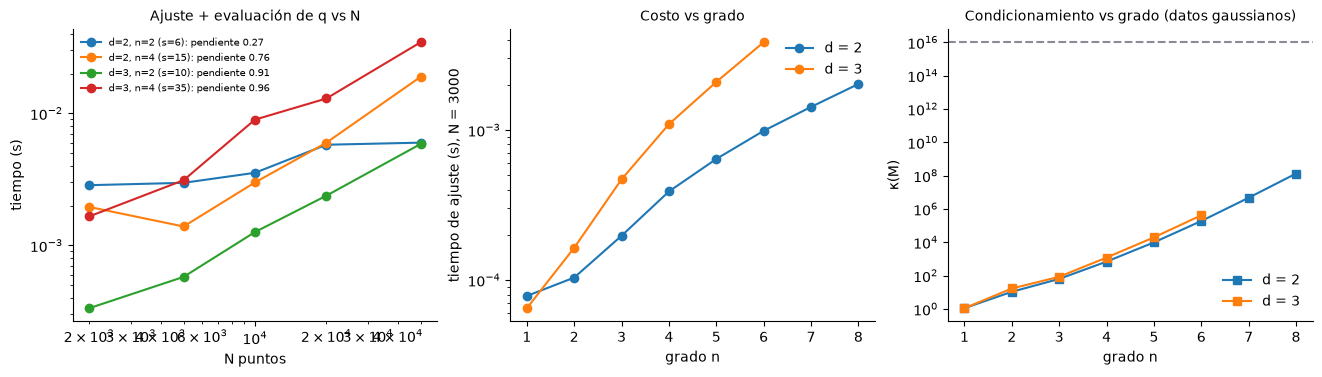

**Costo y condicionamiento por grado (N = 3000)**

s  tiempo (s)  memoria (MB)          κ(M)
d n                                            
2 1   3       0.000         0.070  1.108000e+00
  2   6       0.000         0.138  1.061500e+01
  3  10       0.000         0.231  6.293100e+01
  4  15       0.000         0.347  6.862810e+02
  5  21       0.001         0.488  9.763939e+03
  6  28       0.001         0.653  1.867038e+05
  7  36       0.001         0.845  4.659045e+06
  8  45       0.002         1.063  1.312201e+08
3 1   4       0.000         0.092  1.099000e+00
  2  10       0.000         0.231  1.674500e+01
  3  20       0.000         0.464  8.429000e+01
  4  35       0.001         0.820  1.201901e+03
  5  56       0.002         1.330  1.954783e+04
  6  84       0.004         2.031  4.120214e+05

pendientes log-log (tiempo vs N): {'d=2, n=2': np.float64(0.27), 'd=2, n=4': np.float64(0.76), 'd=3, n=2': np.float64(0.91), 'd=3, n=4': np.float64(0.96)}
✔ el ajuste global de CD crece a lo sumo de forma aproximadamente lineal en N (pendiente < 1.3)


In [137]:
def ajuste_pendiente(x, y):
    return np.polyfit(np.log(x), np.log(y), 1)[0]

Ns = [2000, 5000, 10000, 20000, 50000] + ([100000, 200000] if not RAPIDO else [])

def tiempo_min(fn, repeticiones=3):
    "Mínimo de varias repeticiones sin tracemalloc (el tiempo más representativo del costo del algoritmo)."
    mejores = []
    for _ in range(repeticiones):
        t0 = time.perf_counter(); fn(); mejores.append(time.perf_counter() - t0)
    return min(mejores)
filas = []
for d, n in ((2, 2), (2, 4), (3, 2), (3, 4)):
    for N in Ns:
        Xn = np.random.default_rng(N).normal(size=(N, d))
        def ajuste_y_evaluacion():
            m_ = ajustar_cd(Xn, n, 1e-8); return q_cd(m_, Xn)
        _, _, mb = medir(ajuste_y_evaluacion)
        dt = tiempo_min(ajuste_y_evaluacion)
        filas.append({"d": d, "n": n, "s": tamano_base(d, n), "N": N, "tiempo (s)": dt, "memoria (MB)": mb})
        registrar(experimento="escalabilidad_cd", dataset=f"d={d}, n={n}", método="CD ajuste + q", N=N, **{"tiempo (s)": dt, "memoria (MB)": mb})
esc_n = pd.DataFrame(filas)

filas = []
for d, grados in ((2, range(1, 9)), (3, range(1, 7))):
    Xg = np.random.default_rng(0).normal(size=(3000, d))
    for n in grados:
        (m_, _, mb) = medir(ajustar_cd, Xg, n, 1e-8)
        dt = tiempo_min(lambda: ajustar_cd(Xg, n, 1e-8))
        e = np.linalg.eigvalsh(m_["M"])
        filas.append({"d": d, "n": n, "s": m_["s"], "tiempo (s)": dt, "memoria (MB)": mb, "κ(M)": e.max() / max(e.min(), 1e-300)})
esc_g = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for (d, n), g in esc_n.groupby(["d", "n"]):
    ax[0].loglog(g.N, g["tiempo (s)"], "o-", label=f"d={d}, n={n} (s={tamano_base(d, n)}): pendiente {ajuste_pendiente(g.N, g['tiempo (s)']):.2f}")
ax[0].set_xlabel("N puntos"); ax[0].set_ylabel("tiempo (s)"); ax[0].set_title("Ajuste + evaluación de q vs N"); ax[0].legend(fontsize=7)
for d, g in esc_g.groupby("d"):
    ax[1].semilogy(g.n, g["tiempo (s)"], "o-", label=f"d = {d}")
    ax[2].semilogy(g.n, g["κ(M)"], "s-", label=f"d = {d}")
ax[1].set_xlabel("grado n"); ax[1].set_ylabel("tiempo de ajuste (s), N = 3000"); ax[1].legend(); ax[1].set_title("Costo vs grado")
ax[2].axhline(1e16, ls="--", color=GRIS); ax[2].set_xlabel("grado n"); ax[2].set_ylabel("κ(M)"); ax[2].legend(); ax[2].set_title("Condicionamiento vs grado (datos gaussianos)")
guardar(fig, "escalabilidad_cd", "6.3 Limitaciones (costo)")
plt.show()
tabla(esc_g.set_index(["d", "n"]), 3, "Costo y condicionamiento por grado (N = 3000)")
pend_cd = {f"d={d}, n={n}": ajuste_pendiente(g.N, g["tiempo (s)"]) for (d, n), g in esc_n.groupby(["d", "n"])}
print("pendientes log-log (tiempo vs N):", {k: round(v, 2) for k, v in pend_cd.items()})
verifica(all(v < 1.3 for v in pend_cd.values()), "el ajuste global de CD crece a lo sumo de forma aproximadamente lineal en N (pendiente < 1.3)")

**Interpretación.** Con $d$ y $n$ fijos, el ajuste global de CD crece como mucho linealmente con $N$ (pendientes impresas arriba; con pocos puntos el costo fijo de la factorización domina y la pendiente es menor que 1): sólo hay que acumular $V^\top V$. El costo explota con el grado a través de $s$ y del condicionamiento. En cambio, lo que es cuadrático o cúbico en $N$ son los pasos que construyen matrices $N\times N$: el agrupamiento espectral (V1, V2, Spectral) y las correlaciones del descriptor.

[figura 47] 47_escalabilidad_agrupamiento.png  →  6.3 Limitaciones (costo)


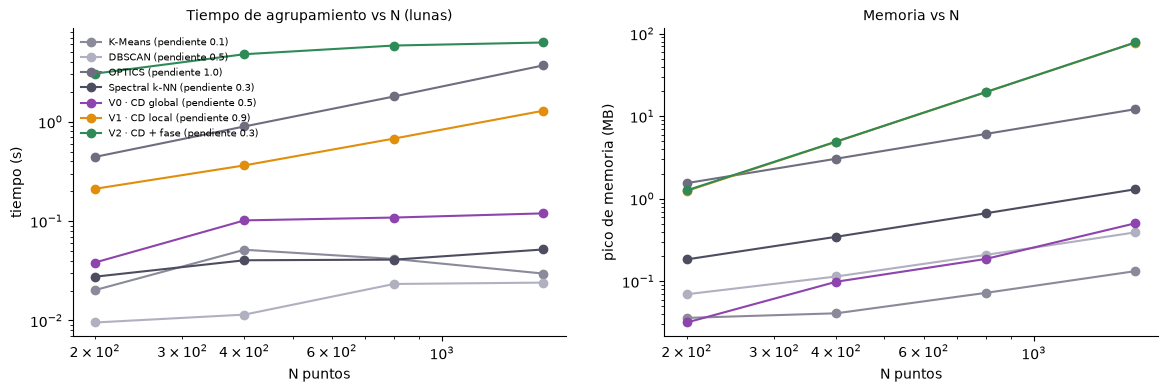

**Tiempo de agrupamiento (s)**

método,DBSCAN,K-Means,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local,V2 · CD + fase
N,,,,,,,
200,0.010,0.020,0.443,0.028,0.038,0.211,3.053
400,0.011,0.051,0.897,0.040,0.102,0.364,4.786
800,0.023,0.042,1.796,0.041,0.109,0.677,5.850
1600,0.024,0.030,3.693,0.052,0.120,1.292,6.277


**Tiempo por objeto de cada descriptor (ms)**

descriptor,CD_U,D2,M_U
puntos,,,
128,12.25,4.62,5.66
256,17.07,4.82,9.62
512,128.42,3.71,28.47
1024,240.61,3.53,67.91
2048,550.06,10.04,401.29


**Pico de memoria por objeto (MB)**

descriptor,CD_U,D2,M_U
puntos,,,
128,0.83,1.53,0.51
256,3.28,1.53,2.02
512,13.04,1.54,8.04
1024,49.61,1.55,32.08
2048,193.69,1.57,128.16


In [138]:
tams = [100, 200, 400, 800] + ([1600] if not RAPIDO else [])
filas = []
for npg in tams:
    d_ = cargar_2d("no_convexo", "base", 100, n=npg)
    for nombre, f in METODOS_CLUSTER.items():
        _, dt, mb = medir(f, d_.X, d_.n_groups)
        filas.append({"N": d_.n_points, "método": nombre, "tiempo (s)": dt, "memoria (MB)": mb})
        registrar(experimento="escalabilidad_agrupamiento", dataset="no_convexo", método=nombre, N=d_.n_points, **{"tiempo (s)": dt, "memoria (MB)": mb})
esc_c = pd.DataFrame(filas)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nombre, g in esc_c.groupby("método", sort=False):
    ax[0].loglog(g.N, g["tiempo (s)"], "o-", color=COLOR_METODO[nombre], label=f"{nombre} (pendiente {ajuste_pendiente(g.N, g['tiempo (s)']):.1f})")
    ax[1].loglog(g.N, np.maximum(g["memoria (MB)"], 1e-3), "o-", color=COLOR_METODO[nombre], label=nombre)
ax[0].set_xlabel("N puntos"); ax[0].set_ylabel("tiempo (s)"); ax[0].legend(fontsize=7); ax[0].set_title("Tiempo de agrupamiento vs N (lunas)")
ax[1].set_xlabel("N puntos"); ax[1].set_ylabel("pico de memoria (MB)"); ax[1].set_title("Memoria vs N")
guardar(fig, "escalabilidad_agrupamiento", "6.3 Limitaciones (costo)")
plt.show()
tabla(esc_c.pivot(index="N", columns="método", values="tiempo (s)"), 3, "Tiempo de agrupamiento (s)")

filas = []
X_obj = make_object("torus", 3, 4096, np.random.default_rng(0), transform=False)
for npts in (128, 256, 512, 1024, 2048):
    Xs_ = X_obj[:npts]
    for nombre, f in (("CD_U", descriptor_cd), ("M_U", descriptor_momentos), ("D2", descriptor_d2)):
        _, dt, mb = medir(f, Xs_)
        filas.append({"puntos": npts, "descriptor": nombre, "tiempo (ms)": 1000 * dt, "memoria (MB)": mb})
esc_d = pd.DataFrame(filas)
tabla(esc_d.pivot(index="puntos", columns="descriptor", values="tiempo (ms)"), 2, "Tiempo por objeto de cada descriptor (ms)")
tabla(esc_d.pivot(index="puntos", columns="descriptor", values="memoria (MB)"), 2, "Pico de memoria por objeto (MB)")

**Interpretación.** CD_U es el descriptor más caro porque forma el núcleo entre todos los pares ($O(N^2)$ en tiempo y memoria); con 512 puntos (el tamaño usado en la tesis) sigue siendo del orden de milisegundos por objeto. M_U y D2 son lineales en $N$. En agrupamiento, los métodos basados en grafos densos (Spectral, V1, V2) crecen claramente más rápido que K-Means, y V2 agrega la búsqueda de fase.

---
# **9. Resultados globales y conclusiones**

Todas las tablas de esta sección se construyen a partir del registro `REG` (cada fila es una ejecución identificable de este cuaderno). Las frases marcadas como *generadas* se escriben con código a partir de esos números, de modo que siempre describen la ejecución actual.

## **9.1 Tabla global de agrupamiento**

In [139]:
REGDF = pd.DataFrame(REG)
cl = REGDF[REGDF.experimento == "agrupamiento_2d"]
glob = cl.pivot_table(index="método", columns="variante", values="ARI").reindex(index=list(METODOS_CLUSTER), columns=CONFIG["VARIANTES_2D"])
glob["promedio"] = glob.mean(1)
glob["NMI medio"] = cl.groupby("método").NMI.mean()
glob["tiempo medio (s)"] = cl.groupby("método")["tiempo (s)"].mean()
tabla(glob.sort_values("promedio", ascending=False), 3, "Agrupamiento 2D · ARI medio por variante (6 escenarios)")

por_caso = cl[cl.variante == "base"].pivot_table(index="dataset", columns="método", values="ARI").reindex(index=CASOS_2D, columns=list(METODOS_CLUSTER))
tabla(por_caso, 2, "Agrupamiento 2D · ARI por escenario (sin perturbar)")

c3 = REGDF[REGDF.experimento == "agrupamiento_3d"].pivot_table(index="dataset", columns="método", values="ARI").reindex(columns=list(METODOS_3D))
tabla(c3, 2, "Escenas 3D · ARI medio (sin perturbar, ruido y oclusión)")

emb = REGDF[REGDF.experimento == "embedding"].groupby("método")[["T", "C", "kNN_acc", "tiempo (s)"]].mean().reindex(list(METODOS_EMB))
tabla(emb, 3, "Embeddings · promedio de los cuatro escenarios enrollados")

**Agrupamiento 2D · ARI medio por variante (6 escenarios)**

variante,base,ruido,oclusion,densidad_variable,promedio,NMI medio,tiempo medio (s)
método,,,,,,,
V2 · CD + fase,0.961,0.575,0.612,0.578,0.682,0.690,4.221
V1 · CD local,0.675,0.574,0.612,0.578,0.610,0.633,0.267
Spectral k-NN,0.706,0.545,0.493,0.545,0.572,0.602,0.036
DBSCAN,0.400,0.488,0.475,0.455,0.455,0.558,0.011
V0 · CD global,0.268,0.230,0.190,0.255,0.236,0.243,0.067
OPTICS,0.254,0.311,0.178,0.198,0.235,0.397,0.675
K-Means,0.228,0.228,0.173,0.258,0.222,0.204,0.036


**Agrupamiento 2D · ARI por escenario (sin perturbar)**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local,V2 · CD + fase
dataset,,,,,,,
compacto,0.90,0.86,0.49,0.90,0.92,0.91,0.91
no_convexo,0.30,0.38,0.18,1.00,0.51,1.00,1.00
entrelazado,0.07,0.19,0.13,0.46,0.07,0.24,1.00
anidado,-0.00,0.55,0.27,1.00,-0.00,1.00,1.00
espiral_3brazos,0.04,0.28,0.32,0.21,0.04,0.24,1.00
espiral_log,0.06,0.14,0.12,0.66,0.08,0.66,0.86


**Escenas 3D · ARI medio (sin perturbar, ruido y oclusión)**

método,K-Means,DBSCAN,OPTICS,Spectral k-NN,V0 · CD global,V1 · CD local
dataset,,,,,,
esfera_cubo_piramide,1.0,0.93,1.00,1.0,1.00,1.0
esferas_anidadas,-0.0,0.75,0.94,1.0,-0.00,1.0
toro_y_esfera,0.0,0.78,0.63,1.0,0.01,1.0


**Embeddings · promedio de los cuatro escenarios enrollados**

,T,C,kNN_acc,tiempo (s)
método,,,,
PCA,0.806,0.956,0.773,0.002
Kernel PCA (RBF),0.798,0.952,0.776,0.012
Isomap,0.836,0.961,0.857,0.053
Laplacian Eigenmaps,0.833,0.939,0.809,0.018
CD local,0.840,0.936,0.808,0.185


In [140]:
display(Markdown("**Hallazgos de agrupamiento (generados)**"))
lineas = []
for caso in CASOS_2D:
    fila = por_caso.loc[caso]; mejor = fila.max(); ganadores = list(fila[fila >= mejor - 0.01].index)
    cd_ = {v: fila[v] for v in ("V0 · CD global", "V1 · CD local", "V2 · CD + fase")}
    lineas.append(f"- **{caso}**: mejor ARI {mejor:.2f} ({', '.join(ganadores)}); V0 {cd_['V0 · CD global']:.2f}, V1 {cd_['V1 · CD local']:.2f}, V2 {cd_['V2 · CD + fase']:.2f}.")
v2 = glob.loc["V2 · CD + fase"]
mejor_ref = glob.drop(index=[m for m in glob.index if m.startswith("V")])["base"]
lineas.append(f"- Sin perturbar (promedio de los 6 escenarios), V2 obtiene ARI {v2['base']:.2f} frente a {mejor_ref.max():.2f} del mejor método de referencia ({mejor_ref.idxmax()}).")
for var in CONFIG["VARIANTES_2D"][1:]:
    lineas.append(f"- Con **{var}**, V2 pasa de {v2['base']:.2f} a {v2[var]:.2f} de ARI medio; el mejor método en esa variante es {glob[var].idxmax()} ({glob[var].max():.2f}).")
display(Markdown("\n".join(lineas)))

**Hallazgos de agrupamiento (generados)**

- **compacto**: mejor ARI 0.92 (V0 · CD global, V1 · CD local, V2 · CD + fase); V0 0.92, V1 0.91, V2 0.91.
- **no_convexo**: mejor ARI 1.00 (Spectral k-NN, V1 · CD local, V2 · CD + fase); V0 0.51, V1 1.00, V2 1.00.
- **entrelazado**: mejor ARI 1.00 (V2 · CD + fase); V0 0.07, V1 0.24, V2 1.00.
- **anidado**: mejor ARI 1.00 (Spectral k-NN, V1 · CD local, V2 · CD + fase); V0 -0.00, V1 1.00, V2 1.00.
- **espiral_3brazos**: mejor ARI 1.00 (V2 · CD + fase); V0 0.04, V1 0.24, V2 1.00.
- **espiral_log**: mejor ARI 0.86 (V2 · CD + fase); V0 0.08, V1 0.66, V2 0.86.
- Sin perturbar (promedio de los 6 escenarios), V2 obtiene ARI 0.96 frente a 0.71 del mejor método de referencia (Spectral k-NN).
- Con **ruido**, V2 pasa de 0.96 a 0.57 de ARI medio; el mejor método en esa variante es V2 · CD + fase (0.57).
- Con **oclusion**, V2 pasa de 0.96 a 0.61 de ARI medio; el mejor método en esa variante es V1 · CD local (0.61).
- Con **densidad_variable**, V2 pasa de 0.96 a 0.58 de ARI medio; el mejor método en esa variante es V1 · CD local (0.58).

## **9.2 Comparación entre versiones de Christoffel–Darboux**

In [141]:
ver = cl[cl["método"].str.startswith("V")].pivot_table(index="dataset", columns=["método", "variante"], values="ARI")
tabla(ver.reindex(CASOS_2D), 2, "V0 → V1 → V2 por escenario y variante")
abl_res = ABL.groupby(["método", "variante"]).ARI.mean().unstack()[["base", "ruido"]].reindex(ABL["método"].unique())
tabla(abl_res, 3, "Ablación (promedio de los 6 escenarios)")
r_ = abl_res["base"]
display(Markdown("\n".join([
    "**Lectura de la ablación (generada)**",
    f"- Quitar los pesos CD (grafo binario con el mismo espectral) cambia el ARI medio sin perturbar de {r_['V1 (pesos CD)']:.2f} a {r_['binario + espectral V1']:.2f}.",
    f"- La fase sola con K-Means obtiene {r_['fase sola + K-Means']:.2f}; V2 completo, {r_['V2']:.2f}: en las espirales el mérito principal es de la coordenada de fase.",
    f"- Sin compuerta, V2 obtiene {abl_res.loc['V2 sin compuerta', 'ruido']:.2f} con ruido frente a {abl_res.loc['V2', 'ruido']:.2f} con compuerta."])))

**V0 → V1 → V2 por escenario y variante**

método          V0 · CD global                                  V1 · CD local  \
variante                  base densidad_variable oclusion ruido          base   
dataset                                                                         
compacto                  0.92              0.94     0.92  0.93          0.91   
no_convexo                0.51              0.12     0.18  0.28          1.00   
entrelazado               0.07              0.03    -0.00  0.06          0.24   
anidado                  -0.00              0.24     0.02 -0.00          1.00   
espiral_3brazos           0.04              0.06     0.02  0.05          0.24   
espiral_log               0.08              0.13     0.01  0.06          0.66   

método                                           V2 · CD + fase  \
variante        densidad_variable oclusion ruido           base   
dataset                                                           
compacto                     0.95     0.81  0.93           0.91   
no_convexo                   1.00     1.00  1.00           1.00   
entrelazado                  0.25     0.29  0.06           1.00   
anidado                      0.91     1.00  1.00           1.00   
espiral_3brazos              0.12     0.23  0.13           1.00   
espiral_log                  0.24     0.34  0.33           0.86   

método                                            
variante        densidad_variable oclusion ruido  
dataset                                           
compacto                     0.95     0.81  0.93  
no_convexo                   1.00     1.00  0.97  
entrelazado                  0.25     0.29  0.06  
anidado                      0.91     1.00  1.00  
espiral_3brazos              0.12     0.23  0.13  
espiral_log                  0.24     0.34  0.36

**Ablación (promedio de los 6 escenarios)**

variante,base,ruido
método,,
Spectral k-NN,0.706,0.545
binario + espectral V1,0.662,0.511
V1 (pesos CD),0.675,0.574
V1 peso monótono,0.676,0.575
V1 grado local 2,0.721,0.572
fase sola + K-Means,0.789,0.767
V2 sin compuerta,0.961,0.784
V2,0.961,0.575


**Lectura de la ablación (generada)**
- Quitar los pesos CD (grafo binario con el mismo espectral) cambia el ARI medio sin perturbar de 0.68 a 0.66.
- La fase sola con K-Means obtiene 0.79; V2 completo, 0.96: en las espirales el mérito principal es de la coordenada de fase.
- Sin compuerta, V2 obtiene 0.78 con ruido frente a 0.57 con compuerta.

## **9.3 Descriptores de objetos: sintéticos y ModelNet**

In [142]:
bloques = []
for nombre, res in [("sintéticos 3D", RES_OBJ.get(3)), ("sintéticos 2D", RES_OBJ.get(2)),
                    ("ModelNet10", RES_MN.get("modelnet10")), ("ModelNet40", RES_MN.get("modelnet40"))]:
    if res is None:
        display(Markdown(f"- **{nombre}**: no evaluado en esta ejecución (dataset no disponible)."))
        continue
    T = res["tabla"].pivot(index="método", columns="variante", values="mAP").reindex(columns=[c for c in CONDICIONES if c in res["tabla"].variante.unique()])
    T.insert(0, "dataset", nombre); bloques.append(T.reset_index())
    C = res["contrastes"]; c1 = C[C.contraste.str.startswith("CD_U")]
    gana = c1[c1["IC bajo"] > 0].condición.tolist(); pierde = c1[c1["IC alto"] < 0].condición.tolist()
    empata = [c for c in c1.condición if c not in gana + pierde]
    display(Markdown(f"- **{nombre}** (generado): CD_U+métrica − M_U+métrica es positivo con IC > 0 en {gana or 'ninguna condición'}; "
                     f"negativo con IC < 0 en {pierde or 'ninguna'}; indistinguible de 0 en {empata or 'ninguna'}."))
if bloques:
    tabla(pd.concat(bloques).set_index(["dataset", "método"]), 3, "mAP por dataset, descriptor y condición")

- **sintéticos 3D** (generado): CD_U+métrica − M_U+métrica es positivo con IC > 0 en ['limpio', 'ruido', 'densidad', 'oclusión', 'atípicos']; negativo con IC < 0 en ninguna; indistinguible de 0 en ninguna.

- **sintéticos 2D** (generado): CD_U+métrica − M_U+métrica es positivo con IC > 0 en ['limpio', 'ruido', 'densidad', 'oclusión', 'atípicos']; negativo con IC < 0 en ninguna; indistinguible de 0 en ninguna.

- **ModelNet10**: no evaluado en esta ejecución (dataset no disponible).

- **ModelNet40**: no evaluado en esta ejecución (dataset no disponible).

**mAP por dataset, descriptor y condición**

variante                    limpio  ruido  densidad  oclusión  atípicos
dataset       método                                                   
sintéticos 3D CD_U           0.923  0.916     0.478     0.699     0.678
              CD_U+métrica   0.966  0.961     0.913     0.888     0.740
              CD_W           0.917  0.910     0.590     0.739     0.371
              CD_W+métrica   0.961  0.949     0.935     0.918     0.365
              D2             0.751  0.751     0.605     0.674     0.720
              M_U            0.856  0.856     0.450     0.580     0.529
              M_U+métrica    0.900  0.896     0.873     0.776     0.553
sintéticos 2D CD_U           0.886  0.862     0.413     0.538     0.755
              CD_U+métrica   0.925  0.904     0.838     0.819     0.858
              CD_W           0.890  0.866     0.415     0.554     0.553
              CD_W+métrica   0.927  0.903     0.827     0.855     0.706
              D2             0.736  0.735     0.485     0.633     0.736
              M_U            0.804  0.806     0.370     0.420     0.638
              M_U+métrica    0.869  0.872     0.669     0.617     0.641

## **9.4 Robustez y escalabilidad**

In [143]:
rob2 = cl.groupby(["método", "variante"]).ARI.mean().unstack()[CONFIG["VARIANTES_2D"]].reindex(list(METODOS_CLUSTER))
rob2 = rob2.sub(rob2["base"], axis=0).drop(columns="base")
tabla(rob2, 3, "Pérdida media de ARI por perturbación (agrupamiento 2D)")
pend = {f"CD global d={d}, n={n}": ajuste_pendiente(g.N, g["tiempo (s)"]) for (d, n), g in esc_n.groupby(["d", "n"])}
pend.update({nombre: ajuste_pendiente(g.N, g["tiempo (s)"]) for nombre, g in esc_c.groupby("método")})
tabla(pd.Series(pend, name="pendiente log-log del tiempo vs N").to_frame(), 2, "Escalabilidad empírica")

**Pérdida media de ARI por perturbación (agrupamiento 2D)**

variante,ruido,oclusion,densidad_variable
método,,,
K-Means,0.001,-0.055,0.030
DBSCAN,0.088,0.074,0.055
OPTICS,0.057,-0.076,-0.056
Spectral k-NN,-0.161,-0.213,-0.161
V0 · CD global,-0.038,-0.078,-0.013
V1 · CD local,-0.102,-0.063,-0.097
V2 · CD + fase,-0.387,-0.349,-0.383


**Escalabilidad empírica**

,pendiente log-log del tiempo vs N
"CD global d=2, n=2",0.27
"CD global d=2, n=4",0.76
"CD global d=3, n=2",0.91
"CD global d=3, n=4",0.96
DBSCAN,0.50
K-Means,0.14
OPTICS,1.02
Spectral k-NN,0.28
V0 · CD global,0.50
V1 · CD local,0.87


## **9.5 Dónde funciona mejor y peor el método propuesto**

Con base en las tablas anteriores (revisar que las frases generadas de §9.1–9.3 las respalden en cada ejecución):

**Funciona mejor**
* **Estimación de soporte**: desde grado 2 los conjuntos de nivel de $q$ separan huecos que Mahalanobis no ve, y $q$ sirve como puntaje de atípico (§1.11).
* **Agrupamiento de estructuras enrolladas limpias**: V2 resuelve las espirales, incluidas las reservadas; la ablación muestra que el mérito es de la coordenada de fase.
* **Descriptores invariantes**: CD_U es exactamente invariante a semejanzas y reflexiones, y en los datos reales su ventaja frente al control de momentos aparece, cuando aparece, con nubes **incompletas o contaminadas** (oclusión, atípicos; ver §9.3).

**Funciona peor**
* **CD global** como modelo de grupo: equivale a K-Means con cónicas.
* **Perturbaciones que mueven el centro** (oclusión, densidad variable): la compuerta de fase se cierra y V2 vuelve a V1.
* **Datos limpios y bien muestreados en ModelNet**: el descriptor CD no supera al control de momentos con la misma información.
* **Costo**: los pasos con matrices $N\times N$ (espectral, correlaciones del descriptor) dominan el tiempo y la memoria.

## **9.6 Limitaciones**

1. Los escenarios 2D y las familias 3D son sintéticos y pocos; los benchmarks de agrupamiento usan $k$ real para los métodos que lo requieren.
2. La normalización por centro y radio RMS no es robusta: valores atípicos y oclusión desplazan el centro y la escala.
3. El condicionamiento de $M_n$ limita el grado útil a $n\le4$ en 2D y 3D.
4. El descriptor es invariante a reflexiones: no distingue objetos quirales de su imagen especular.
5. ModelNet aproxima LiDAR con muestreo uniforme más perturbaciones; no se evaluaron escaneos reales.
6. Los hiperparámetros de los comparadores son los de la tesis (fijos); el oráculo de la tesis muestra que con otro valor algunos comparadores mejoran.

## **9.7 Posibles contribuciones científicas**

* Una implementación **numéricamente estable** de la función de Christoffel–Darboux (regularización relativa a la traza y Cholesky) con la demostración, en un caso mínimo, de que la pseudoinversa produce resultados incorrectos cuando el soporte es una variedad algebraica.
* Un **protocolo de evaluación con controles**: el descriptor de momentos M_U y las ablaciones separan el efecto de CD del de la información de momentos, del grafo y de la métrica.
* Un **descriptor de objeto exactamente invariante** basado en CD, con evidencia acotada y replicada de en qué condiciones aporta.
* **Resultados negativos documentados**: el descriptor promediado sobre rotaciones, CD global para formas no convexas y la ausencia de ventaja de CD en datos limpios.

In [144]:
ok = sum(v for v, _ in VERIF)
print(f"Verificaciones: {ok} de {len(VERIF)} correctas")
verifica(ok == len(VERIF), "todas las verificaciones del cuaderno pasaron")
REGDF = pd.DataFrame(REG)
salida = RAIZ / "notebooks" / f"resultados_cuaderno_{MODO}.csv"
REGDF.to_csv(salida, index=False)
print(f"Registro de {len(REGDF)} ejecuciones guardado en {salida.relative_to(RAIZ)}")
tabla(REGDF.groupby("experimento").size().to_frame("filas en el registro"), 0)
tabla(pd.DataFrame(FIGS, columns=["figura", "sección de la tesis"]), 0, f"{len(FIGS)} figuras guardadas en notebooks/figuras_tesis/")

Verificaciones: 108 de 108 correctas
✔ todas las verificaciones del cuaderno pasaron
Registro de 378 ejecuciones guardado en notebooks/resultados_cuaderno_completo.csv


,filas en el registro
experimento,
agrupamiento_2d,168
agrupamiento_3d,54
embedding,20
escalabilidad_agrupamiento,28
escalabilidad_cd,20
sinteticos_2d,35
sinteticos_2d_agrupamiento_descriptores,9
sinteticos_3d,35
sinteticos_3d_agrupamiento_descriptores,9


**47 figuras guardadas en notebooks/figuras_tesis/**

,figura,sección de la tesis
0,01_identidad_cd_1d.png,2.5.2 Kernel CD e identidad de Christoffel–Dar...
1,02_christoffel_1d_variacional.png,2.5.1 Definición y 2.5.3 Formulación variacional
2,03_condicionamiento_regularizacion.png,2.5.4 Singularidad y regularización
3,04_campos_q_escenarios.png,5.1 Estimación de soporte (escenarios)
4,05_toro_campo_atipicos.png,2.6 Aplicaciones (soporte y anomalías en 3D)
5,06_lambda_distribucion_1d.png,2.5.5 Interpretación geométrica
6,07_embedding_global_vs_local.png,4.4 Agrupamiento basado en CD (motivación)
7,08_escenarios_2d_distribucion.png,3.3 Datos (escenarios 2D)
8,09_perturbaciones_2d.png,3.3 Datos (perturbaciones)
9,10_transformaciones_2d.png,3.3 Datos (transformaciones)
